In [7]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
JADE + WAVES (+ MAG) batch driver

For each JADE LBL file:
  1) Run JADE analysis to produce:
       - JADE spectrogram + summed band time series + LS periodogram (saved)
       - f_pe(t) from JADE number flux (returned as Hz) + t_unix (s)
       - the exact segment start/end actually used (ISO strings)
  2) Use that same segment time window to fetch Juno WAVES via DAS2:
       - LFRH spectrogram
       - LHRL spectrogram
       - Magnetic spectrogram (b=True)
       - whistler-band summed ESD + LS periodogram
       - overlays of f_pe (JADE) + (optional) f_ce (FGM) + derived f_z, f_UHR

Notes / fixes vs your snippet:
  - Your JADE save filenames said “_khz” and header “f_pe_kHz” but the values are Hz.
    This script saves as *_fpe_time_hz.* with header unix_time_s,f_pe_Hz.
  - Your JADE ephemeris fetch used START_TIME/END_TIME globals even when a smaller window is selected.
    This script uses the *actual* seg_start_iso/seg_end_iso used for the plot.
  - The JADE function now returns: (fpe_hz, t_unix, seg_start_iso, seg_end_iso)

Dependencies:
  pip install pdr das2 astropy scipy pandas matplotlib
"""

# ──────────────────────────────────────────────────────────────────────────────
# ENV / IMPORTS
# ──────────────────────────────────────────────────────────────────────────────
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FixedLocator
from matplotlib.gridspec import GridSpec
from scipy.signal import find_peaks

from astropy.timeseries import LombScargle
from das2 import get_source
import das2
import pdr

# Avoid CPU oversubscription (macOS / BLAS/FFT libs)
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("VECLIB_MAXIMUM_THREADS", "1")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")

# ──────────────────────────────────────────────────────────────────────────────
# GLOBAL CONFIG
# ──────────────────────────────────────────────────────────────────────────────
# Output folders
JADE_FIG_OUTDIR  = "JADE_FIGS"
WAVES_FIG_OUTDIR = "WAVES_FIGS"
os.makedirs(JADE_FIG_OUTDIR,  exist_ok=True)
os.makedirs(WAVES_FIG_OUTDIR, exist_ok=True)

# --- WAVES DAS2 server ---
SERVER_URL_WAVES = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"
SERVER_URL_EFC   = "tag:das2.org,2012:site:/uiowa/juno/fgm/electroncyclotron/das2"
SERVER_URL_EPH   = "tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2"

# --- Whistler band limits (Hz) ---
WHIS_MIN = 300.0
WHIS_MAX = 3000.0

# --- JADE analysis defaults ---
ENERGY_MIN_EV    = 45.0
ENERGY_MAX_EV    = 8000.0

# Periodogram settings (minutes)
PERIOD_MIN       = 1.0
PERIOD_MAX       = 15.0
PEAK_DETECT_MIN  = 2.5
NUM_PEAKS        = 4
LS_NFREQ         = 5000

# WAVES plot defaults (Hz axes are Hz)
LFRH_YLIM   = (2e4, 2e5)
LHRL_YLIM   = (5e1, 2e4)
B_YLIM      = (5e1, 2e4)

LFRH_LOGNORM = (1e-14, 1e-11)
LHRL_LOGNORM = (1e-14, 1e-8)
B_LOGNORM    = (1e-9, 1e-4)

# Overlays
OVERLAY_LW    = 1.0
OVERLAY_ALPHA = 0.9
PLOT_FCE_FZ_FUHR = True

# ──────────────────────────────────────────────────────────────────────────────
# JADE CONSTANTS (your hard-coded 64 energy centers)
# ──────────────────────────────────────────────────────────────────────────────
ENERGY_BINS_EV = np.array([
    4.5731E+001, 5.3296E+001, 6.0349E+001, 6.8611E+001, 7.7419E+001,
    8.9858E+001, 1.0039E+002, 1.1494E+002, 1.2908E+002, 1.4807E+002,
    1.6538E+002, 1.8943E+002, 2.1210E+002, 2.4241E+002, 2.7057E+002,
    3.0856E+002, 3.4290E+002, 3.9006E+002, 4.3681E+002, 4.9299E+002,
    5.5223E+002, 6.2153E+002, 6.9798E+002, 7.8441E+002, 8.8190E+002,
    9.9458E+002, 1.1175E+003, 1.2632E+003, 1.4210E+003, 1.6066E+003,
    1.8068E+003, 2.0410E+003, 2.2617E+003, 2.5464E+003, 2.9011E+003,
    3.2921E+003, 3.7061E+003, 4.1751E+003, 4.7001E+003, 5.2996E+003,
    5.9765E+003, 6.7664E+003, 7.6124E+003, 8.5852E+003, 9.6487E+003,
    1.0927E+004, 1.2282E+004, 1.3872E+004, 1.5623E+004, 1.7610E+004,
    1.9783E+004, 2.2346E+004, 2.5209E+004, 2.8414E+004, 3.2039E+004,
    3.6123E+004, 4.0668E+004, 4.5886E+004, 5.1684E+004, 5.8298E+004,
    6.5677E+004, 7.4021E+004, 8.3346E+004, 9.3975E+004
], dtype=float)

N_E, N_LOOK = 64, 48
N_COLS = N_E * N_LOOK


# ──────────────────────────────────────────────────────────────────────────────
# JADE HELPERS
# ──────────────────────────────────────────────────────────────────────────────
def energy_edges_from_centers(e):
    """Geometric midpoints; extrapolated outer edges."""
    e = np.asarray(e, float)
    mids = np.sqrt(e[:-1] * e[1:])
    return np.concatenate([[e[0]**2 / mids[0]], mids, [e[-1]**2 / mids[-1]]])


def load_jade_cube(lbl_path):
    ds = pdr.read(lbl_path)
    df = ds["TABLE"]

    t_lo = pd.to_datetime(df["DIM0_UTC_LOWER"].astype(str), format="%Y-%jT%H:%M:%S.%f", utc=False)
    t_hi = pd.to_datetime(df["DIM0_UTC_UPPER"].astype(str), format="%Y-%jT%H:%M:%S.%f", utc=False)

    pat = re.compile(r"^DATA_(\d+)$", re.IGNORECASE)
    pairs = []
    for c in df.columns:
        m = pat.match(str(c))
        if m:
            pairs.append((int(m.group(1)), c))
    pairs.sort(key=lambda x: x[0])
    data_cols = [c for _, c in pairs]
    if len(data_cols) != N_COLS:
        raise ValueError(f"Expected {N_COLS} DATA columns, got {len(data_cols)}")

    raw = df[data_cols].to_numpy(dtype=float)
    raw[raw <= -9.0e5] = np.nan

    nt = len(df)
    cube = raw.reshape(nt, N_E, N_LOOK)  # (T, 64, 48)
    Z_mean = np.nanmean(cube, axis=2)    # (T, 64)

    mask = t_lo.notna() & t_hi.notna()
    t_lo = t_lo[mask].reset_index(drop=True)
    t_hi = t_hi[mask].reset_index(drop=True)
    Z_mean = Z_mean[mask.values, :]

    ord_idx = np.argsort(t_lo.values)
    t_lo = t_lo.iloc[ord_idx].reset_index(drop=True)
    t_hi = t_hi.iloc[ord_idx].reset_index(drop=True)
    Z_mean = Z_mean[ord_idx, :]

    t_edges = pd.DatetimeIndex(np.concatenate([t_lo.values[:1], t_hi.values]))
    t_centers = t_lo + (t_hi - t_lo) / 2

    sorter = np.argsort(ENERGY_BINS_EV)
    e_sorted = ENERGY_BINS_EV[sorter]
    Zp = Z_mean[:, sorter]
    e_edges = energy_edges_from_centers(e_sorted)

    return t_edges, t_centers, e_sorted, e_edges, Zp


def summarize_between_lines(e_sorted, Zp, emin_ev, emax_ev):
    mask_e = (e_sorted >= emin_ev) & (e_sorted <= emax_ev)
    if not np.any(mask_e):
        raise ValueError("Energy mask is empty; check ENERGY_MIN_EV/ENERGY_MAX_EV.")
    summed = np.nansum(Zp[:, mask_e], axis=1)
    return summed, mask_e


def _interpolate_nans_time(times_ns, y):
    """Time-based interpolation for NaNs (keeps sampling)."""
    y = np.asarray(y, float)
    if np.all(np.isfinite(y)):
        return y
    s = pd.Series(y, index=pd.to_datetime(times_ns))
    s = s.interpolate(method="time").bfill().ffill()
    return s.to_numpy(dtype=float)


# ──────────────────────────────────────────────────────────────────────────────
# JADE MAIN: plot + compute f_pe(t) + return fpe_hz,t_unix, seg window
# ──────────────────────────────────────────────────────────────────────────────
def make_segment_analysis_from_pds3(
    lbl_path,
    start_time=None,
    end_time=None,
    emin_ev=ENERGY_MIN_EV,
    emax_ev=ENERGY_MAX_EV,
    period_min=PERIOD_MIN,
    period_max=PERIOD_MAX,
    peak_detect_min=PEAK_DETECT_MIN,
    num_peaks=NUM_PEAKS,
    ls_nfreq=LS_NFREQ,
    save_png=True,
    fig_outdir=JADE_FIG_OUTDIR,
    label="segment",
):
    # Load PDS3 + build arrays
    t_edges, t_centers, e_sorted, e_edges, Zp = load_jade_cube(lbl_path)

    # If no window passed, use full file coverage
    if start_time is None or end_time is None:
        t0 = pd.to_datetime(t_centers.iloc[0])
        t1 = pd.to_datetime(t_centers.iloc[-1])
    else:
        t0 = pd.to_datetime(start_time)
        t1 = pd.to_datetime(end_time)

    mask_t = (t_centers >= t0) & (t_centers <= t1)
    if not np.any(mask_t):
        raise ValueError("Time window selects no samples; check start_time/end_time.")

    times_win = t_centers[mask_t].to_numpy(dtype="datetime64[ns]")
    Z_win     = Zp[mask_t.values, :]

    # Actual segment used (ISO strings for WAVES)
    seg_start_iso = pd.to_datetime(times_win[0]).strftime("%Y-%m-%dT%H:%M:%S")
    seg_end_iso   = pd.to_datetime(times_win[-1]).strftime("%Y-%m-%dT%H:%M:%S")

    # Sum between lines
    avg_counts, mask_e = summarize_between_lines(e_sorted, Z_win, emin_ev, emax_ev)
    avg_counts = _interpolate_nans_time(times_win, avg_counts)

    # Detrend linear
    t0c = times_win[0]
    t_sec = (times_win - t0c) / np.timedelta64(1, "s")
    if len(t_sec) < 4:
        raise ValueError("Too few samples in window for periodogram.")
    dt_s = float(np.median(np.diff(t_sec)))
    if not np.isfinite(dt_s) or dt_s <= 0:
        raise ValueError("Non-positive or invalid cadence; check time ordering/data gaps.")

    coeff = np.polyfit(t_sec, avg_counts, 1)
    trend = np.polyval(coeff, t_sec)
    residual = avg_counts - trend
    residual = residual - np.mean(residual)

    # Lomb–Scargle
    fmin = 1.0 / (period_max * 60.0)
    fmax = 1.0 / (period_min * 60.0)
    freq = np.linspace(fmin, fmax, ls_nfreq)

    ls = LombScargle(t_sec, residual, normalization="standard", center_data=False)
    power = ls.power(freq)

    periods_mask = (1.0 / freq) / 60.0
    order = np.argsort(periods_mask)
    periods_ls = periods_mask[order]
    power_ls   = power[order]

    # Peak picking
    peaks, _ = find_peaks(power_ls)
    if peaks.size:
        sel = peaks[np.argsort(power_ls[peaks])][-num_peaks:]
        sel = np.sort(sel)
        peak_periods = periods_ls[sel]
        peak_powers  = power_ls[sel]

        keep = peak_periods >= peak_detect_min
        peak_periods = peak_periods[keep]
        peak_powers  = peak_powers[keep]

        o2 = np.argsort(peak_periods)
        peak_periods = peak_periods[o2]
        peak_powers  = peak_powers[o2]
    else:
        peak_periods = np.array([], dtype=float)
        peak_powers  = np.array([], dtype=float)

    # FAP thresholds
    try:
        thr_10 = ls.false_alarm_level(0.10, method="baluev",
                                     minimum_frequency=fmin, maximum_frequency=fmax)
        thr_01 = ls.false_alarm_level(0.01, method="baluev",
                                     minimum_frequency=fmin, maximum_frequency=fmax)
        fap_method = "baluev"
    except Exception:
        thr_10 = ls.false_alarm_level(0.10, method="naive",
                                     minimum_frequency=fmin, maximum_frequency=fmax)
        thr_01 = ls.false_alarm_level(0.01, method="naive",
                                     minimum_frequency=fmin, maximum_frequency=fmax)
        fap_method = "naive"

    # ───────────── Plot JADE figure ─────────────
    basename = os.path.splitext(os.path.basename(lbl_path))[0]
    fig = plt.figure(figsize=(10.5, 9), dpi=300)
    outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[3, 1], hspace=0.55)
    inner_gs = outer_gs[0].subgridspec(2, 1, height_ratios=[2, 1], hspace=0.0)

    ax_spec = fig.add_subplot(inner_gs[0])
    ax_avg  = fig.add_subplot(inner_gs[1], sharex=ax_spec)
    ax_fft  = fig.add_subplot(outer_gs[1])

    # Spectrogram edges for the window
    idx0 = np.where(t_centers.to_numpy() >= times_win[0])[0][0]
    idx1 = np.where(t_centers.to_numpy() <= times_win[-1])[0][-1]
    t_edges_win = t_edges[idx0: idx1 + 2]

    Zpos = Z_win[np.isfinite(Z_win) & (Z_win > 0)]
    if Zpos.size == 0:
        raise RuntimeError("No positive values to plot.")
    vmin, vmax = np.nanpercentile(Zpos, [5, 95])
    vmin = max(vmin, np.nextafter(0.0, 1.0))

    ax_spec.pcolormesh(
        t_edges_win, e_edges, Z_win.T, shading="auto",
        norm=LogNorm(vmin=vmin, vmax=vmax), cmap="turbo"
    )
    ax_spec.set_yscale("log")
    ax_spec.set_facecolor("black")
    ax_spec.plot([times_win[0], times_win[-1]], [emin_ev, emin_ev], "--w", lw=2)
    ax_spec.plot([times_win[0], times_win[-1]], [emax_ev, emax_ev], "--w", lw=2)
    ax_spec.set_ylabel("Energy (eV)")
    ax_spec.set_title(
        f"Juno JADE-E LRS {pd.to_datetime(times_win[0]).strftime('%Y-%m-%d')} UTC | {label}\n"
        + r"Number flux [$\mathrm{cm^{-2}\ s^{-1}\ sr^{-1}}$] (per energy bin)"
    )
    ax_spec.tick_params(labelbottom=False)

    ax_avg.plot(times_win, avg_counts, label="Original", color="C0", lw=1.0)
    ax_avg.plot(times_win, trend, linestyle="--", color="C1", label="Trend", lw=1.0)
    ax_avg.plot(times_win, residual, color="C2", label="Detrended", lw=1.0)
    ax_avg.set_ylabel(f"Summed {emin_ev:.0f}–{emax_ev:.0f} eV")
    ax_avg.legend(frameon=False, fontsize=9)

    # Ticks
    total_hours = (times_win[-1] - times_win[0]) / np.timedelta64(1, "h")
    tick_interval_h = 1 if total_hours <= 12 else 2
    eph_step = np.timedelta64(30, "m") if total_hours <= 4 else np.timedelta64(int(tick_interval_h), "h")

    t0h = times_win[0].astype("datetime64[h]")
    t1h = times_win[-1].astype("datetime64[h]") + np.timedelta64(1, "h")
    maj = np.arange(t0h, t1h, eph_step)
    all_ticks = np.unique(np.concatenate(([times_win[0]], maj, [times_win[-1]])))
    py_ticks  = [pd.to_datetime(t).to_pydatetime() for t in all_ticks]
    tick_nums = mdates.date2num(py_ticks)

    ax_avg.xaxis.set_major_locator(FixedLocator(tick_nums))
    ax_avg.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax_avg.xaxis.set_minor_locator(mdates.MinuteLocator(interval=10))
    plt.setp(ax_avg.get_xticklabels(which="major"), rotation=0)

    # Ephemeris rows (NOW uses seg_start/seg_end, not global START/END)
    eph_src = get_source(SERVER_URL_EPH)
    ds_eph = eph_src.get({"time": (seg_start_iso, seg_end_iso, int(max(1, round(dt_s))))})[0]

    eph_t  = ds_eph["time"]["center"].array
    rad    = ds_eph["radius"]["center"].array
    lon3   = ds_eph["long"]["center"].array
    mlatE  = ds_eph["mlat"]["center"].array
    mltE   = ds_eph["mlt"]["center"].array
    ioE    = ds_eph["io_phase"]["center"].array
    if getattr(mltE, "dtype", None) is not None and mltE.dtype.kind == "m":
        mltE = (mltE / np.timedelta64(1, "h")).astype(float)

    row_lbls   = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)", "Io phase(°)"]
    row_arrays = [rad, lon3, mlatE, mltE, ioE]
    row_spacing = 0.12

    idxs = [int(np.argmin(np.abs(eph_t - np.datetime64(t)))) for t in all_ticks]
    for j, (lab, arr) in enumerate(zip(row_lbls, row_arrays)):
        off = -row_spacing * (j + 2)
        sax = ax_avg.secondary_xaxis(off, functions=(lambda x: x, lambda x: x))
        sax.xaxis.set_major_locator(FixedLocator(tick_nums))
        vals = arr[idxs]
        sax.set_xticklabels([f"{float(v):.1f}" for v in vals], rotation=0, va="top", fontsize=8)
        sax.spines["bottom"].set_visible(False)
        sax.tick_params(axis="x", length=0)
        sax.xaxis.set_ticks_position("bottom")
        sax.xaxis.set_label_position("bottom")
        txt = sax.set_xlabel(lab, fontsize=8, labelpad=-8.5, loc="left")
        txt.set_x(-0.025)
        txt.set_ha("right")

    # LS plot
    ax_fft.plot(periods_ls, power_ls, color="C0", linewidth=1, label="LS power")
    ax_fft.axhline(thr_10, ls="--", lw=1, color="k", alpha=0.8, label=f"FAP 10% ({fap_method})")
    ax_fft.axhline(thr_01, ls="--", lw=1, color="k", alpha=0.8, label=f"FAP 1% ({fap_method})")
    for p in peak_periods:
        ax_fft.axvline(p, ls="--", color="red", lw=1)
        ax_fft.text(
            p, -0.05, f"{p:.2f}",
            transform=ax_fft.get_xaxis_transform(),
            rotation=90, va="top", ha="center",
            color="red", fontsize=7
        )

    ax_fft.set_xlim(period_min, period_max)
    ax_fft.set_xlabel("Period (minutes)")
    ax_fft.set_ylabel("Power")
    ax_fft.set_title("Lomb–Scargle Periodogram")
    ax_fft.xaxis.set_major_locator(MultipleLocator(1))
    ax_fft.xaxis.set_minor_locator(AutoMinorLocator(10))
    ax_fft.legend(loc="upper right", frameon=True, fontsize=6, title_fontsize=7)

    ax_spec.xaxis.set_major_locator(FixedLocator(tick_nums))
    ax_spec.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax_spec.xaxis.set_minor_locator(mdates.MinuteLocator(interval=15))

    fig.tight_layout()

    if save_png:
        os.makedirs(fig_outdir, exist_ok=True)
        out = os.path.join(fig_outdir, f"{basename}_{label}_jade_segment_analysis.png")
        fig.savefig(out, dpi=300, bbox_inches="tight")
        print(f"Saved JADE fig → {out}")

    plt.show()

    # ───────────── f_pe(t) from JADE number flux ─────────────
    E_ev   = e_sorted.astype(float)
    dE_ev  = np.diff(e_edges).astype(float)  # (64,)

    if not (Z_win.shape[1] == dE_ev.size == e_sorted.size == 64):
        raise ValueError(f"Shape mismatch: Z_win {Z_win.shape}, dE {dE_ev.size}, e_sorted {e_sorted.size}")

    j_per_eV = Z_win / dE_ev[np.newaxis, :]

    me = 9.10938356e-31
    qe = 1.602176634e-19
    v_cms = np.sqrt(2.0 * (E_ev * qe) / me) * 100.0

    emask = (E_ev >= 50.0) & (E_ev <= 20000.0)
    integrand = j_per_eV[:, emask] / v_cms[np.newaxis, emask]
    ne_cm3 = 4.0 * np.pi * np.trapz(integrand, x=E_ev[emask], axis=1)

    fpe_hz  = 8980.0 * np.sqrt(np.clip(ne_cm3, 0, None))

    t_unix = (times_win.astype("datetime64[ns]").astype("int64") / 1e9).astype(float)
    fpe_2d = np.column_stack([t_unix, fpe_hz])

    base = os.path.splitext(os.path.basename(lbl_path))[0]
    os.makedirs(fig_outdir, exist_ok=True)
    out_npy = os.path.join(fig_outdir, f"{base}_{label}_fpe_time_hz.npy")
    out_csv = os.path.join(fig_outdir, f"{base}_{label}_fpe_time_hz.csv")
    np.save(out_npy, fpe_2d)
    np.savetxt(out_csv, fpe_2d, delimiter=",", header="unix_time_s,f_pe_Hz", comments="")

    print(f"Saved f_pe series:\n  {out_npy}\n  {out_csv}")
    print(f"n_e stats [cm^-3]: median={np.nanmedian(ne_cm3):.3g}, "
          f"min={np.nanmin(ne_cm3):.3g}, max={np.nanmax(ne_cm3):.3g}")
    print(f"f_pe stats [Hz]: median={np.nanmedian(fpe_hz):.3g}, "
          f"min={np.nanmin(fpe_hz):.3g}, max={np.nanmax(fpe_hz):.3g}")

    return fpe_hz, t_unix, seg_start_iso, seg_end_iso


# ──────────────────────────────────────────────────────────────────────────────
# WAVES FUNCTION (your version: LFRH + LHRL + MAG + TS + LS)
# ──────────────────────────────────────────────────────────────────────────────

from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import LogNorm

def add_inset_cbar(ax, im, label, *, height="55%", width="2.5%", pad=0.02):
    """
    Add a vertical colorbar INSIDE ax (so it doesn't change ax width).
    height controls the vertical size of the bar (reduce it here).
    """
    cax = inset_axes(
        ax,
        width=width,              # thickness of the bar
        height=height,            # vertical size of the bar
        loc="center right",
        bbox_to_anchor=(0, 0, 1, 1),
        bbox_transform=ax.transAxes,
        borderpad=0.6
    )
    cb = ax.figure.colorbar(im, cax=cax)
    cb.set_label(label)
    # Optional: make ticks a bit tighter
    cb.ax.tick_params(labelsize=8)
    return cb



def make_waves_segment(
    start_time,
    end_time,
    fpe_hz,
    t_fpe_input,
    server_url=SERVER_URL_WAVES,
    whis_min=WHIS_MIN,
    whis_max=WHIS_MAX,
    period_min=PERIOD_MIN,
    period_max=PERIOD_MAX,
    peak_detect_min=PEAK_DETECT_MIN,
    num_peaks=NUM_PEAKS,
    ls_nfreq=LS_NFREQ,
    label="segment",
    outdir=WAVES_FIG_OUTDIR,
    save_fig=True,
    show_fig=True,
    # ---- plotting controls ----
    overlay_lw=OVERLAY_LW,
    overlay_alpha=OVERLAY_ALPHA,
    plot_fce_fz_fuhr=PLOT_FCE_FZ_FUHR,     # set False if you only want f_pe
    # ---- y-lims (Hz) ----
    lfrh_ylim=LFRH_YLIM,       # LFRH (middle)
    lhrl_ylim=LHRL_YLIM,       # LHRL (whistler)
    # ---- LogNorm defaults ----
    lfrh_lognorm=LFRH_LOGNORM,
    lhrl_lognorm=LHRL_LOGNORM,
    # ---- magnetic panel controls ----
    plot_b_panel=True,
    b_ylim=B_YLIM,
    b_lognorm=B_LOGNORM,
):
    """
    Produces a 5-panel figure stacked vertically:
      1) LFRH spectrogram
      2) LHRL spectrogram
      3) Magnetic spectrogram (b=True)
      4) Summed whistler ESD + ephemeris rows
      5) Lomb–Scargle periodogram
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib.colors import LogNorm
    from matplotlib.gridspec import GridSpec
    from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FixedLocator
    from scipy.signal import find_peaks
    import matplotlib.patheffects as pe
    from das2 import get_source
    import das2
    from astropy.timeseries import LombScargle

    # 1) Fetch WAVES (whis + middle)
    source = get_source(server_url)
    ds = source.get({'time': (start_time, end_time)})

    if len(ds) < 2:
        raise RuntimeError("Expected at least two datasets from DAS2 (whistler + middle).")

    whis   = ds[0]
    middle = ds[1]

    # 2) Extract arrays
    def extract_arrays(d):
        f_arr = d['frequency']['center'].array
        freqs = f_arr[0, :] if getattr(f_arr, "ndim", 1) > 1 else f_arr

        t_arr = d['Time']['center'].array
        times = t_arr[:, 0] if getattr(t_arr, "ndim", 1) > 1 else t_arr

        spec  = d['spec_dens']['center'].array.squeeze()
        if spec.ndim != 2:
            raise ValueError(f"spec_dens not 2D after squeeze; got shape {spec.shape}")
        if spec.shape[1] != freqs.size:
            spec = spec.T

        return (
            np.array(times, dtype='datetime64[ms]'),
            np.asarray(freqs, float),
            np.asarray(spec, float),
        )

    times, freqs, spec = extract_arrays(whis)               # LHRL
    times_mid, freqs_mid, spec_mid = extract_arrays(middle) # LFRH

    # sanitation for LogNorm
    spec_plot = spec.copy()
    spec_plot[~np.isfinite(spec_plot)] = np.nan
    spec_plot[spec_plot <= 0] = np.nan

    spec_mid_plot = spec_mid.copy()
    spec_mid_plot[~np.isfinite(spec_mid_plot)] = np.nan
    spec_mid_plot[spec_mid_plot <= 0] = np.nan

    # magnetic spectrogram (b=True)
    times_b = freqs_b = spec_b = None
    spec_b_plot = None
    if plot_b_panel:
        try:
            ds_b = source.get({'time': (start_time, end_time, 1.0), 'b': True})
            if len(ds_b) < 1:
                print("No magnetic dataset returned for b=True; skipping B panel.")
                plot_b_panel = False
            else:
                times_b, freqs_b, spec_b = extract_arrays(ds_b[0])
                spec_b_plot = spec_b.copy()
                spec_b_plot[~np.isfinite(spec_b_plot)] = np.nan
                spec_b_plot[spec_b_plot <= 0] = np.nan
        except Exception as e:
            print(f"Failed to retrieve magnetic dataset (b=True): {e}")
            plot_b_panel = False

    # Sum spectral density across whistler band
    mask_band = (freqs >= whis_min) & (freqs <= whis_max)
    if not np.any(mask_band):
        raise RuntimeError(
            f"No LHRL frequencies inside {whis_min:g}–{whis_max:g} Hz. "
            f"LHRL freq range is {freqs.min():g}–{freqs.max():g} Hz."
        )

    sum_sd = np.nansum(spec_plot[:, mask_band], axis=1)

    # detrend in time (seconds)
    t0    = times[0]
    t_sec = (times - t0) / np.timedelta64(1, 's')
    dtcad = float(np.nanmedian(np.diff(t_sec)))
    if not np.isfinite(dtcad) or dtcad <= 0:
        raise ValueError("Bad WAVES cadence dt; time array may be degenerate.")

    coeff = np.polyfit(t_sec, sum_sd, 1)
    trend = np.polyval(coeff, t_sec)
    resid = sum_sd - trend
    resid0 = resid - np.nanmean(resid)

    # Lomb–Scargle
    fmin = 1.0 / (period_max * 60.0)
    fmax = 1.0 / (period_min * 60.0)
    freq = np.linspace(fmin, fmax, ls_nfreq)

    ls = LombScargle(t_sec, resid0, normalization="standard", center_data=False)
    power = ls.power(freq)

    periods_ls = (1.0 / freq) / 60.0
    order = np.argsort(periods_ls)
    periods_ls = periods_ls[order]
    power_ls   = power[order]

    mask_p    = (periods_ls >= period_min) & (periods_ls <= period_max)
    periods_m = periods_ls[mask_p]
    pow_m     = power_ls[mask_p]

    peaks, _ = find_peaks(pow_m)
    if peaks.size > 0:
        sel = peaks[np.argsort(pow_m[peaks])][-num_peaks:]
        peak_periods = periods_m[sel]
        peak_periods = peak_periods[peak_periods >= peak_detect_min]
    else:
        peak_periods = np.array([])

    try:
        thr_10 = ls.false_alarm_level(
            0.10, method="baluev", minimum_frequency=fmin, maximum_frequency=fmax
        )
        thr_01 = ls.false_alarm_level(
            0.01, method="baluev", minimum_frequency=fmin, maximum_frequency=fmax
        )
    except Exception:
        thr_10 = ls.false_alarm_level(
            0.10, method="naive", minimum_frequency=fmin, maximum_frequency=fmax
        )
        thr_01 = ls.false_alarm_level(
            0.01, method="naive", minimum_frequency=fmin, maximum_frequency=fmax
        )

    # Build figure layout
    # --- FIGURE + GRIDS ---
    fig = plt.figure(figsize=(10, 13), dpi=200)
    outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[6, 1], hspace=0.35)

    # 4 rows x 2 cols: [main axes | colorbar column]
    inner_gs = outer_gs[0].subgridspec(
        4, 2,
        height_ratios=[1, 1, 1, 0.45],
        width_ratios=[1, 0.03],   # <- thickness of cbars
        wspace=0.02, hspace=0.00
    )

    # Main plot axes (col 0)
    ax_spec_mid = fig.add_subplot(inner_gs[0, 0])                     # LFRH
    ax_spec     = fig.add_subplot(inner_gs[1, 0], sharex=ax_spec_mid) # LHRL
    ax_bspec    = fig.add_subplot(inner_gs[2, 0], sharex=ax_spec_mid) # MAG
    ax_ts       = fig.add_subplot(inner_gs[3, 0], sharex=ax_spec_mid) # summed ESD
    ax_fft      = fig.add_subplot(outer_gs[1])

    # Colorbar axes (col 1)
    cax_mid = fig.add_subplot(inner_gs[0, 1])
    cax_wh  = fig.add_subplot(inner_gs[1, 1])
    cax_b   = fig.add_subplot(inner_gs[2, 1])
    cax_ts  = fig.add_subplot(inner_gs[3, 1])
    cax_ts.axis("off")  # no colorbar for time series row


    def shrink_cax(cax, frac=0.60):
        """Shrink a colorbar axis vertically to 'frac' of its original height, centered."""
        pos = cax.get_position()
        new_h = pos.height * frac
        new_y = pos.y0 + (pos.height - new_h) / 2
        cax.set_position([pos.x0, new_y, pos.width, new_h])


    # --- SPECTROGRAMS ---
    vmin_mid, vmax_mid = lfrh_lognorm
    vmin_wh,  vmax_wh  = lhrl_lognorm

    # MID (LFRH)
    im_waves_mid = ax_spec_mid.pcolormesh(
        times_mid, freqs_mid, spec_mid_plot.T,
        norm=LogNorm(vmin=vmin_mid, vmax=vmax_mid),
        cmap="turbo",
        shading="nearest"
    )
    ax_spec_mid.set_ylim(*lfrh_ylim)
    ax_spec_mid.set_yscale("log")
    ax_spec_mid.set_facecolor("black")
    ax_spec_mid.set_ylabel("Frequency (Hz)")
    ax_spec_mid.set_title(
        f"Juno Waves Spectrogram {pd.to_datetime(start_time).strftime('%Y-%m-%d')} | {label}\n"
        r"Electric Spectral Density [V$^2$ m$^{-2}$ Hz$^{-1}$]"
    )
    ax_spec_mid.tick_params(labelbottom=False)

    cb_mid = fig.colorbar(im_waves_mid, cax=cax_mid)
    cb_mid.set_label(r'ESD [V$^2$ m$^{-2}$ Hz$^{-1}$]')
    cb_mid.ax.tick_params(labelsize=8)
    shrink_cax(cax_mid, frac=0.90)   # <- reduce vertical size


    # WHISTLER (LHRL)
    im_waves_wh = ax_spec.pcolormesh(
        times, freqs, spec_plot.T,
        norm=LogNorm(vmin=vmin_wh, vmax=vmax_wh),
        cmap="turbo",
        shading="nearest"
    )
    ax_spec.set_ylim(*lhrl_ylim)
    ax_spec.set_yscale("log")
    ax_spec.set_facecolor("black")
    ax_spec.set_ylabel("Frequency (Hz)")
    ax_spec.tick_params(labelbottom=False)

    cb_wh = fig.colorbar(im_waves_wh, cax=cax_wh)
    cb_wh.set_label(r'ESD [V$^2$ m$^{-2}$ Hz$^{-1}$]')
    cb_wh.ax.tick_params(labelsize=8)
    shrink_cax(cax_wh, frac=0.90)

    ax_spec.plot(times, np.full(times.shape, whis_min), "--w", lw=2, alpha=0.9)
    ax_spec.plot(times, np.full(times.shape, whis_max), "--w", lw=2, alpha=0.9)

    for ax in [ax_spec_mid, ax_spec]:
        ax.tick_params(axis="x", which="both", bottom=False, top=False, labelbottom=False, labeltop=False)

    # MAG panel
    if plot_b_panel and (spec_b_plot is not None):
        vmin_b, vmax_b = b_lognorm
        im_b = ax_bspec.pcolormesh(
            times_b, freqs_b, spec_b_plot.T,
            norm=LogNorm(vmin=vmin_b, vmax=vmax_b),
            cmap="turbo",
            shading="nearest"
        )
        ax_bspec.set_ylim(*b_ylim)
        ax_bspec.set_yscale("log")
        ax_bspec.set_facecolor("black")
        ax_bspec.set_ylabel("Frequency (Hz)")
        ax_bspec.tick_params(labelbottom=False)

        cb_b = fig.colorbar(im_b, cax=cax_b)
        cb_b.set_label(r'PSD [nT$^2$ Hz$^{-1}$]')
        cb_b.ax.tick_params(labelsize=8)
        shrink_cax(cax_b, frac=0.9)

    else:
        ax_bspec.axis("off")
        cax_b.axis("off")   # IMPORTANT: hide the empty colorbar slot too


    # --- Overlays f_pe (+ optional f_ce, fz, fUHR) ---
    axes_for_overlays = [ax_spec_mid, ax_spec]
    if plot_b_panel and ax_bspec.axison:
        axes_for_overlays.append(ax_bspec)

    fpe_hz_series = np.asarray(fpe_hz, dtype=float)
    t_fpe_raw = np.asarray(t_fpe_input)

    # t_fpe_input expected: unix seconds (float) OR datetime64
    if np.issubdtype(t_fpe_raw.dtype, np.datetime64):
        t_fpe = t_fpe_raw.astype("datetime64[ms]")
    else:
        t_fpe = t_fpe_raw.astype("float64").astype("datetime64[s]").astype("datetime64[ms]")

    mask_fpe = (
        np.isfinite(fpe_hz_series) &
        (fpe_hz_series > 0) &
        (t_fpe >= times[0]) &
        (t_fpe <= times[-1])
    )

    if np.any(mask_fpe):
        for ax_ov in axes_for_overlays:
            ax_ov.plot(
                t_fpe[mask_fpe], fpe_hz_series[mask_fpe],
                lw=overlay_lw, color="magenta", alpha=overlay_alpha,
                path_effects=[
                    pe.Stroke(linewidth=overlay_lw + 0.5, foreground="white", alpha=overlay_alpha),
                    pe.Normal()
                ],
                label=r"$f_{pe}$ (JADE–E)" if ax_ov is ax_spec else None
            )
    else:
        print("f_pe exists, but no finite/positive points within the WAVES time window.")

    good_fz = good_fuhr = None
    fz = fuhr = None
    efc_time = efc_freq = None

    if plot_fce_fz_fuhr:
        efc_source = das2.get_source(SERVER_URL_EFC)
        ds_efc = efc_source.get({"time": (start_time, end_time)})[0]

        efc_freq = np.asarray(ds_efc["fce"]["center"].array, float)
        efc_time = np.array(ds_efc["time"]["center"].array, dtype="datetime64[ms]")

        mask_fce = np.isfinite(efc_freq) & (efc_freq > 0)
        for ax_ov in axes_for_overlays:
            ax_ov.plot(
                efc_time[mask_fce], efc_freq[mask_fce],
                color="red", linewidth=overlay_lw, alpha=overlay_alpha,
                path_effects=[
                    pe.Stroke(linewidth=overlay_lw + 0.5, foreground="white", alpha=overlay_alpha),
                    pe.Normal()
                ],
                label=r"$f_{ce}$ (FGM)" if ax_ov is ax_spec else None
            )

        efc_t_s = efc_time.astype("datetime64[ms]").astype("int64").astype(float)
        fpe_t_s = t_fpe.astype("datetime64[ms]").astype("int64").astype(float)

        ok_fpe = np.isfinite(fpe_t_s) & np.isfinite(fpe_hz_series) & (fpe_hz_series > 0)
        ok_ce  = np.isfinite(efc_t_s) & np.isfinite(efc_freq) & (efc_freq > 0)

        if np.count_nonzero(ok_fpe) >= 2 and np.count_nonzero(ok_ce) >= 2:
            fpe_t_s2 = fpe_t_s[ok_fpe]
            fpe_hz2  = fpe_hz_series[ok_fpe]

            in_rng = ok_ce & (efc_t_s >= fpe_t_s2.min()) & (efc_t_s <= fpe_t_s2.max())
            if np.any(in_rng):
                fpe_on_ce = np.full_like(efc_t_s, np.nan, dtype=float)
                fpe_on_ce[in_rng] = np.interp(efc_t_s[in_rng], fpe_t_s2, fpe_hz2)

                fce = efc_freq
                fz   = -0.5 * fce + np.sqrt((fce ** 2) / 4.0 + fpe_on_ce ** 2)
                fuhr = np.sqrt(fce ** 2 + fpe_on_ce ** 2)

                good_fz   = in_rng & np.isfinite(fz)   & (fz > 0)
                good_fuhr = in_rng & np.isfinite(fuhr) & (fuhr > 0)
            else:
                print("No overlap between f_pe and f_ce time ranges — skipping fz/fUHR.")
        else:
            print("Insufficient valid points for f_pe or f_ce — skipping fz/fUHR.")

    ax_spec.legend(loc="upper right", frameon=True, ncols=2, fontsize="small")

    # --- Summed time series ---
    ax_ts.plot(times, sum_sd, linewidth=0.5, color="green")
    ax_ts.set_ylabel("Summed ESD")
    ax_ts.set_xlim(times[0], times[-1])
    ax_ts.set_yscale("log")

    total_hours = (times[-1] - times[0]) / np.timedelta64(1, "h")
    tick_interval_h = 1 if total_hours <= 12 else 2

    major = mdates.HourLocator(interval=tick_interval_h)
    minor = mdates.MinuteLocator(interval=10)
    fmt   = mdates.DateFormatter("%H:%M")
    ax_ts.xaxis.set_major_locator(major)
    ax_ts.xaxis.set_minor_locator(minor)
    ax_ts.xaxis.set_major_formatter(fmt)

    # --- Ephemeris rows ---
    eph_src = get_source(SERVER_URL_EPH)
    ds_eph  = eph_src.get({"time": (start_time, end_time, int(max(1, round(dtcad))))})[0]

    rad   = ds_eph["radius"]["center"].array
    lon3  = ds_eph["long"]["center"].array
    mlatE = ds_eph["mlat"]["center"].array
    mltE  = ds_eph["mlt"]["center"].array
    if getattr(mltE, "dtype", None) is not None and mltE.dtype.kind == "m":
        mltE = (mltE / np.timedelta64(1, "h")).astype(float)

    t0h = times[0].astype("datetime64[h]")
    t1h = times[-1].astype("datetime64[h]") + np.timedelta64(1, "h")
    maj = np.arange(t0h, t1h, np.timedelta64(tick_interval_h, "h"))
    all_ticks = np.unique(np.concatenate(([times[0]], maj, [times[-1]])))

    py_ticks      = [t.tolist() for t in all_ticks]
    all_tick_nums = mdates.date2num(py_ticks)

    ax_ts.xaxis.set_major_locator(FixedLocator(all_tick_nums))
    ax_ts.xaxis.set_major_formatter(fmt)

    idx_eph = [np.argmin(np.abs(times - mt)) for mt in all_ticks]

    row_lbls    = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)"]
    row_arrays  = [rad, lon3, mlatE, mltE]
    row_spacing = 0.15

    for j, (lab, arr) in enumerate(zip(row_lbls, row_arrays)):
        off = -row_spacing * (j + 2)
        sax = ax_ts.secondary_xaxis(off, functions=(lambda x: x, lambda x: x))
        sax.xaxis.set_major_locator(FixedLocator(all_tick_nums))
        vals = arr[idx_eph]
        sax.set_xticklabels([f"{v:.1f}" for v in vals], rotation=0, va="top", fontsize=8)

        sax.spines["bottom"].set_visible(False)
        sax.tick_params(axis="x", length=0)
        sax.xaxis.set_ticks_position("bottom")
        sax.xaxis.set_label_position("bottom")
        txt = sax.set_xlabel(lab, fontsize=8, labelpad=-8.5, loc="left")
        txt.set_x(-0.03)
        txt.set_ha("right")

    # --- LS panel ---
    ax_fft.plot(periods_m, pow_m, label="LS power")
    ax_fft.axhline(thr_10, ls="--", lw=1, color="k", alpha=0.8)
    ax_fft.axhline(thr_01, ls="--", lw=1, color="k", alpha=0.8)

    for p in peak_periods:
        ax_fft.axvline(p, ls="--", color="red")
        ax_fft.text(
            p, -0.05, f"{p:.2f}",
            transform=ax_fft.get_xaxis_transform(),
            rotation=90, va="top", ha="center",
            color="red", fontsize=7
        )

    ax_fft.set_xlim(period_min, period_max)
    ax_fft.set_xlabel("Period (minutes)")
    ax_fft.set_ylabel("Power")
    ax_fft.set_title("Lomb–Scargle Periodogram")
    ax_fft.legend(loc="upper left", frameon=False, ncols=2, fontsize="small")
    ax_fft.xaxis.set_major_locator(MultipleLocator(1))
    ax_fft.xaxis.set_minor_locator(AutoMinorLocator(10))

    fig.tight_layout(rect=[0, 0.02, 1, 0.96])

    if save_fig:
        os.makedirs(outdir, exist_ok=True)
        fname = os.path.join(outdir, f"waves_{label}.png")
        fig.savefig(fname, dpi=300)
        print(f"Saved WAVES fig: {fname}")

    if show_fig:
        plt.show()
    else:
        plt.close(fig)


    return {
        "times_lhrl": times,
        "freqs_lhrl": freqs,
        "spec_lhrl": spec,
        "times_lfrh": times_mid,
        "freqs_lfrh": freqs_mid,
        "spec_lfrh": spec_mid,
        "times_b": times_b,
        "freqs_b": freqs_b,
        "spec_b": spec_b,
        "sum_sd": sum_sd,
        "trend": trend,
        "resid": resid,
        "periods_m": periods_m,
        "pow_m": pow_m,
        "peak_periods": peak_periods,
    }


# ──────────────────────────────────────────────────────────────────────────────
# WRAPPER: batch runner (your original structure, but now JADE returns seg bounds)
# ──────────────────────────────────────────────────────────────────────────────
def run_jade_waves_batch(
    dataset_cfgs,
    jade_base_dir="Data_Files/JADE Data",
    jade_energy_min=ENERGY_MIN_EV,
    jade_energy_max=ENERGY_MAX_EV,
    period_min=PERIOD_MIN,
    period_max=PERIOD_MAX,
    peak_detect_min=PEAK_DETECT_MIN,
    num_peaks=NUM_PEAKS,
    whis_min=WHIS_MIN,
    whis_max=WHIS_MAX,
    ls_nfreq=LS_NFREQ,
    server_url_waves=SERVER_URL_WAVES,
    show_fig=True,
):
    """
    dataset_cfgs : list of dicts, each with keys:
        'jade_file'   : str, 'JAD_L50_LRS_ELC_ANY_DEF_YYYYDDD_V01.LBL'
        'time_window' : None OR (start_iso, end_iso)
        'label'       : str, used in filenames/titles

    If time_window is None, the full JADE time coverage is used.
    """

    for ds in dataset_cfgs:
        jade_file   = ds["jade_file"]
        time_window = ds.get("time_window", None)
        label       = ds.get("label", os.path.splitext(jade_file)[0])

        lbl_path = os.path.join(jade_base_dir, jade_file)
        if not os.path.isfile(lbl_path):
            print(f"WARNING: JADE file not found: {lbl_path}")
            continue

        if time_window is None:
            start_iso = None
            end_iso   = None
            print(f"\n=== {label}: using full JADE coverage from {jade_file} ===")
        else:
            start_iso, end_iso = time_window
            print(f"\n=== {label}: using window {start_iso} → {end_iso} for {jade_file} ===")

        # 1) JADE analysis
        fpe_hz, t_fpe_input, seg_start_iso, seg_end_iso = make_segment_analysis_from_pds3(
            lbl_path=lbl_path,
            start_time=start_iso,
            end_time=end_iso,
            emin_ev=jade_energy_min,
            emax_ev=jade_energy_max,
            period_min=period_min,
            period_max=period_max,
            peak_detect_min=peak_detect_min,
            num_peaks=num_peaks,
            ls_nfreq=ls_nfreq,
            save_png=True,
            fig_outdir=JADE_FIG_OUTDIR,
            label=label,
        )

        print(f"    JADE segment used: {seg_start_iso} → {seg_end_iso}")

        # 2) WAVES analysis over the same segment
        make_waves_segment(
            start_time=seg_start_iso,
            end_time=seg_end_iso,
            fpe_hz=fpe_hz,
            t_fpe_input=t_fpe_input,
            server_url=server_url_waves,
            whis_min=whis_min,
            whis_max=whis_max,
            period_min=period_min,
            period_max=period_max,
            peak_detect_min=peak_detect_min,
            num_peaks=num_peaks,
            ls_nfreq=ls_nfreq,
            label=label,
            outdir=WAVES_FIG_OUTDIR,
            save_fig=True,
            show_fig=show_fig,
        )


# ──────────────────────────────────────────────────────────────
# EXAMPLE DATASET LIST
# ──────────────────────────────────────────────────────────────
if __name__ == "__main__":
    jade_base_dir = "Data_Files/JADE Data"

    datasets = [
        {
            "jade_file": "JAD_L50_LRS_ELC_ANY_DEF_2017192_V01.LBL",
            "time_window": None,  # or ("2019-04-02T20:00:00","2019-04-02T22:00:00")
            "label": "",
        },
                {
            "jade_file": "JAD_L50_LRS_ELC_ANY_DEF_2017197_V01.LBL",
            "time_window": None,  # or ("2019-04-02T20:00:00","2019-04-02T22:00:00")
            "label": "",
        },
                {
            "jade_file": "JAD_L50_LRS_ELC_ANY_DEF_2019092_V01.LBL",
            "time_window": None,  # or ("2019-04-02T20:00:00","2019-04-02T22:00:00")
            "label": "",
        },
                {
            "jade_file": "JAD_L50_LRS_ELC_ANY_DEF_2021154_V01.LBL",
            "time_window": None,  # or ("2019-04-02T20:00:00","2019-04-02T22:00:00")
            "label": "",
        },
                {
            "jade_file": "JAD_L50_LRS_ELC_ANY_DEF_2021159_V01.LBL",
            "time_window": None,  # or ("2019-04-02T20:00:00","2019-04-02T22:00:00")
            "label": "",
        }
        # Add more dicts here...
    ]

    run_jade_waves_batch(datasets, jade_base_dir=jade_base_dir, show_fig=True)


AttributeError: module 'numpy._core.umath' has no attribute '_ljust'

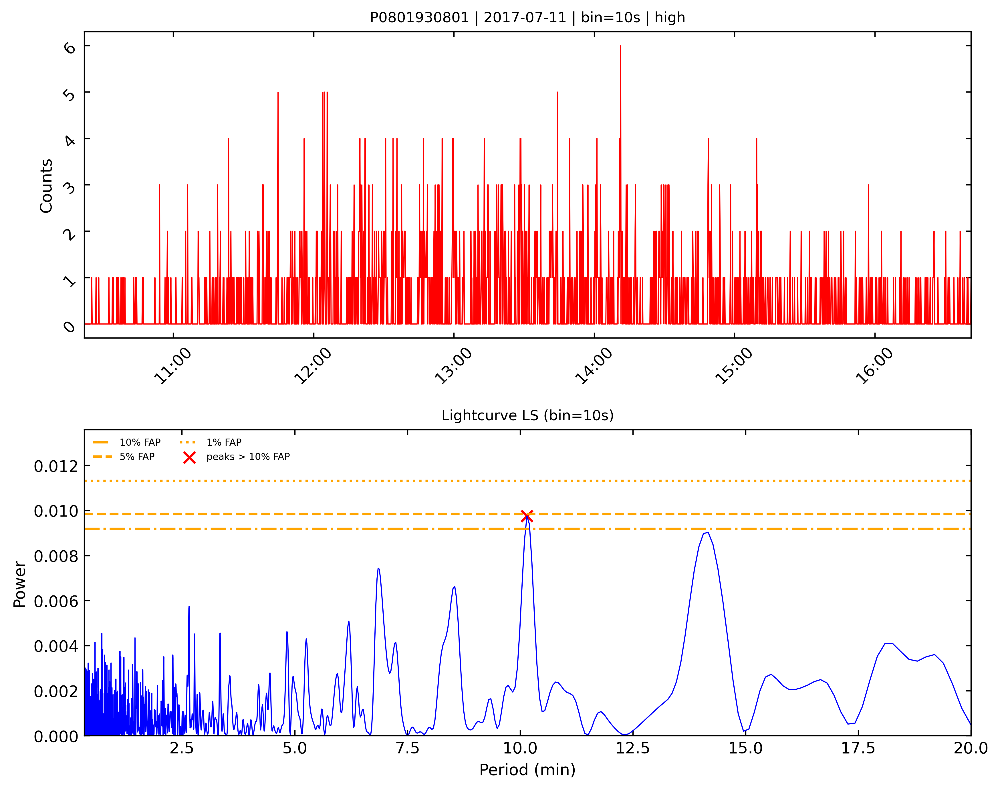

Finished P0801930801 | seg_bin=10s | category=high


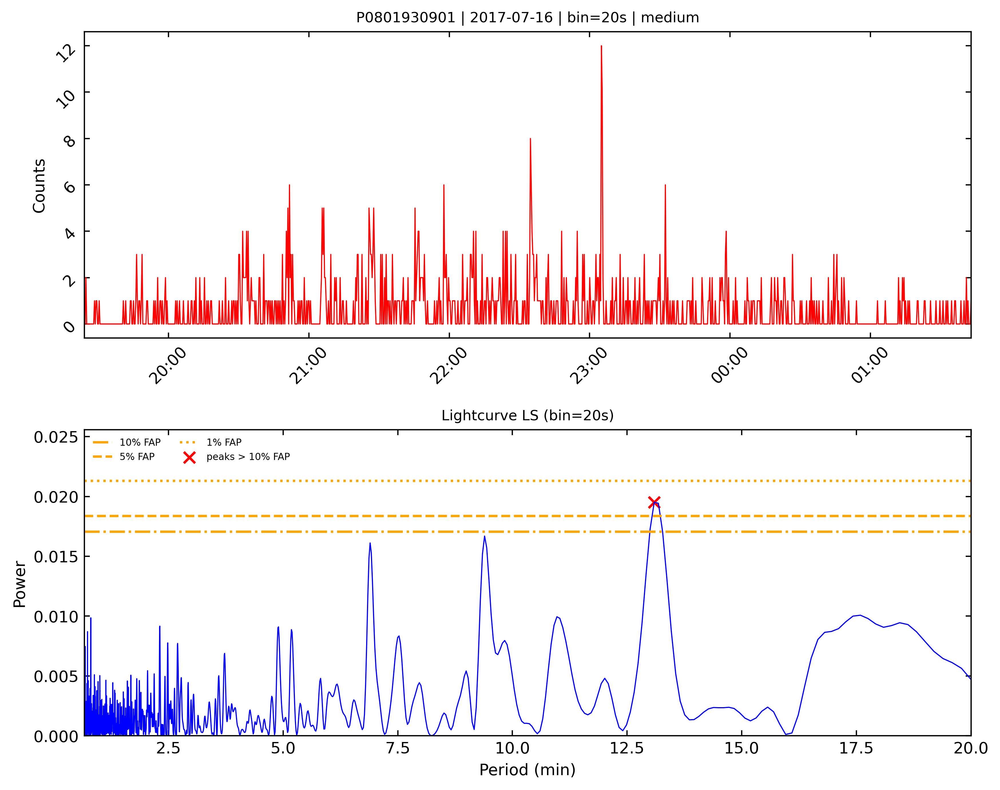

Finished P0801930901 | seg_bin=20s | category=medium


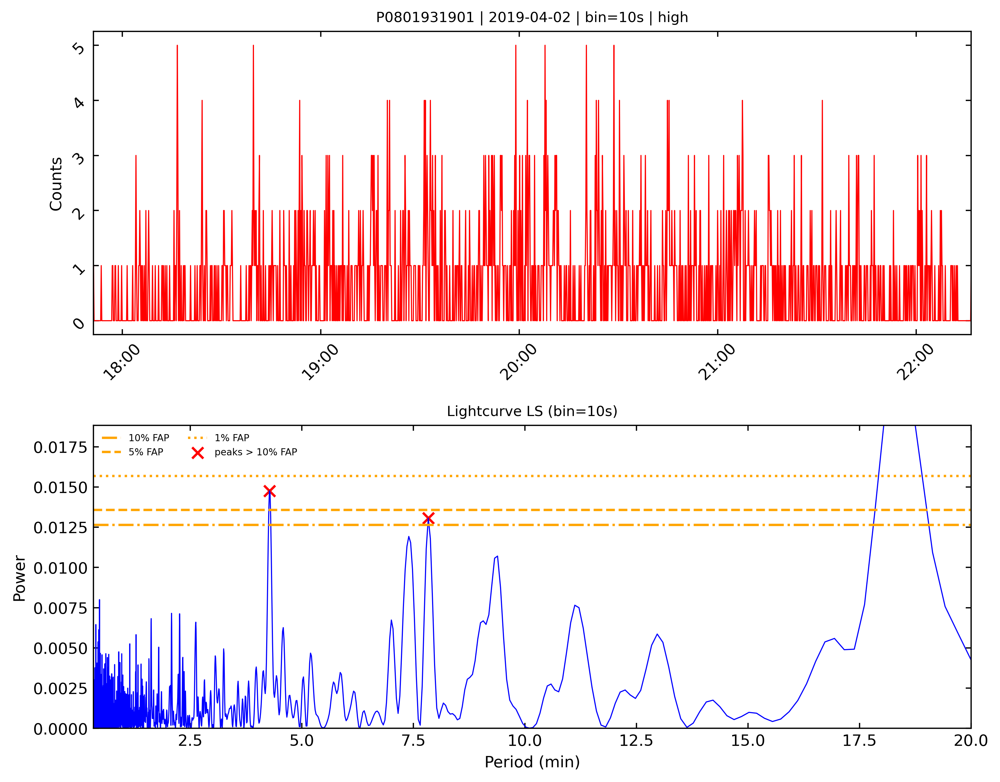

Finished P0801931901 | seg_bin=10s | category=high


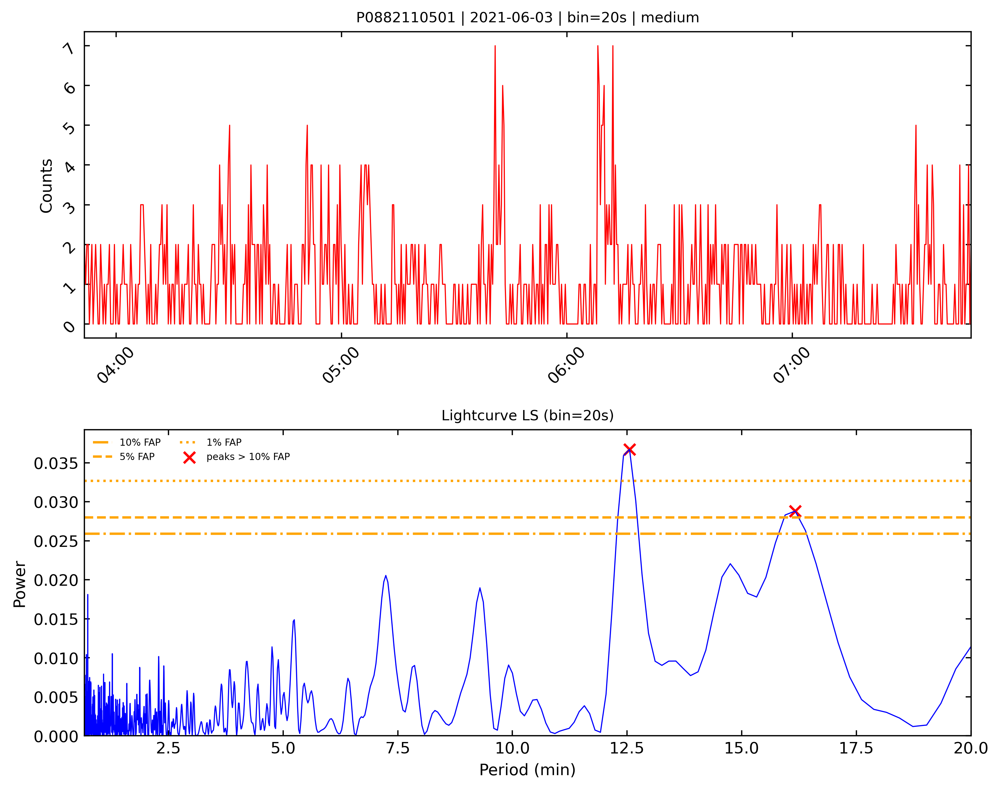

Finished P0882110501 | seg_bin=20s | category=medium


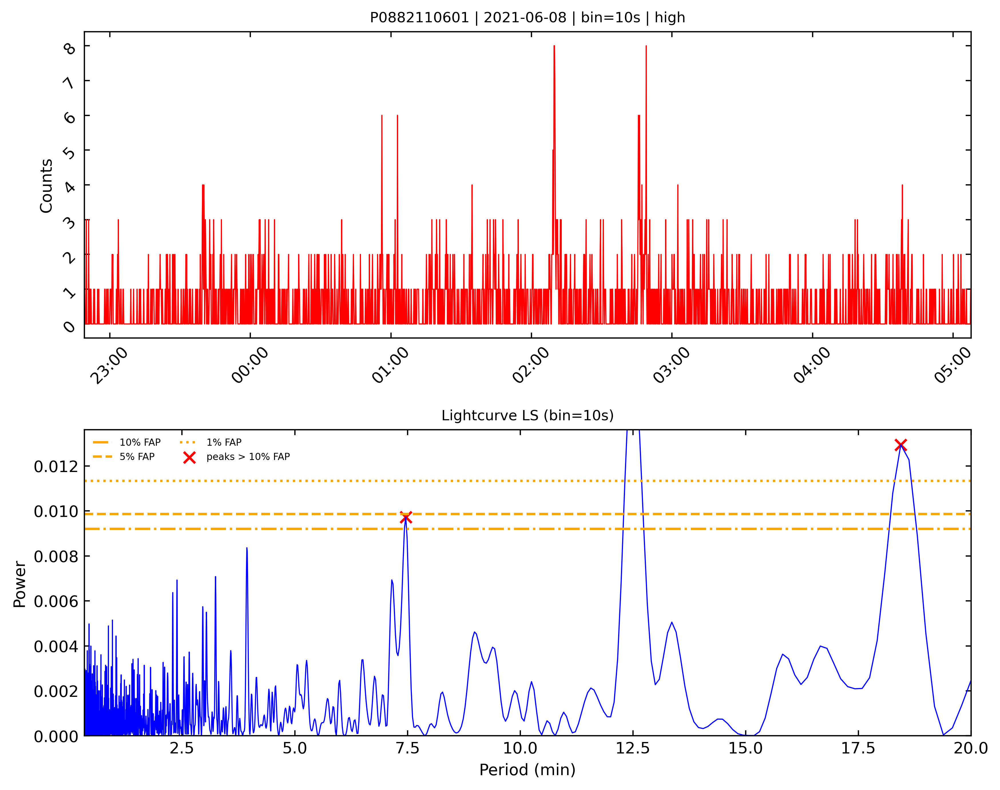

Finished P0882110601 | seg_bin=10s | category=high


In [10]:
import numpy as np
import matplotlib.pyplot as plt

from typing import Optional, Dict, Any, Tuple, List

from astropy.table import Table
from astropy.time import Time
from astropy.timeseries import LombScargle
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u

from matplotlib.dates import DateFormatter, HourLocator
import warnings
warnings.filterwarnings("ignore")


# ─── USER SETTINGS ────────────────────────────────────────────────────────────
tick_interval_h = 1
minor_interval_h = 1  # not used in this minimal LC+LS plot, kept for consistency

ident = ['P0801930801', 'P0801930901', 'P0801931901', 'P0882110501', 'P0882110601']
TARGET_SEGMENTS = {'P0801930801': 2, 'P0801930901': 1, 'P0801931901': 3, 'P0882110501': 3, 'P0882110601': 5}

base_bin_size = 10
data_dir = 'Data_Files/Fenn_Data/'


# ─── IO + PREP ────────────────────────────────────────────────────────────────
def load_combined_times(obs_id: str, data_dir: str):
    """
    Read all three EPIC cameras, correct for Jupiter–Earth light travel time,
    and return:
      times_datetime : ndarray[datetime]
      times_cxcsec   : ndarray[float]
    """
    files = [f'{data_dir}EPIC_{obs_id}_{cam}_North_RFT.fit' for cam in ['PN', 'M1', 'M2']]
    list_dt, list_cxc = [], []

    for file in files:
        data = Table.read(file, format="fits")

        t = Time(data['TIME'], format='cxcsec', scale='tt')
        with solar_system_ephemeris.set('de432s'):
            jup = get_body_barycentric('jupiter', t)
            xmm = get_body_barycentric('earth', t)  # approximate XMM as Earth-based

        distance_au = (jup - xmm).norm()
        light_time_s = (distance_au.to('m') / c).to('s').value

        corrected_t = t - light_time_s * u.s
        list_dt.append(corrected_t.datetime)
        list_cxc.append(corrected_t.cxcsec)

    return np.hstack(list_dt), np.hstack(list_cxc)


def find_gaps(times_cxcsec: np.ndarray, threshold: float = 3600.0):
    """
    Identify indices where the gap between consecutive times > threshold seconds.
    Returns:
      gaps    : list of (gap_start, gap_end) in cxcsec
      indices : ndarray of indices i such that times[i+1]-times[i] > threshold
    """
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps = [(times_cxcsec[i], times_cxcsec[i + 1]) for i in indices]
    return gaps, indices


# ─── BINNING ──────────────────────────────────────────────────────────────────
def bin_photon_times(photon_times: np.ndarray, bin_size: float):
    """
    Bin photon_times (CXC seconds) into bins of width=bin_size seconds.
    Returns:
      centers_cxcsec, counts
    """
    start = float(np.nanmin(photon_times))
    end = float(np.nanmax(photon_times))
    bins = np.arange(start, end + bin_size, bin_size)
    counts, edges = np.histogram(photon_times, bins=bins)
    centers = edges[:-1] + 0.5 * bin_size
    return centers, counts


def categorize_segment(counts: np.ndarray, low_thresh: float = 300, high_thresh: float = 1000):
    total = float(np.sum(counts))
    if total < low_thresh:
        return 'low'
    elif total < high_thresh:
        return 'medium'
    return 'high'


def dynamic_bin_size(category: str, base_bin: int = 120):
    if category == 'low':
        return base_bin * 4
    elif category == 'medium':
        return base_bin * 2
    return base_bin


def prepare_segment_bins(raw_segment: np.ndarray, base_bin: int):
    """
    1) initial bin with base_bin to categorise
    2) choose seg_bin via dynamic_bin_size
    3) re-bin with seg_bin
    """
    _, counts0 = bin_photon_times(raw_segment, base_bin)
    category = categorize_segment(counts0)

    seg_bin = dynamic_bin_size(category, base_bin)
    hist_centers, hist_counts = bin_photon_times(raw_segment, seg_bin)
    return seg_bin, hist_centers, hist_counts, category


# ─── LOMB–SCARGLE ─────────────────────────────────────────────────────────────
def compute_lightcurve_ls(hist_centers: np.ndarray, hist_counts: np.ndarray, seg_bin: float):
    """
    Compute LS periodogram for a lightcurve binned at seg_bin seconds,
    only between periods [2*seg_bin, 20 minutes].

    Returns:
      period_min, power, fap10, fap05, fap01
    """
    shortest_period = 2.0 * seg_bin
    longest_period = 20.0 * 60.0

    freq_max = 1.0 / shortest_period
    freq_min = 1.0 / longest_period

    ls_lc = LombScargle(hist_centers, hist_counts)
    freq, power = ls_lc.autopower(minimum_frequency=freq_min, maximum_frequency=freq_max)
    period_min = (1.0 / freq) / 60.0

    fap10 = ls_lc.false_alarm_level(0.10, minimum_frequency=freq_min, maximum_frequency=freq_max)
    fap05 = ls_lc.false_alarm_level(0.05, minimum_frequency=freq_min, maximum_frequency=freq_max)
    fap01 = ls_lc.false_alarm_level(0.01, minimum_frequency=freq_min, maximum_frequency=freq_max)

    return period_min, power, fap10, fap05, fap01


# ─── PLOTTING ─────────────────────────────────────────────────────────────────
def plot_lightcurve_subplot(ax, hist_centers, hist_counts, seg_bin, category,
                            obs_id, start_iso, end_iso):
    hist_dt = Time(hist_centers, format='cxcsec').datetime
    ax.plot(hist_dt, hist_counts, c='red', lw=0.7)

    title = f"{obs_id} | {start_iso[:10]} | bin={int(seg_bin)}s | {category}"
    ax.set_title(title, fontsize=9)

    ax.set_ylabel("Counts")
    ax.set_xlim(hist_dt[0], hist_dt[-1])

    ax.xaxis.set_major_locator(HourLocator(interval=1))
    ax.xaxis.set_major_formatter(DateFormatter('%H:%M'))
    ax.tick_params(rotation=45, direction='in', top=True, right=True)


def plot_lc_ls_subplot(ax, period_lc, power_lc, fap10, fap05, fap01, seg_bin):
    ax.plot(period_lc, power_lc, lw=0.7, c='blue')
    ax.set_xlim(2.0 * seg_bin / 60.0, 20.0)

    ax.axhline(fap10, linestyle='-.', color='orange', label='10% FAP')
    ax.axhline(fap05, linestyle='--', color='orange', label='5% FAP')
    ax.axhline(fap01, linestyle=':',  color='orange', label='1% FAP')

    peaks = []
    for i in range(1, len(power_lc) - 1):
        if (power_lc[i] > fap10) and (power_lc[i] > power_lc[i - 1]) and (power_lc[i] > power_lc[i + 1]):
            peaks.append(i)
    peaks = np.array(peaks, dtype=int)

    if peaks.size > 0:
        ax.scatter(period_lc[peaks], power_lc[peaks], marker='x', color='red', s=50,
                   label='peaks > 10% FAP')

    ax.set_title(f"Lightcurve LS (bin={int(seg_bin)}s)", fontsize=9)
    ax.set_xlabel("Period (min)")
    ax.set_ylabel("Power")
    ax.tick_params(direction='in', top=True, right=True)
    ax.set_ylim(0, 1.2 * fap01)
    ax.legend(fontsize=6, loc='upper left', ncols=2, frameon=False)


# ─── FINAL WRAPPER (VERTICAL STACK) ────────────────────────────────────────────
def run_xmm_lc_segment_analysis(
    obs_id: str,
    data_dir: str = "Data_Files/Fenn_Data/",
    base_bin_size: int = 10,
    gap_threshold_s: int = 3600,
    target_segments: Optional[Dict[str, int]] = None,
    save_path: Optional[str] = None,
    show: bool = True,
    dpi: int = 200,
):
    """
    End-to-end wrapper for:
      - load combined EPIC photon times
      - gap-split into segments
      - optional 1-based segment selection from target_segments
      - dynamic binning + LS
      - plot: (top) lightcurve, (bottom) LS, stacked vertically
    """
    if target_segments is None:
        target_segments = {}

    # Load + sort
    _, times_cxc = load_combined_times(obs_id, data_dir)
    if times_cxc.size < 10:
        raise ValueError(f"{obs_id}: not enough events after loading (N={times_cxc.size}).")

    order = np.argsort(times_cxc)
    t_sorted = times_cxc[order]

    # Gap split
    _, gap_idx = find_gaps(t_sorted, threshold=float(gap_threshold_s))
    split_pts = np.concatenate(([0], gap_idx + 1, [len(t_sorted)]))

    segments = []
    seg_times_iso = []
    for i in range(len(split_pts) - 1):
        seg = t_sorted[split_pts[i]: split_pts[i + 1]]
        if seg.size > 5:
            segments.append(seg)
            seg_times_iso.append((
                Time(seg[0], format='cxcsec').iso,
                Time(seg[-1], format='cxcsec').iso
            ))

    if len(segments) == 0:
        raise ValueError(f"{obs_id}: no valid segments after gap-splitting.")

    # Optional segment selection (1-based)
    selected_1based = target_segments.get(obs_id, None)
    if selected_1based is not None:
        k = selected_1based - 1
        if not (0 <= k < len(segments)):
            raise ValueError(f"{obs_id}: requested segment {selected_1based} but only {len(segments)} segments exist.")
        segments = [segments[k]]
        seg_times_iso = [seg_times_iso[k]]

    # Use the (possibly selected) first segment
    seg = segments[0]
    start_iso, end_iso = seg_times_iso[0]

    # Binning + LS
    seg_bin, hist_centers, hist_counts, category = prepare_segment_bins(seg, base_bin_size)
    period_lc, power_lc, fap10, fap05, fap01 = compute_lightcurve_ls(hist_centers, hist_counts, seg_bin)

    # Plot vertically stacked
    fig, (ax_lc, ax_ls) = plt.subplots(
        2, 1,
        figsize=(10, 8),
        dpi=dpi,
        gridspec_kw={"height_ratios": [2, 2], "hspace": 0.3}
    )

    plot_lightcurve_subplot(ax_lc, hist_centers, hist_counts, seg_bin, category, obs_id, start_iso, end_iso)
    ax_lc.set_xlabel("")  # top panel: typically omit x-label

    plot_lc_ls_subplot(ax_ls, period_lc, power_lc, fap10, fap05, fap01, seg_bin)

    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, bbox_inches="tight")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return {
        "obs_id": obs_id,
        "selected_segment_1based": selected_1based,
        "start_iso": start_iso,
        "end_iso": end_iso,
        "category": category,
        "seg_bin_s": seg_bin,
        "hist_centers_cxcsec": hist_centers,
        "hist_counts": hist_counts,
        "period_min": period_lc,
        "power": power_lc,
        "fap10": fap10,
        "fap05": fap05,
        "fap01": fap01,
        "n_segments_found": len(segments) if selected_1based is None else None,
    }


# ─── BATCH DRIVER ─────────────────────────────────────────────────────────────
if __name__ == "__main__":
    for obs_id in ident:
        out = run_xmm_lc_segment_analysis(
            obs_id=obs_id,
            data_dir=data_dir,
            base_bin_size=base_bin_size,
            gap_threshold_s=3600,
            target_segments=TARGET_SEGMENTS,
            save_path=f"{obs_id}_lc_ls.png",
            show=True,
            dpi=400,
        )
        print(f"Finished {obs_id} | seg_bin={out['seg_bin_s']}s | category={out['category']}")


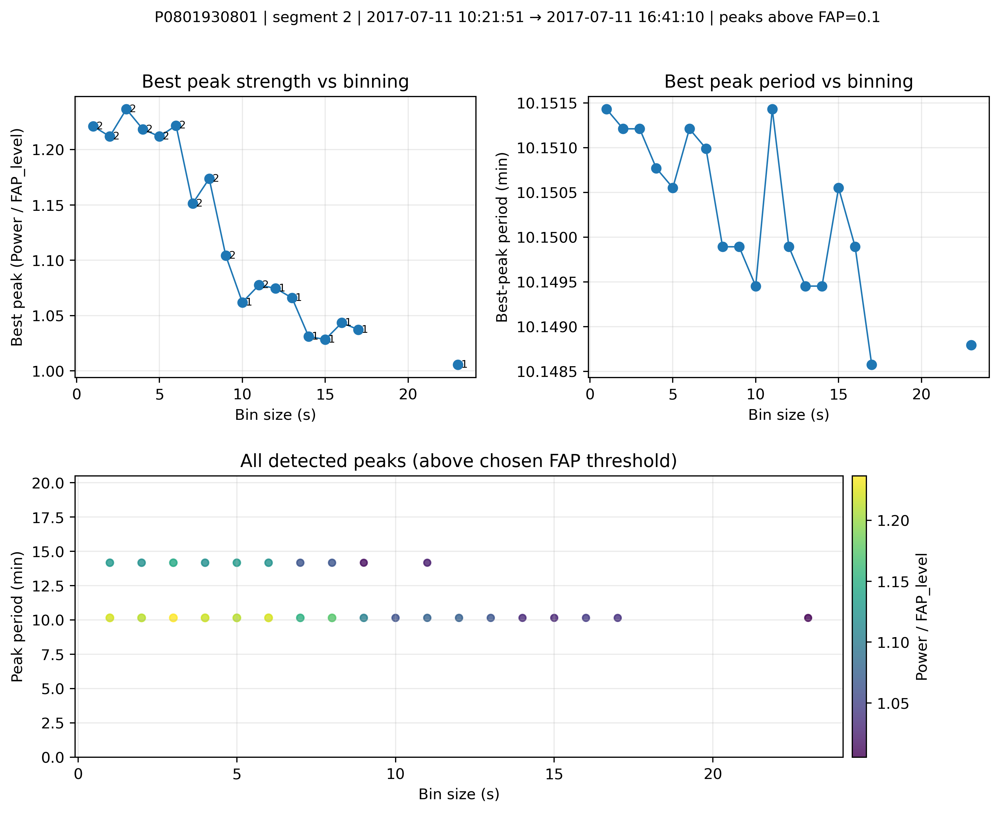


P0801930801 | segment=2 | 2017-07-11 10:21:51 → 2017-07-11 16:41:10
  bin=   1.0s | n_peaks= 2 | bestP= 10.15 min | ratio=   1.221
  bin=   2.0s | n_peaks= 2 | bestP= 10.15 min | ratio=   1.212
  bin=   3.0s | n_peaks= 2 | bestP= 10.15 min | ratio=   1.236
  bin=   4.0s | n_peaks= 2 | bestP= 10.15 min | ratio=   1.218
  bin=   5.0s | n_peaks= 2 | bestP= 10.15 min | ratio=   1.212
  bin=   6.0s | n_peaks= 2 | bestP= 10.15 min | ratio=   1.222
  bin=   7.0s | n_peaks= 2 | bestP= 10.15 min | ratio=   1.151
  bin=   8.0s | n_peaks= 2 | bestP= 10.15 min | ratio=   1.174
  bin=   9.0s | n_peaks= 2 | bestP= 10.15 min | ratio=   1.104
  bin=  10.0s | n_peaks= 1 | bestP= 10.15 min | ratio=   1.062
  bin=  11.0s | n_peaks= 2 | bestP= 10.15 min | ratio=   1.078
  bin=  12.0s | n_peaks= 1 | bestP= 10.15 min | ratio=   1.075
  bin=  13.0s | n_peaks= 1 | bestP= 10.15 min | ratio=   1.066
  bin=  14.0s | n_peaks= 1 | bestP= 10.15 min | ratio=   1.031
  bin=  15.0s | n_peaks= 1 | bestP= 10.15 min | r

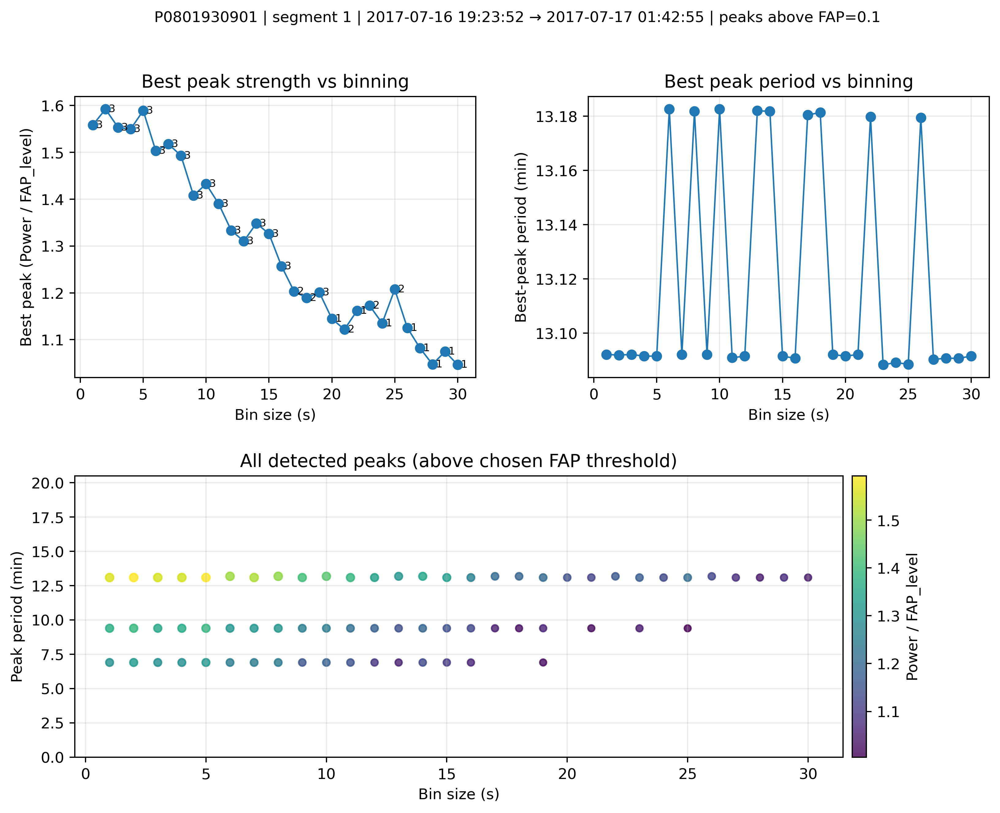


P0801930901 | segment=1 | 2017-07-16 19:23:52 → 2017-07-17 01:42:55
  bin=   1.0s | n_peaks= 3 | bestP= 13.09 min | ratio=   1.559
  bin=   2.0s | n_peaks= 3 | bestP= 13.09 min | ratio=   1.592
  bin=   3.0s | n_peaks= 3 | bestP= 13.09 min | ratio=   1.553
  bin=   4.0s | n_peaks= 3 | bestP= 13.09 min | ratio=   1.550
  bin=   5.0s | n_peaks= 3 | bestP= 13.09 min | ratio=   1.589
  bin=   6.0s | n_peaks= 3 | bestP= 13.18 min | ratio=   1.503
  bin=   7.0s | n_peaks= 3 | bestP= 13.09 min | ratio=   1.518
  bin=   8.0s | n_peaks= 3 | bestP= 13.18 min | ratio=   1.493
  bin=   9.0s | n_peaks= 3 | bestP= 13.09 min | ratio=   1.408
  bin=  10.0s | n_peaks= 3 | bestP= 13.18 min | ratio=   1.432
  bin=  11.0s | n_peaks= 3 | bestP= 13.09 min | ratio=   1.390
  bin=  12.0s | n_peaks= 3 | bestP= 13.09 min | ratio=   1.333
  bin=  13.0s | n_peaks= 3 | bestP= 13.18 min | ratio=   1.310
  bin=  14.0s | n_peaks= 3 | bestP= 13.18 min | ratio=   1.348
  bin=  15.0s | n_peaks= 3 | bestP= 13.09 min | r

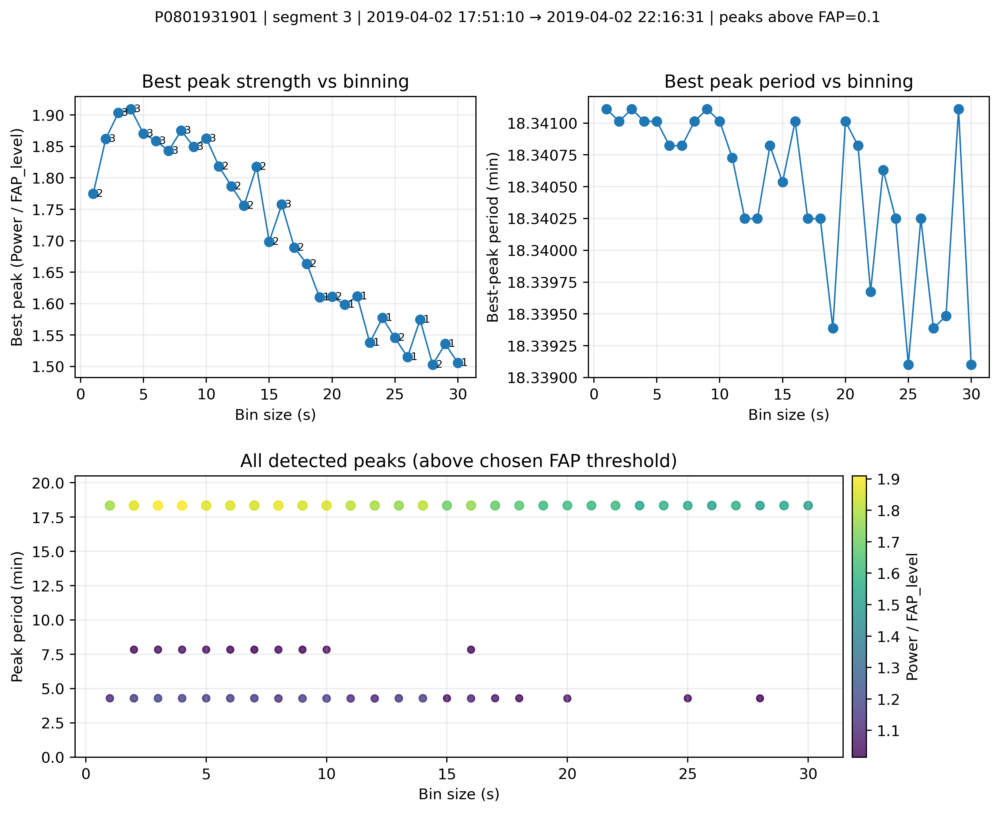


P0801931901 | segment=3 | 2019-04-02 17:51:10 → 2019-04-02 22:16:31
  bin=   1.0s | n_peaks= 2 | bestP= 18.34 min | ratio=   1.775
  bin=   2.0s | n_peaks= 3 | bestP= 18.34 min | ratio=   1.862
  bin=   3.0s | n_peaks= 3 | bestP= 18.34 min | ratio=   1.903
  bin=   4.0s | n_peaks= 3 | bestP= 18.34 min | ratio=   1.909
  bin=   5.0s | n_peaks= 3 | bestP= 18.34 min | ratio=   1.870
  bin=   6.0s | n_peaks= 3 | bestP= 18.34 min | ratio=   1.859
  bin=   7.0s | n_peaks= 3 | bestP= 18.34 min | ratio=   1.843
  bin=   8.0s | n_peaks= 3 | bestP= 18.34 min | ratio=   1.875
  bin=   9.0s | n_peaks= 3 | bestP= 18.34 min | ratio=   1.849
  bin=  10.0s | n_peaks= 3 | bestP= 18.34 min | ratio=   1.863
  bin=  11.0s | n_peaks= 2 | bestP= 18.34 min | ratio=   1.818
  bin=  12.0s | n_peaks= 2 | bestP= 18.34 min | ratio=   1.787
  bin=  13.0s | n_peaks= 2 | bestP= 18.34 min | ratio=   1.756
  bin=  14.0s | n_peaks= 2 | bestP= 18.34 min | ratio=   1.818
  bin=  15.0s | n_peaks= 2 | bestP= 18.34 min | r

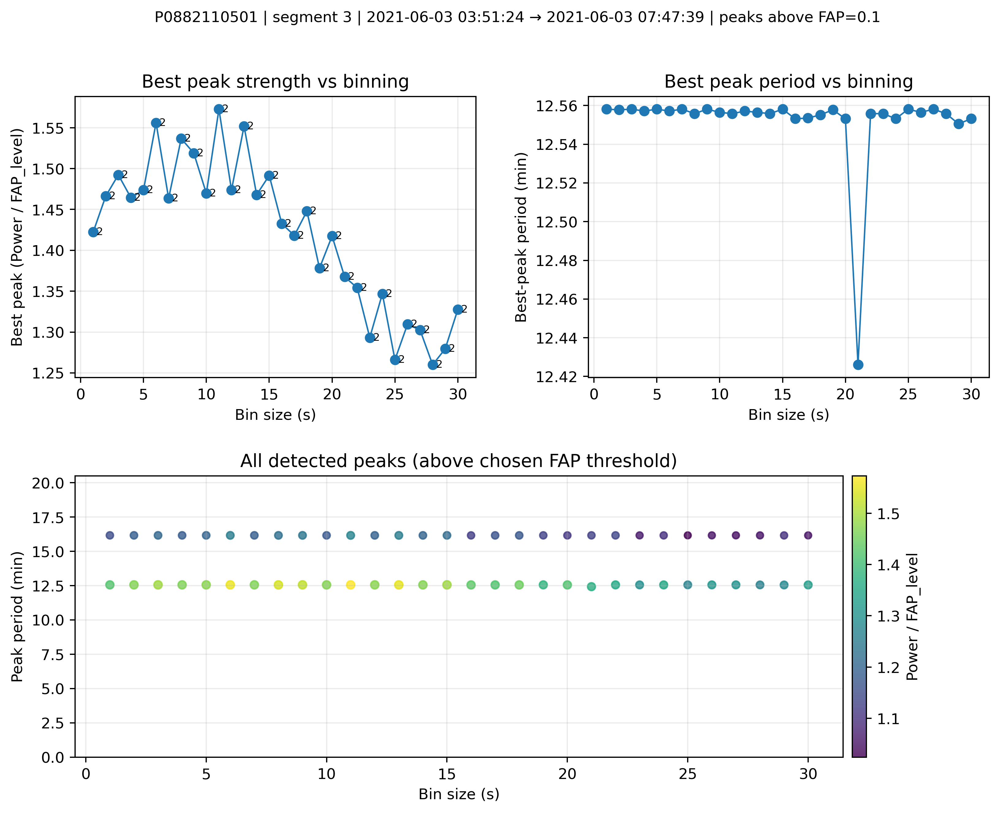


P0882110501 | segment=3 | 2021-06-03 03:51:24 → 2021-06-03 07:47:39
  bin=   1.0s | n_peaks= 2 | bestP= 12.56 min | ratio=   1.422
  bin=   2.0s | n_peaks= 2 | bestP= 12.56 min | ratio=   1.466
  bin=   3.0s | n_peaks= 2 | bestP= 12.56 min | ratio=   1.492
  bin=   4.0s | n_peaks= 2 | bestP= 12.56 min | ratio=   1.464
  bin=   5.0s | n_peaks= 2 | bestP= 12.56 min | ratio=   1.474
  bin=   6.0s | n_peaks= 2 | bestP= 12.56 min | ratio=   1.556
  bin=   7.0s | n_peaks= 2 | bestP= 12.56 min | ratio=   1.464
  bin=   8.0s | n_peaks= 2 | bestP= 12.56 min | ratio=   1.537
  bin=   9.0s | n_peaks= 2 | bestP= 12.56 min | ratio=   1.519
  bin=  10.0s | n_peaks= 2 | bestP= 12.56 min | ratio=   1.470
  bin=  11.0s | n_peaks= 2 | bestP= 12.56 min | ratio=   1.573
  bin=  12.0s | n_peaks= 2 | bestP= 12.56 min | ratio=   1.474
  bin=  13.0s | n_peaks= 2 | bestP= 12.56 min | ratio=   1.552
  bin=  14.0s | n_peaks= 2 | bestP= 12.56 min | ratio=   1.468
  bin=  15.0s | n_peaks= 2 | bestP= 12.56 min | r

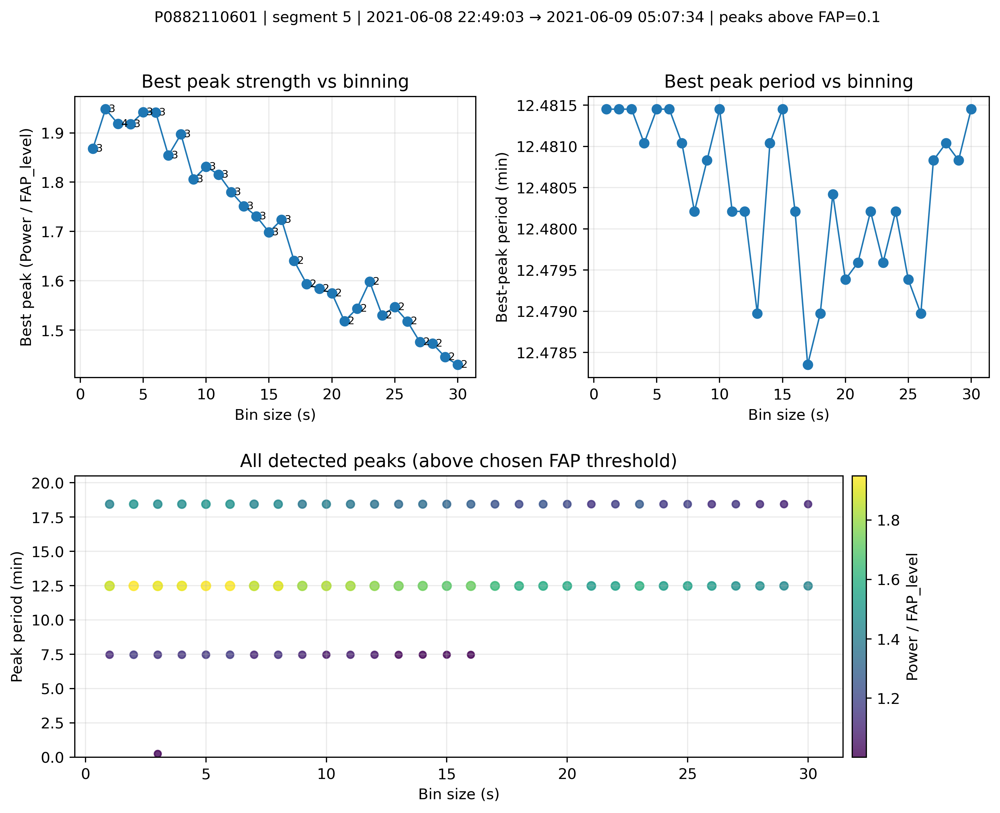


P0882110601 | segment=5 | 2021-06-08 22:49:03 → 2021-06-09 05:07:34
  bin=   1.0s | n_peaks= 3 | bestP= 12.48 min | ratio=   1.868
  bin=   2.0s | n_peaks= 3 | bestP= 12.48 min | ratio=   1.948
  bin=   3.0s | n_peaks= 4 | bestP= 12.48 min | ratio=   1.918
  bin=   4.0s | n_peaks= 3 | bestP= 12.48 min | ratio=   1.918
  bin=   5.0s | n_peaks= 3 | bestP= 12.48 min | ratio=   1.942
  bin=   6.0s | n_peaks= 3 | bestP= 12.48 min | ratio=   1.941
  bin=   7.0s | n_peaks= 3 | bestP= 12.48 min | ratio=   1.854
  bin=   8.0s | n_peaks= 3 | bestP= 12.48 min | ratio=   1.897
  bin=   9.0s | n_peaks= 3 | bestP= 12.48 min | ratio=   1.806
  bin=  10.0s | n_peaks= 3 | bestP= 12.48 min | ratio=   1.832
  bin=  11.0s | n_peaks= 3 | bestP= 12.48 min | ratio=   1.815
  bin=  12.0s | n_peaks= 3 | bestP= 12.48 min | ratio=   1.780
  bin=  13.0s | n_peaks= 3 | bestP= 12.48 min | ratio=   1.751
  bin=  14.0s | n_peaks= 3 | bestP= 12.48 min | ratio=   1.731
  bin=  15.0s | n_peaks= 3 | bestP= 12.48 min | r

In [2]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
XMM EPIC (PN/M1/M2) lightcurve binning sweep:
- For a chosen obs_id + (optional) selected gap-segment,
  loop over a list of bin sizes [s]
- For each bin:
    * histogram to lightcurve
    * Lomb-Scargle over periods [2*bin, 20 min]
    * detect local maxima peaks above a chosen FAP level (default 1%)
    * record best peak power / FAP99 ratio
- Plot how best-peak ratio changes with bin size, plus best period vs bin size
  and optional "all-peaks" scatter for diagnostics.
"""

import numpy as np
import matplotlib.pyplot as plt
from typing import Optional, Dict, Any, Tuple, List

from astropy.table import Table
from astropy.time import Time
from astropy.timeseries import LombScargle
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u

from matplotlib.dates import DateFormatter, HourLocator
import warnings
warnings.filterwarnings("ignore")


# ─── USER SETTINGS ────────────────────────────────────────────────────────────
ident = ['P0801930801', 'P0801930901', 'P0801931901', 'P0882110501', 'P0882110601']
TARGET_SEGMENTS = {'P0801930801': 2, 'P0801930901': 1, 'P0801931901': 3, 'P0882110501': 3, 'P0882110601': 5}

data_dir = 'Data_Files/Fenn_Data/'

# Bin sweep list (seconds)
BIN_SIZES_S = list(range(0,31,1))
# Gap split threshold (seconds)
GAP_THRESHOLD_S = 3600

# LS longest period (seconds)
LONGEST_PERIOD_S = 20 * 60

# Which FAP line defines "significant peaks"
#   0.01 == 1% false alarm probability => often called "99% significance"
PEAK_FAP = 0.1

# When there are multiple peaks for a given bin size, choose the "best" peak by:
#   "max_ratio" => max(power / FAP_level)
#   "max_power" => max(power)
PICK_BEST_MODE = "max_ratio"

# Optional diagnostic: plot the LS curves in a grid (can get busy)
PLOT_LS_GRID = False
LS_GRID_MAX = 12  # max curves to show if enabled

# Output directory/paths
SAVE_DIR = "."
SAVE_SUFFIX = "bin_sweep"


# ─── IO + PREP ────────────────────────────────────────────────────────────────
def load_combined_times(obs_id: str, data_dir: str):
    """
    Read all three EPIC cameras, correct for Jupiter–Earth light travel time,
    and return:
      times_datetime : ndarray[datetime]
      times_cxcsec   : ndarray[float]
    """
    files = [f'{data_dir}EPIC_{obs_id}_{cam}_North_RFT.fit' for cam in ['PN', 'M1', 'M2']]
    list_dt, list_cxc = [], []

    for file in files:
        data = Table.read(file, format="fits")

        t = Time(data['TIME'], format='cxcsec', scale='tt')
        with solar_system_ephemeris.set('de432s'):
            jup = get_body_barycentric('jupiter', t)
            xmm = get_body_barycentric('earth', t)  # approximate XMM as Earth-based

        distance_au = (jup - xmm).norm()
        light_time_s = (distance_au.to('m') / c).to('s').value

        corrected_t = t - light_time_s * u.s
        list_dt.append(corrected_t.datetime)
        list_cxc.append(corrected_t.cxcsec)

    return np.hstack(list_dt), np.hstack(list_cxc)


def find_gaps(times_cxcsec: np.ndarray, threshold: float = 3600.0):
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps = [(times_cxcsec[i], times_cxcsec[i + 1]) for i in indices]
    return gaps, indices


def split_into_segments(times_cxcsec: np.ndarray, gap_threshold_s: float) -> Tuple[List[np.ndarray], List[Tuple[str, str]]]:
    """Gap-split sorted times into segments; return segments + [(start_iso, end_iso), ...]."""
    if times_cxcsec.size < 2:
        return [], []

    _, gap_idx = find_gaps(times_cxcsec, threshold=float(gap_threshold_s))
    split_pts = np.concatenate(([0], gap_idx + 1, [len(times_cxcsec)]))

    segments = []
    seg_times_iso = []
    for i in range(len(split_pts) - 1):
        seg = times_cxcsec[split_pts[i]: split_pts[i + 1]]
        if seg.size > 5:
            segments.append(seg)
            seg_times_iso.append((
                Time(seg[0], format='cxcsec').iso,
                Time(seg[-1], format='cxcsec').iso
            ))

    return segments, seg_times_iso


# ─── BINNING ──────────────────────────────────────────────────────────────────
def bin_photon_times(photon_times: np.ndarray, bin_size: float):
    start = float(np.nanmin(photon_times))
    end = float(np.nanmax(photon_times))
    bins = np.arange(start, end + bin_size, bin_size)
    counts, edges = np.histogram(photon_times, bins=bins)
    centers = edges[:-1] + 0.5 * bin_size
    return centers, counts


# ─── LOMB–SCARGLE + PEAKING ───────────────────────────────────────────────────
def compute_ls_for_bin(hist_centers: np.ndarray, hist_counts: np.ndarray, bin_s: float,
                       longest_period_s: float = LONGEST_PERIOD_S):
    """
    LS over periods [2*bin, longest_period_s].
    Returns:
      period_min (min), power, fap_level (for PEAK_FAP)
      plus also fap10/fap05/fap01 if you want them
    """
    shortest_period = 2.0 * bin_s
    longest_period = float(longest_period_s)

    freq_max = 1.0 / shortest_period
    freq_min = 1.0 / longest_period

    ls = LombScargle(hist_centers, hist_counts)
    freq, power = ls.autopower(minimum_frequency=freq_min, maximum_frequency=freq_max)
    period_min = (1.0 / freq) / 60.0

    fap10 = ls.false_alarm_level(0.10, minimum_frequency=freq_min, maximum_frequency=freq_max)
    fap05 = ls.false_alarm_level(0.05, minimum_frequency=freq_min, maximum_frequency=freq_max)
    fap01 = ls.false_alarm_level(0.01, minimum_frequency=freq_min, maximum_frequency=freq_max)

    fap_level = ls.false_alarm_level(PEAK_FAP, minimum_frequency=freq_min, maximum_frequency=freq_max)

    return period_min, power, fap_level, fap10, fap05, fap01


def find_localmax_peaks(period_min: np.ndarray, power: np.ndarray, threshold: float) -> np.ndarray:
    """Simple local-max peak pick above threshold; returns indices."""
    if power.size < 3:
        return np.array([], dtype=int)

    idx = []
    for i in range(1, len(power) - 1):
        if (power[i] > threshold) and (power[i] > power[i - 1]) and (power[i] > power[i + 1]):
            idx.append(i)
    return np.asarray(idx, dtype=int)


def pick_best_peak(period_min: np.ndarray, power: np.ndarray, peaks_idx: np.ndarray, fap_level: float,
                   mode: str = "max_ratio"):
    """
    Returns (best_period_min, best_power, best_ratio) or (None, None, None) if no peaks.
    """
    if peaks_idx.size == 0 or fap_level <= 0:
        return None, None, None

    peak_p = period_min[peaks_idx]
    peak_pow = power[peaks_idx]
    peak_ratio = peak_pow / fap_level

    if mode == "max_power":
        j = int(np.argmax(peak_pow))
    else:  # default max_ratio
        j = int(np.argmax(peak_ratio))

    return float(peak_p[j]), float(peak_pow[j]), float(peak_ratio[j])


# ─── MAIN BINNING SWEEP ───────────────────────────────────────────────────────
def run_binning_sweep_for_obs(
    obs_id: str,
    data_dir: str,
    bin_sizes_s: List[float],
    gap_threshold_s: float = GAP_THRESHOLD_S,
    target_segments: Optional[Dict[str, int]] = None,
    save_path: Optional[str] = None,
    show: bool = True,
    dpi: int = 250,
):
    if target_segments is None:
        target_segments = {}

    # Load + sort
    _, times_cxc = load_combined_times(obs_id, data_dir)
    if times_cxc.size < 10:
        raise ValueError(f"{obs_id}: not enough events after loading (N={times_cxc.size}).")

    t_sorted = np.sort(times_cxc)

    # Segment split
    segments, seg_times_iso = split_into_segments(t_sorted, gap_threshold_s=gap_threshold_s)
    if len(segments) == 0:
        raise ValueError(f"{obs_id}: no valid segments after gap-splitting.")

    # Optional segment selection (1-based)
    selected_1based = target_segments.get(obs_id, None)
    if selected_1based is not None:
        k = selected_1based - 1
        if not (0 <= k < len(segments)):
            raise ValueError(f"{obs_id}: requested segment {selected_1based} but only {len(segments)} segments exist.")
        segments = [segments[k]]
        seg_times_iso = [seg_times_iso[k]]

    seg = segments[0]
    start_iso, end_iso = seg_times_iso[0]

    # Sweep bins
    results_best = []   # one row per bin size
    results_all = []    # all peaks per bin size

    for bin_s in bin_sizes_s:
        if bin_s <= 0:
            continue

        hist_centers, hist_counts = bin_photon_times(seg, float(bin_s))

        # guard: require a minimum number of bins for LS to be meaningful
        if hist_centers.size < 10:
            results_best.append({
                "bin_s": float(bin_s),
                "best_period_min": np.nan,
                "best_power": np.nan,
                "fap_level": np.nan,
                "best_ratio": np.nan,
                "n_peaks": 0,
            })
            continue

        period_min, power, fap_level, fap10, fap05, fap01 = compute_ls_for_bin(
            hist_centers, hist_counts, bin_s=float(bin_s), longest_period_s=LONGEST_PERIOD_S
        )

        peaks_idx = find_localmax_peaks(period_min, power, threshold=fap_level)

        # store all peaks
        for ii in peaks_idx:
            results_all.append({
                "bin_s": float(bin_s),
                "period_min": float(period_min[ii]),
                "power": float(power[ii]),
                "fap_level": float(fap_level),
                "ratio": float(power[ii] / fap_level) if fap_level > 0 else np.nan,
            })

        best_period, best_power, best_ratio = pick_best_peak(
            period_min, power, peaks_idx, fap_level, mode=PICK_BEST_MODE
        )

        results_best.append({
            "bin_s": float(bin_s),
            "best_period_min": np.nan if best_period is None else best_period,
            "best_power": np.nan if best_power is None else best_power,
            "fap_level": float(fap_level),
            "best_ratio": np.nan if best_ratio is None else best_ratio,
            "n_peaks": int(peaks_idx.size),
        })

    # Convert to arrays for plotting
    bins = np.array([r["bin_s"] for r in results_best], dtype=float)
    best_ratio = np.array([r["best_ratio"] for r in results_best], dtype=float)
    best_period = np.array([r["best_period_min"] for r in results_best], dtype=float)
    n_peaks = np.array([r["n_peaks"] for r in results_best], dtype=int)

    # ─── Plot summary ─────────────────────────────────────────────────────────
    fig = plt.figure(figsize=(11, 8), dpi=dpi)
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1], hspace=0.35, wspace=0.28)

    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 1])
    ax3 = fig.add_subplot(gs[1, :])

    fig.suptitle(
        f"{obs_id} | segment {selected_1based if selected_1based else 'all'} | "
        f"{start_iso[:19]} → {end_iso[:19]} | peaks above FAP={PEAK_FAP}",
        fontsize=10
    )

    # Panel 1: best ratio vs bin
    ax1.plot(bins, best_ratio, marker='o', lw=1.0)
    ax1.set_xlabel("Bin size (s)")
    ax1.set_ylabel("Best peak (Power / FAP_level)")
    ax1.set_title("Best peak strength vs binning")
    ax1.grid(True, alpha=0.25)
    # annotate n_peaks
    for x, y, npk in zip(bins, best_ratio, n_peaks):
        if np.isfinite(y):
            ax1.text(x, y, f" {npk}", fontsize=7, va="center")

    # Panel 2: best period vs bin
    ax2.plot(bins, best_period, marker='o', lw=1.0)
    ax2.set_xlabel("Bin size (s)")
    ax2.set_ylabel("Best-peak period (min)")
    ax2.set_title("Best peak period vs binning")
    ax2.grid(True, alpha=0.25)

    # Panel 3: all peaks scatter (period vs bin, sized by ratio)
    if len(results_all) > 0:
        all_bin = np.array([r["bin_s"] for r in results_all], dtype=float)
        all_per = np.array([r["period_min"] for r in results_all], dtype=float)
        all_rat = np.array([r["ratio"] for r in results_all], dtype=float)

        # size scaling (robust)
        size = 20.0 * np.clip(all_rat, 1.0, np.nanpercentile(all_rat, 90) if np.isfinite(all_rat).any() else 5.0)

        sc = ax3.scatter(all_bin, all_per, s=size, c=all_rat, alpha=0.8)
        cbar = fig.colorbar(sc, ax=ax3, pad=0.01)
        cbar.set_label("Power / FAP_level")
        ax3.set_title("All detected peaks (above chosen FAP threshold)")
    else:
        ax3.text(0.5, 0.5, "No peaks found above threshold for any bin size.",
                 transform=ax3.transAxes, ha="center", va="center")

    ax3.set_xlabel("Bin size (s)")
    ax3.set_ylabel("Peak period (min)")
    ax3.set_ylim(0, 20.5)
    ax3.grid(True, alpha=0.25)

    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, bbox_inches="tight")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return {
        "obs_id": obs_id,
        "selected_segment_1based": selected_1based,
        "start_iso": start_iso,
        "end_iso": end_iso,
        "results_best": results_best,
        "results_all": results_all,
    }


# ─── BATCH DRIVER ─────────────────────────────────────────────────────────────
if __name__ == "__main__":
    for obs_id in ident:
        out_png = f"{SAVE_DIR}/{obs_id}_{SAVE_SUFFIX}.png"
        out = run_binning_sweep_for_obs(
            obs_id=obs_id,
            data_dir=data_dir,
            bin_sizes_s=BIN_SIZES_S,
            gap_threshold_s=GAP_THRESHOLD_S,
            target_segments=TARGET_SEGMENTS,
            save_path=out_png,
            show=True,
            dpi=350,
        )

        # quick console summary
        print(f"\n{obs_id} | segment={out['selected_segment_1based']} | {out['start_iso'][:19]} → {out['end_iso'][:19]}")
        for r in out["results_best"]:
            print(f"  bin={r['bin_s']:>6.1f}s | n_peaks={r['n_peaks']:>2d} | "
                  f"bestP={r['best_period_min'] if np.isfinite(r['best_period_min']) else np.nan:>6.2f} min | "
                  f"ratio={r['best_ratio'] if np.isfinite(r['best_ratio']) else np.nan:>8.3f}")
        print(f"Saved: {out_png}")



[LHRL sweep bin=200 Hz] best period=13.84 min @ 349 Hz (power=0.00452)
[LFRH sweep bin=200 Hz] best period=nan min @ nan Hz (power=nan)


/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_23000/1610483274.py:710: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.02, 1, 0.96])


Saved WAVES fig: WAVES_FIGS/waves_waves_bestbin_ts_ls.png


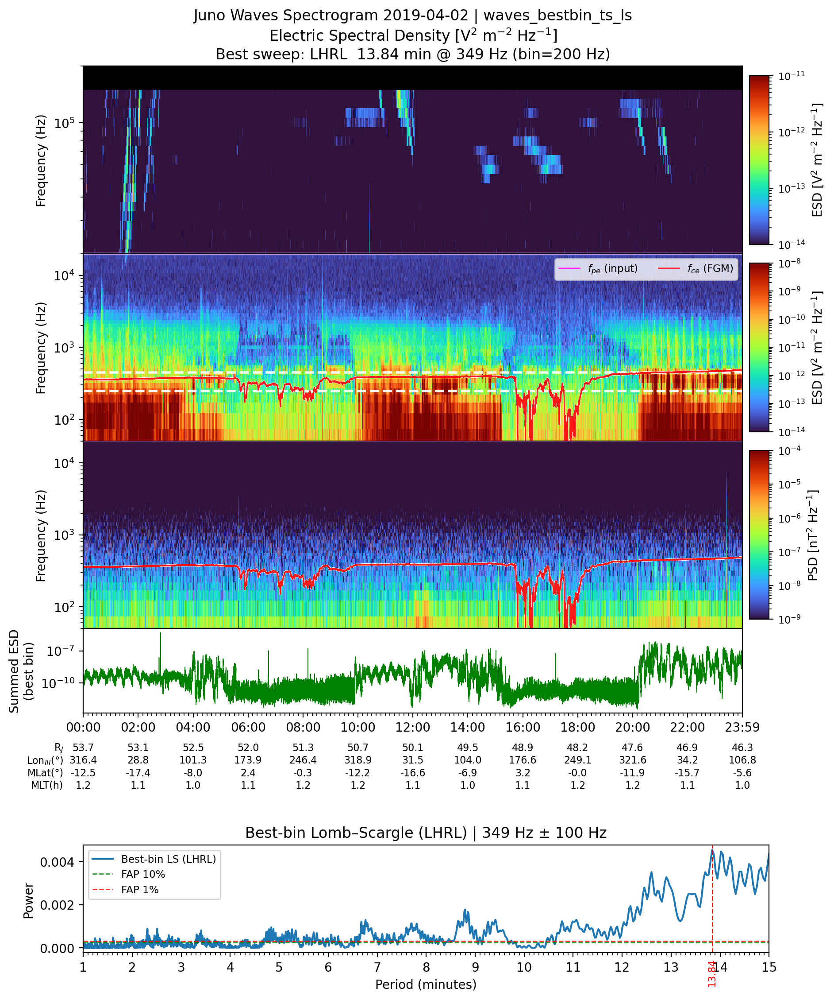

In [8]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
WAVES-only segment analysis (LFRH + LHRL + optional MAG) with:
  - LFRH spectrogram
  - LHRL spectrogram
  - optional magnetic spectrogram (b=True)
  - overlays: f_pe (input), optional f_ce (FGM via EFC)
  - ephemeris rows
  - Sweep BOTH electric spectrograms using fixed-width frequency bins (user-settable, e.g. 200 Hz)
    and find the strongest periodicity (max LS power) per panel, then pick the global best.
  - White dashed horizontal lines now show ONLY the best sweep bin (lo/hi) on the winning panel.
  - The "Summed ESD" time-series panel now shows the summed ESD for the BEST sweep bin
    (not the old whistler-band sum).
  - Bottom panel shows the Lomb–Scargle periodogram for the BEST sweep bin.

Dependencies:
  pip install das2 astropy scipy pandas matplotlib numpy
"""

import os
import numpy as np
from das2 import get_source
import das2
import matplotlib.pyplot as plt


# ──────────────────────────────────────────────────────────────────────────────
# GLOBAL CONFIG
# ──────────────────────────────────────────────────────────────────────────────
WAVES_FIG_OUTDIR = "WAVES_FIGS"
os.makedirs(WAVES_FIG_OUTDIR, exist_ok=True)

SERVER_URL_WAVES = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"
SERVER_URL_EFC   = "tag:das2.org,2012:site:/uiowa/juno/fgm/electroncyclotron/das2"
SERVER_URL_EPH   = "tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2"

PERIOD_MIN       = 1.0
PERIOD_MAX       = 15.0
PEAK_DETECT_MIN  = 2.5
NUM_PEAKS        = 4
LS_NFREQ         = 5000

LFRH_YLIM   = (2e4, 2e5)
LHRL_YLIM   = (5e1, 2e4)
B_YLIM      = (5e1, 2e4)

LFRH_LOGNORM = (1e-14, 1e-11)
LHRL_LOGNORM = (1e-14, 1e-8)
B_LOGNORM    = (1e-9, 1e-4)

OVERLAY_LW    = 1.0
OVERLAY_ALPHA = 0.9
PLOT_FCE_FZ_FUHR = True

SWEEP_BIN_HZ = 200.0


# ──────────────────────────────────────────────────────────────────────────────
# SWEEP: best periodicity per frequency-bin, return per-bin winners + best bin
# ──────────────────────────────────────────────────────────────────────────────
def sweep_strongest_periodicity(
    times, freqs, spec_2d,
    bin_hz=200.0,
    period_min=1.0, period_max=15.0,
    ls_nfreq=5000,
    peak_detect_min=2.5,
    detrend=True,
    min_channels_per_bin=2,
    min_finite_frac=0.6,
):
    import numpy as np
    from astropy.timeseries import LombScargle

    times = np.asarray(times)
    freqs = np.asarray(freqs, float)
    spec  = np.asarray(spec_2d, float)

    if spec.ndim != 2:
        raise ValueError(f"spec_2d must be 2D (Nt,Nf); got {spec.shape}")
    if spec.shape[0] != times.size:
        raise ValueError("spec_2d first dimension must match times")
    if spec.shape[1] != freqs.size:
        raise ValueError("spec_2d second dimension must match freqs")

    t0 = times[0]
    t_sec = (times - t0) / np.timedelta64(1, "s")
    t_sec = np.asarray(t_sec, float)

    fmin = 1.0 / (period_max * 60.0)
    fmax = 1.0 / (period_min * 60.0)
    ls_freq = np.linspace(fmin, fmax, ls_nfreq)
    periods_ls_min = (1.0 / ls_freq) / 60.0

    f_lo, f_hi = float(np.nanmin(freqs)), float(np.nanmax(freqs))
    half = 0.5 * float(bin_hz)
    start = f_lo + half
    stop  = f_hi - half
    if stop <= start:
        raise ValueError("bin_hz too large for this spectrogram span")

    bin_centers = np.arange(start, stop + 1e-9, float(bin_hz))
    best_periods = np.full(bin_centers.shape, np.nan, float)
    best_powers  = np.full(bin_centers.shape, np.nan, float)

    best_bin_idx = None

    def _linear_detrend(y):
        x = t_sec
        msk = np.isfinite(y) & np.isfinite(x)
        if np.count_nonzero(msk) < 4:
            return y - np.nanmean(y)
        coeff = np.polyfit(x[msk], y[msk], 1)
        tr = np.polyval(coeff, x)
        r = y - tr
        r = r - np.nanmean(r)
        return r

    pmin_mask = periods_ls_min >= float(peak_detect_min)
    if not np.any(pmin_mask):
        raise ValueError("peak_detect_min too large for LS grid")

    for i, fc in enumerate(bin_centers):
        lo = fc - half
        hi = fc + half
        ch = (freqs >= lo) & (freqs <= hi)
        if int(np.count_nonzero(ch)) < min_channels_per_bin:
            continue

        y = np.nansum(spec[:, ch], axis=1)

        finite_frac = np.count_nonzero(np.isfinite(y)) / y.size
        if finite_frac < min_finite_frac:
            continue

        y_use = _linear_detrend(y) if detrend else (y - np.nanmean(y))

        msk = np.isfinite(y_use) & np.isfinite(t_sec)
        if np.count_nonzero(msk) < 6:
            continue

        ls = LombScargle(t_sec[msk], y_use[msk], normalization="standard", center_data=False)
        power = ls.power(ls_freq)

        power2 = power.copy()
        power2[~pmin_mask] = -np.inf

        j = int(np.nanargmax(power2))
        best_periods[i] = float(periods_ls_min[j])
        best_powers[i]  = float(power[j])

        if best_bin_idx is None or best_powers[i] > best_powers[best_bin_idx]:
            best_bin_idx = i

    if best_bin_idx is None:
        return {
            "best_period_min": np.nan,
            "best_bin_center_hz": np.nan,
            "best_power": np.nan,
            "bin_centers_hz": bin_centers,
            "best_periods_min": best_periods,
            "best_powers": best_powers,
            "best_bin_index": None,
        }

    return {
        "best_period_min": float(best_periods[best_bin_idx]),
        "best_bin_center_hz": float(bin_centers[best_bin_idx]),
        "best_power": float(best_powers[best_bin_idx]),
        "bin_centers_hz": bin_centers,
        "best_periods_min": best_periods,
        "best_powers": best_powers,
        "best_bin_index": int(best_bin_idx),
    }


# ──────────────────────────────────────────────────────────────────────────────
# Best-bin helper: summed ESD time series + LS curve (+ thresholds) for plotting
# ──────────────────────────────────────────────────────────────────────────────
def bestbin_timeseries_and_ls(
    times, freqs, spec_2d,
    bin_center_hz, bin_hz,
    period_min, period_max,
    ls_nfreq,
    detrend=True,
):
    import numpy as np
    from astropy.timeseries import LombScargle

    times = np.asarray(times)
    freqs = np.asarray(freqs, float)
    spec  = np.asarray(spec_2d, float)

    half = 0.5 * float(bin_hz)
    lo = float(bin_center_hz) - half
    hi = float(bin_center_hz) + half
    ch = (freqs >= lo) & (freqs <= hi)
    if np.count_nonzero(ch) < 2:
        raise RuntimeError("Best-bin has too few channels.")

    y = np.nansum(spec[:, ch], axis=1)

    t0 = times[0]
    t_sec = (times - t0) / np.timedelta64(1, "s")
    t_sec = np.asarray(t_sec, float)

    if detrend:
        m = np.isfinite(y) & np.isfinite(t_sec)
        if np.count_nonzero(m) >= 4:
            coeff = np.polyfit(t_sec[m], y[m], 1)
            tr = np.polyval(coeff, t_sec)
            y_use = y - tr
        else:
            y_use = y.copy()
        y_use = y_use - np.nanmean(y_use)
    else:
        y_use = y - np.nanmean(y)

    msk = np.isfinite(y_use) & np.isfinite(t_sec)
    if np.count_nonzero(msk) < 6:
        raise RuntimeError("Too few finite samples for LS.")

    fmin = 1.0 / (period_max * 60.0)
    fmax = 1.0 / (period_min * 60.0)
    ls_freq = np.linspace(fmin, fmax, ls_nfreq)
    periods_min = (1.0 / ls_freq) / 60.0

    ls = LombScargle(t_sec[msk], y_use[msk], normalization="standard", center_data=False)
    power = ls.power(ls_freq)

    order = np.argsort(periods_min)
    periods_min = periods_min[order]
    power = power[order]

    try:
        thr_10 = ls.false_alarm_level(0.10, method="baluev", minimum_frequency=fmin, maximum_frequency=fmax)
        thr_01 = ls.false_alarm_level(0.01, method="baluev", minimum_frequency=fmin, maximum_frequency=fmax)
        fap_method = "baluev"
    except Exception:
        thr_10 = ls.false_alarm_level(0.10, method="naive", minimum_frequency=fmin, maximum_frequency=fmax)
        thr_01 = ls.false_alarm_level(0.01, method="naive", minimum_frequency=fmin, maximum_frequency=fmax)
        fap_method = "naive"

    return {
        "bin_lo_hz": lo,
        "bin_hi_hz": hi,
        "sum_esd": y,
        "periods_min": periods_min,
        "power": power,
        "thr10": thr_10,
        "thr01": thr_01,
        "fap_method": fap_method,
    }


# ──────────────────────────────────────────────────────────────────────────────
# WAVES MAIN
# ──────────────────────────────────────────────────────────────────────────────
def make_waves_segment(
    start_time,
    end_time,
    fpe_hz,
    t_fpe_input,
    server_url=SERVER_URL_WAVES,
    period_min=PERIOD_MIN,
    period_max=PERIOD_MAX,
    peak_detect_min=PEAK_DETECT_MIN,
    num_peaks=NUM_PEAKS,
    ls_nfreq=LS_NFREQ,
    label="segment",
    outdir=WAVES_FIG_OUTDIR,
    save_fig=True,
    show_fig=True,
    sweep_bin_hz=SWEEP_BIN_HZ,
    overlay_lw=OVERLAY_LW,
    overlay_alpha=OVERLAY_ALPHA,
    plot_fce_fz_fuhr=PLOT_FCE_FZ_FUHR,
    lfrh_ylim=LFRH_YLIM,
    lhrl_ylim=LHRL_YLIM,
    lfrh_lognorm=LFRH_LOGNORM,
    lhrl_lognorm=LHRL_LOGNORM,
    plot_b_panel=True,
    b_ylim=B_YLIM,
    b_lognorm=B_LOGNORM,
):
    import numpy as np
    import pandas as pd
    import matplotlib.dates as mdates
    import matplotlib.patheffects as pe
    from matplotlib.colors import LogNorm
    from matplotlib.gridspec import GridSpec
    from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FixedLocator
    from scipy.signal import find_peaks

    # Fetch WAVES
    source = get_source(server_url)
    ds = source.get({'time': (start_time, end_time, 1.0)})
    if len(ds) < 2:
        raise RuntimeError("Expected at least two datasets from DAS2 (whistler + middle).")
    whis, middle = ds[0], ds[1]

    def extract_arrays(d):
        f_arr = d['frequency']['center'].array
        freqs = f_arr[0, :] if getattr(f_arr, "ndim", 1) > 1 else f_arr

        t_arr = d['Time']['center'].array
        times = t_arr[:, 0] if getattr(t_arr, "ndim", 1) > 1 else t_arr

        spec  = d['spec_dens']['center'].array.squeeze()
        if spec.ndim != 2:
            raise ValueError(f"spec_dens not 2D after squeeze; got shape {spec.shape}")
        if spec.shape[1] != freqs.size:
            spec = spec.T

        return (
            np.array(times, dtype='datetime64[ms]'),
            np.asarray(freqs, float),
            np.asarray(spec, float),
        )

    times_lhrl, freqs_lhrl, spec_lhrl = extract_arrays(whis)
    times_lfrh, freqs_lfrh, spec_lfrh = extract_arrays(middle)

    def sanitize_linear(a):
        a = np.asarray(a, float).copy()
        a[~np.isfinite(a)] = np.nan
        a[a <= 0] = np.nan
        return a

    spec_lhrl_plot = sanitize_linear(spec_lhrl)
    spec_lfrh_plot = sanitize_linear(spec_lfrh)

    # MAG (b=True)
    times_b = freqs_b = spec_b = None
    spec_b_plot = None
    if plot_b_panel:
        try:
            ds_b = source.get({'time': (start_time, end_time, 1.0), 'b': True})
            if len(ds_b) < 1:
                print("No magnetic dataset returned for b=True; skipping B panel.")
                plot_b_panel = False
            else:
                times_b, freqs_b, spec_b = extract_arrays(ds_b[0])
                spec_b_plot = sanitize_linear(spec_b)
        except Exception as e:
            print(f"Failed to retrieve magnetic dataset (b=True): {e}")
            plot_b_panel = False

    # Sweep LHRL + LFRH
    sweep_lhrl = sweep_strongest_periodicity(
        times=times_lhrl, freqs=freqs_lhrl, spec_2d=spec_lhrl_plot,
        bin_hz=sweep_bin_hz, period_min=period_min, period_max=period_max,
        ls_nfreq=ls_nfreq, peak_detect_min=peak_detect_min,
    )
    sweep_lfrh = sweep_strongest_periodicity(
        times=times_lfrh, freqs=freqs_lfrh, spec_2d=spec_lfrh_plot,
        bin_hz=sweep_bin_hz, period_min=period_min, period_max=period_max,
        ls_nfreq=ls_nfreq, peak_detect_min=peak_detect_min,
    )

    print(
        f"[LHRL sweep bin={sweep_bin_hz:g} Hz] best period={sweep_lhrl['best_period_min']:.2f} min "
        f"@ {sweep_lhrl['best_bin_center_hz']:.0f} Hz (power={sweep_lhrl['best_power']:.3g})"
    )
    print(
        f"[LFRH sweep bin={sweep_bin_hz:g} Hz] best period={sweep_lfrh['best_period_min']:.2f} min "
        f"@ {sweep_lfrh['best_bin_center_hz']:.0f} Hz (power={sweep_lfrh['best_power']:.3g})"
    )

    # Pick global best
    candidates = []
    if np.isfinite(sweep_lhrl["best_power"]):
        candidates.append(("LHRL", sweep_lhrl))
    if np.isfinite(sweep_lfrh["best_power"]):
        candidates.append(("LFRH", sweep_lfrh))
    if not candidates:
        best_panel = "NONE"
        best_sweep = None
    else:
        best_panel, best_sweep = max(candidates, key=lambda x: x[1]["best_power"])

    # Build best-bin time series + LS from winning panel
    if best_sweep is None:
        bestbin = None
    else:
        if best_panel == "LHRL":
            bestbin = bestbin_timeseries_and_ls(
                times_lhrl, freqs_lhrl, spec_lhrl_plot,
                best_sweep["best_bin_center_hz"], sweep_bin_hz,
                period_min, period_max, ls_nfreq, detrend=True
            )
        else:
            bestbin = bestbin_timeseries_and_ls(
                times_lfrh, freqs_lfrh, spec_lfrh_plot,
                best_sweep["best_bin_center_hz"], sweep_bin_hz,
                period_min, period_max, ls_nfreq, detrend=True
            )

    # For ephemeris sampling: use winning panel cadence/time if possible
    if best_panel == "LFRH":
        eph_times = times_lfrh
    else:
        eph_times = times_lhrl

    t0 = eph_times[0]
    t_sec = (eph_times - t0) / np.timedelta64(1, "s")
    dtcad = float(np.nanmedian(np.diff(t_sec)))
    if not np.isfinite(dtcad) or dtcad <= 0:
        dtcad = 1.0

    # ──────────────────────────────────────────────────────────
    # FIGURE LAYOUT
    # ──────────────────────────────────────────────────────────
    fig = plt.figure(figsize=(10, 13), dpi=200)
    outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[6, 1], hspace=0.35)

    inner_gs = outer_gs[0].subgridspec(
        4, 2,
        height_ratios=[1, 1, 1, 0.45],
        width_ratios=[1, 0.03],
        wspace=0.02, hspace=0.00
    )

    ax_lfrh = fig.add_subplot(inner_gs[0, 0])
    ax_lhrl = fig.add_subplot(inner_gs[1, 0], sharex=ax_lfrh)
    ax_bsp  = fig.add_subplot(inner_gs[2, 0], sharex=ax_lfrh)
    ax_ts   = fig.add_subplot(inner_gs[3, 0], sharex=ax_lfrh)
    ax_fft  = fig.add_subplot(outer_gs[1])

    cax_lfrh = fig.add_subplot(inner_gs[0, 1])
    cax_lhrl = fig.add_subplot(inner_gs[1, 1])
    cax_b    = fig.add_subplot(inner_gs[2, 1])
    cax_ts   = fig.add_subplot(inner_gs[3, 1]); cax_ts.axis("off")

    def shrink_cax(cax, frac=0.90):
        pos = cax.get_position()
        new_h = pos.height * frac
        new_y = pos.y0 + (pos.height - new_h) / 2
        cax.set_position([pos.x0, new_y, pos.width, new_h])

    # LFRH spectrogram
    vmin_mid, vmax_mid = lfrh_lognorm
    im_lfrh = ax_lfrh.pcolormesh(
        times_lfrh, freqs_lfrh, spec_lfrh_plot.T,
        norm=LogNorm(vmin=vmin_mid, vmax=vmax_mid),
        cmap="turbo", shading="nearest"
    )
    ax_lfrh.set_ylim(*lfrh_ylim)
    ax_lfrh.set_yscale("log")
    ax_lfrh.set_facecolor("black")
    ax_lfrh.set_ylabel("Frequency (Hz)")
    ax_lfrh.tick_params(labelbottom=False)

    cb = fig.colorbar(im_lfrh, cax=cax_lfrh)
    cb.set_label(r'ESD [V$^2$ m$^{-2}$ Hz$^{-1}$]')
    cb.ax.tick_params(labelsize=8)
    shrink_cax(cax_lfrh, 0.90)

    # LHRL spectrogram
    vmin_wh, vmax_wh = lhrl_lognorm
    im_lhrl = ax_lhrl.pcolormesh(
        times_lhrl, freqs_lhrl, spec_lhrl_plot.T,
        norm=LogNorm(vmin=vmin_wh, vmax=vmax_wh),
        cmap="turbo", shading="nearest"
    )
    ax_lhrl.set_ylim(*lhrl_ylim)
    ax_lhrl.set_yscale("log")
    ax_lhrl.set_facecolor("black")
    ax_lhrl.set_ylabel("Frequency (Hz)")
    ax_lhrl.tick_params(labelbottom=False)

    cb2 = fig.colorbar(im_lhrl, cax=cax_lhrl)
    cb2.set_label(r'ESD [V$^2$ m$^{-2}$ Hz$^{-1}$]')
    cb2.ax.tick_params(labelsize=8)
    shrink_cax(cax_lhrl, 0.90)

    # MAG
    if plot_b_panel and (spec_b_plot is not None):
        vmin_b, vmax_b = b_lognorm
        im_b = ax_bsp.pcolormesh(
            times_b, freqs_b, spec_b_plot.T,
            norm=LogNorm(vmin=vmin_b, vmax=vmax_b),
            cmap="turbo", shading="nearest"
        )
        ax_bsp.set_ylim(*b_ylim)
        ax_bsp.set_yscale("log")
        ax_bsp.set_facecolor("black")
        ax_bsp.set_ylabel("Frequency (Hz)")
        ax_bsp.tick_params(labelbottom=False)

        cb3 = fig.colorbar(im_b, cax=cax_b)
        cb3.set_label(r'PSD [nT$^2$ Hz$^{-1}$]')
        cb3.ax.tick_params(labelsize=8)
        shrink_cax(cax_b, 0.90)
    else:
        ax_bsp.axis("off")
        cax_b.axis("off")

    for ax in [ax_lfrh, ax_lhrl]:
        ax.tick_params(axis="x", which="both", bottom=False, top=False,
                       labelbottom=False, labeltop=False)

    # Title
    import pandas as pd
    if best_sweep is None:
        best_txt = "Best sweep: none"
    else:
        best_txt = (f"Best sweep: {best_panel}  "
                    f"{best_sweep['best_period_min']:.2f} min @ {best_sweep['best_bin_center_hz']:.0f} Hz "
                    f"(bin={sweep_bin_hz:g} Hz)")
    ax_lfrh.set_title(
        f"Juno Waves Spectrogram {pd.to_datetime(start_time).strftime('%Y-%m-%d')} | {label}\n"
        r"Electric Spectral Density [V$^2$ m$^{-2}$ Hz$^{-1}$]"
        + f"\n{best_txt}"
    )

    # White dashed lines for best bin ONLY (remove old whistler-band white lines)
    if bestbin is not None and best_sweep is not None:
        if best_panel == "LFRH":
            ax_target = ax_lfrh
            t_target = times_lfrh
        else:
            ax_target = ax_lhrl
            t_target = times_lhrl

        ax_target.plot(t_target, np.full(t_target.shape, bestbin["bin_lo_hz"]), "--w", lw=2, alpha=0.95)
        ax_target.plot(t_target, np.full(t_target.shape, bestbin["bin_hi_hz"]), "--w", lw=2, alpha=0.95)

    # ──────────────────────────────────────────────────────────
    # Overlays f_pe (+ optional f_ce)
    # ──────────────────────────────────────────────────────────
    import matplotlib.patheffects as pe
    axes_for_overlays = [ax_lfrh, ax_lhrl]
    if plot_b_panel and ax_bsp.axison:
        axes_for_overlays.append(ax_bsp)

    fpe_hz_series = np.asarray(fpe_hz, dtype=float)
    t_fpe_raw = np.asarray(t_fpe_input)

    if np.issubdtype(t_fpe_raw.dtype, np.datetime64):
        t_fpe = t_fpe_raw.astype("datetime64[ms]")
    else:
        t_fpe = t_fpe_raw.astype("float64").astype("datetime64[s]").astype("datetime64[ms]")

    # Use LHRL time bounds for overlay masking (closest to your original behavior)
    mask_fpe = (
        np.isfinite(fpe_hz_series) &
        (fpe_hz_series > 0) &
        (t_fpe >= times_lhrl[0]) &
        (t_fpe <= times_lhrl[-1])
    )
    if np.any(mask_fpe):
        for ax_ov in axes_for_overlays:
            ax_ov.plot(
                t_fpe[mask_fpe], fpe_hz_series[mask_fpe],
                lw=overlay_lw, color="magenta", alpha=overlay_alpha,
                path_effects=[
                    pe.Stroke(linewidth=overlay_lw + 0.5, foreground="white", alpha=overlay_alpha),
                    pe.Normal()
                ],
                label=r"$f_{pe}$ (input)" if ax_ov is ax_lhrl else None
            )

    if plot_fce_fz_fuhr:
        efc_source = das2.get_source(SERVER_URL_EFC)
        ds_efc = efc_source.get({"time": (start_time, end_time)})[0]
        efc_freq = np.asarray(ds_efc["fce"]["center"].array, float)
        efc_time = np.array(ds_efc["time"]["center"].array, dtype="datetime64[ms]")

        mask_fce = np.isfinite(efc_freq) & (efc_freq > 0)
        for ax_ov in axes_for_overlays:
            ax_ov.plot(
                efc_time[mask_fce], efc_freq[mask_fce],
                color="red", linewidth=overlay_lw, alpha=overlay_alpha,
                path_effects=[
                    pe.Stroke(linewidth=overlay_lw + 0.5, foreground="white", alpha=overlay_alpha),
                    pe.Normal()
                ],
                label=r"$f_{ce}$ (FGM)" if ax_ov is ax_lhrl else None
            )

    ax_lhrl.legend(loc="upper right", frameon=True, ncols=2, fontsize="small")

    # ──────────────────────────────────────────────────────────
    # Time-series panel: summed ESD in BEST SWEEP BIN
    # ──────────────────────────────────────────────────────────
    import matplotlib.dates as mdates

    if bestbin is None or best_sweep is None:
        ax_ts.text(0.5, 0.5, "No valid best-bin time series", ha="center", va="center", transform=ax_ts.transAxes)
        ax_ts.set_axis_off()
        ts_times = eph_times
    else:
        if best_panel == "LFRH":
            ts_times = times_lfrh
        else:
            ts_times = times_lhrl

        ax_ts.plot(ts_times, bestbin["sum_esd"], linewidth=0.6, color="green")
        ax_ts.set_ylabel("Summed ESD\n(best bin)")
        ax_ts.set_xlim(ts_times[0], ts_times[-1])
        ax_ts.set_yscale("log")

        total_hours = (ts_times[-1] - ts_times[0]) / np.timedelta64(1, "h")
        tick_interval_h = 1 if total_hours <= 12 else 2

        major = mdates.HourLocator(interval=tick_interval_h)
        minor = mdates.MinuteLocator(interval=10)
        fmt   = mdates.DateFormatter("%H:%M")
        ax_ts.xaxis.set_major_locator(major)
        ax_ts.xaxis.set_minor_locator(minor)
        ax_ts.xaxis.set_major_formatter(fmt)

    # ──────────────────────────────────────────────────────────
    # Ephemeris rows (align to TS tick positions)
    # ──────────────────────────────────────────────────────────
    if bestbin is None or best_sweep is None:
        # if TS is off, don't try to add ephemeris rows
        pass
    else:
        # build tick list from ts_times
        total_hours = (ts_times[-1] - ts_times[0]) / np.timedelta64(1, "h")
        tick_interval_h = 1 if total_hours <= 12 else 2

        t0h = ts_times[0].astype("datetime64[h]")
        t1h = ts_times[-1].astype("datetime64[h]") + np.timedelta64(1, "h")
        maj = np.arange(t0h, t1h, np.timedelta64(tick_interval_h, "h"))
        all_ticks = np.unique(np.concatenate(([ts_times[0]], maj, [ts_times[-1]])))

        py_ticks      = [t.tolist() for t in all_ticks]
        all_tick_nums = mdates.date2num(py_ticks)

        from matplotlib.ticker import FixedLocator
        fmt = mdates.DateFormatter("%H:%M")
        ax_ts.xaxis.set_major_locator(FixedLocator(all_tick_nums))
        ax_ts.xaxis.set_major_formatter(fmt)

        # Ephemeris fetch
        eph_src = get_source(SERVER_URL_EPH)
        ds_eph  = eph_src.get({"time": (start_time, end_time, int(max(1, round(dtcad))))})[0]

        rad   = ds_eph["radius"]["center"].array
        lon3  = ds_eph["long"]["center"].array
        mlatE = ds_eph["mlat"]["center"].array
        mltE  = ds_eph["mlt"]["center"].array
        if getattr(mltE, "dtype", None) is not None and mltE.dtype.kind == "m":
            mltE = (mltE / np.timedelta64(1, "h")).astype(float)

        # map ticks to ephemeris indices (use closest time in ts_times for each tick)
        idx_eph = [np.argmin(np.abs(ts_times - mt)) for mt in all_ticks]

        row_lbls    = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)"]
        row_arrays  = [rad, lon3, mlatE, mltE]
        row_spacing = 0.15

        for j, (lab, arr) in enumerate(zip(row_lbls, row_arrays)):
            off = -row_spacing * (j + 2)
            sax = ax_ts.secondary_xaxis(off, functions=(lambda x: x, lambda x: x))
            sax.xaxis.set_major_locator(FixedLocator(all_tick_nums))
            vals = arr[idx_eph]
            sax.set_xticklabels([f"{v:.1f}" for v in vals], rotation=0, va="top", fontsize=8)
            sax.spines["bottom"].set_visible(False)
            sax.tick_params(axis="x", length=0)
            sax.xaxis.set_ticks_position("bottom")
            sax.xaxis.set_label_position("bottom")
            txt = sax.set_xlabel(lab, fontsize=8, labelpad=-8.5, loc="left")
            txt.set_x(-0.03)
            txt.set_ha("right")

    # ──────────────────────────────────────────────────────────
    # Bottom panel: LS for BEST BIN
    # ──────────────────────────────────────────────────────────
    ax_fft.cla()
    if bestbin is None or best_sweep is None:
        ax_fft.text(0.5, 0.5, "No valid best-bin LS result", ha="center", va="center", transform=ax_fft.transAxes)
        ax_fft.set_axis_off()
    else:
        periods_best = bestbin["periods_min"]
        power_best   = bestbin["power"]
        thr10        = bestbin["thr10"]
        thr01        = bestbin["thr01"]
        fap_method   = bestbin["fap_method"]

        ax_fft.plot(periods_best, power_best, label=f"Best-bin LS ({best_panel})")
        ax_fft.axhline(thr10, ls="--", lw=1, color="g", alpha=0.8, label=f"FAP 10%")
        ax_fft.axhline(thr01, ls="--", lw=1, color="r", alpha=0.8, label=f"FAP 1%")

        bp = best_sweep["best_period_min"]
        ax_fft.axvline(bp, ls="--", color="red", lw=1)
        ax_fft.text(
            bp, -0.05, f"{bp:.2f}",
            transform=ax_fft.get_xaxis_transform(),
            rotation=90, va="top", ha="center",
            color="red", fontsize=8
        )

        ax_fft.set_xlim(period_min, period_max)
        ax_fft.set_xlabel("Period (minutes)")
        ax_fft.set_ylabel("Power")
        ax_fft.set_title(
            f"Best-bin Lomb–Scargle ({best_panel}) | "
            f"{best_sweep['best_bin_center_hz']:.0f} Hz ± {0.5*sweep_bin_hz:g} Hz"
        )
        ax_fft.legend(loc="upper right", frameon=True, fontsize="small")
        ax_fft.xaxis.set_major_locator(MultipleLocator(1))
        ax_fft.xaxis.set_minor_locator(AutoMinorLocator(10))
        ax_fft.legend(frameon=True, fontsize="small")

    fig.tight_layout(rect=[0, 0.02, 1, 0.96])

    if save_fig:
        os.makedirs(outdir, exist_ok=True)
        safe_label = label if label else "segment"
        fname = os.path.join(outdir, f"waves_{safe_label}.png")
        fig.savefig(fname, dpi=300)
        print(f"Saved WAVES fig: {fname}")

    if show_fig:
        plt.show()
    else:
        plt.close(fig)

    return {
        "times_lhrl": times_lhrl,
        "freqs_lhrl": freqs_lhrl,
        "spec_lhrl": spec_lhrl,
        "times_lfrh": times_lfrh,
        "freqs_lfrh": freqs_lfrh,
        "spec_lfrh": spec_lfrh,
        "times_b": times_b,
        "freqs_b": freqs_b,
        "spec_b": spec_b,
        "sweep_lhrl": sweep_lhrl,
        "sweep_lfrh": sweep_lfrh,
        "best_sweep_panel": best_panel,
        "best_sweep": best_sweep,
        "bestbin": bestbin,
    }


# ──────────────────────────────────────────────────────────────
# MINIMAL TEST HARNESS
# ──────────────────────────────────────────────────────────────
if __name__ == "__main__":
    start_iso = "2019-04-02T00:00:00"
    end_iso   = "2019-04-03T00:00:00"

    # Dummy f_pe if testing without JADE
    t = np.arange(
        np.datetime64(start_iso),
        np.datetime64(end_iso),
        np.timedelta64(60, "s"),
        dtype="datetime64[s]"
    )
    fpe_dummy = np.full(t.shape, 2.0e4)

    make_waves_segment(
        start_time=start_iso,
        end_time=end_iso,
        fpe_hz=fpe_dummy,
        t_fpe_input=t,
        label="waves_bestbin_ts_ls",
        sweep_bin_hz=200.0,
        save_fig=True,
        show_fig=True,
    )



=== : using window 2017-07-11T10:00:00 → 2017-07-11T17:00:00 for JAD_L50_LRS_ELC_ANY_DEF_2017192_V01.LBL ===


/opt/anaconda3/envs/das2env/lib/python3.9/site-packages/pdr/bit_handling.py:174: UserWarning: Data type LSB_UNSIGNED_INTEGER incompatible for bit column. Changing to MSB_BIT_STRING.
  warnings.warn(
/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_35764/2555754988.py:345: RuntimeWarning: Mean of empty slice
  Z_mean = np.nanmean(cube, axis=2)    # (T, 64)
/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_35764/2555754988.py:605: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved JADE fig → JADE_FIGS/JAD_L50_LRS_ELC_ANY_DEF_2017192_V01__jade_segment_analysis.png


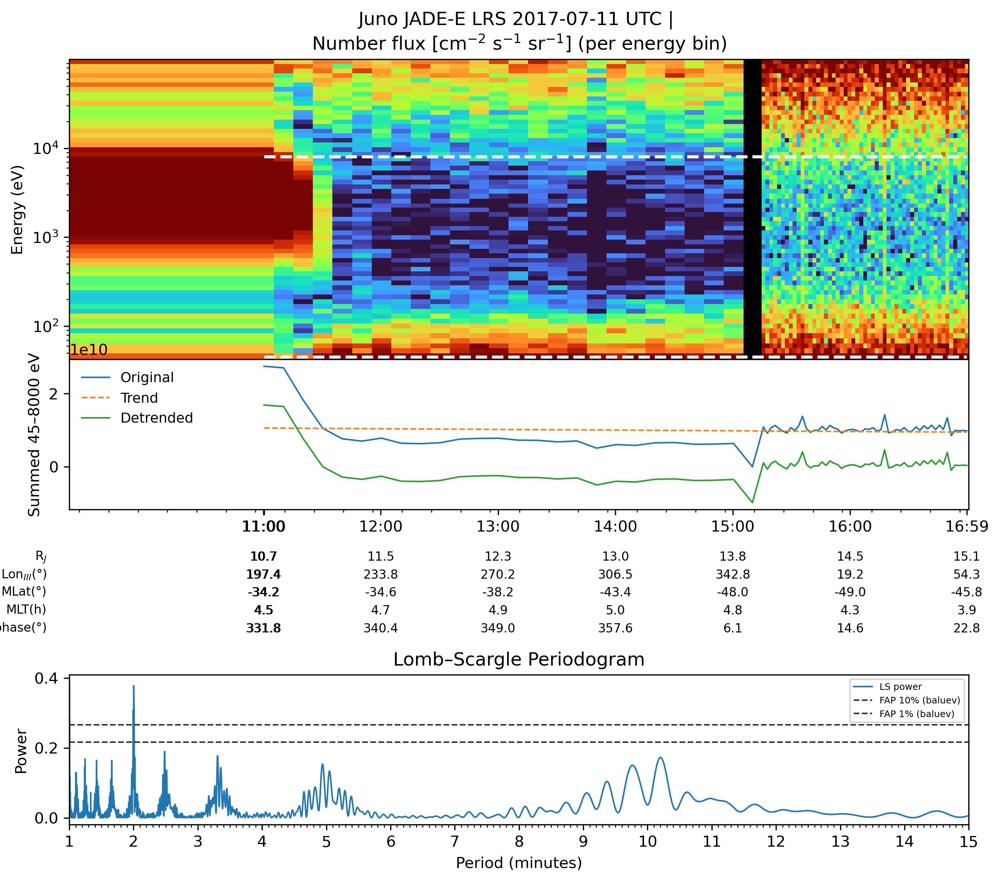

Saved f_pe series:
  JADE_FIGS/JAD_L50_LRS_ELC_ANY_DEF_2017192_V01__fpe_time_hz.npy
  JADE_FIGS/JAD_L50_LRS_ELC_ANY_DEF_2017192_V01__fpe_time_hz.csv
n_e stats [cm^-3]: median=123, min=65.9, max=181
f_pe stats [Hz]: median=9.96e+04, min=7.29e+04, max=1.21e+05
    JADE segment used: 2017-07-11T11:00:23 → 2017-07-11T16:59:38
[LHRL sweep bin=200 Hz] best period=14.47 min @ 949 Hz (power=0.0349)
[LFRH sweep bin=200 Hz] best period=nan min @ nan Hz (power=nan)


/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_35764/2555754988.py:1089: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.02, 1, 0.96])


Saved WAVES fig: WAVES_FIGS/waves_segment.png


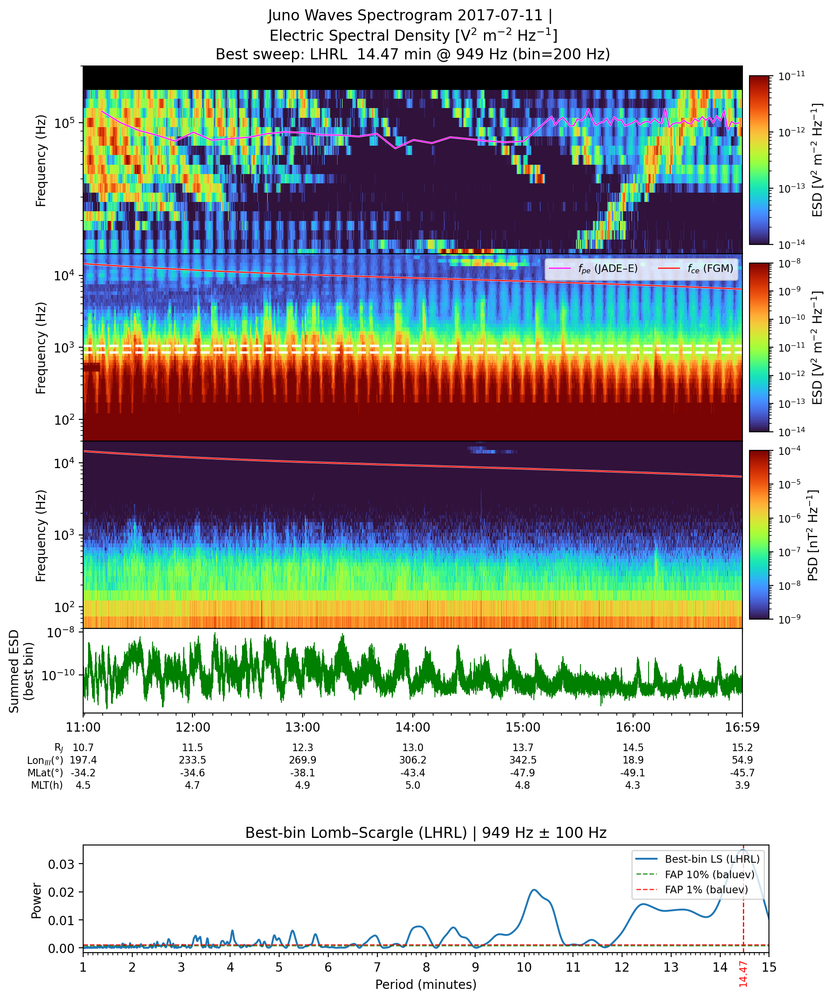


=== : using window 2017-07-16T19:00:00 → 2017-07-17T02:00:00 for JAD_L50_LRS_ELC_ANY_DEF_2017197_V01.LBL ===


/opt/anaconda3/envs/das2env/lib/python3.9/site-packages/pdr/bit_handling.py:174: UserWarning: Data type LSB_UNSIGNED_INTEGER incompatible for bit column. Changing to MSB_BIT_STRING.
  warnings.warn(
/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_35764/2555754988.py:345: RuntimeWarning: Mean of empty slice
  Z_mean = np.nanmean(cube, axis=2)    # (T, 64)
/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_35764/2555754988.py:605: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved JADE fig → JADE_FIGS/JAD_L50_LRS_ELC_ANY_DEF_2017197_V01__jade_segment_analysis.png


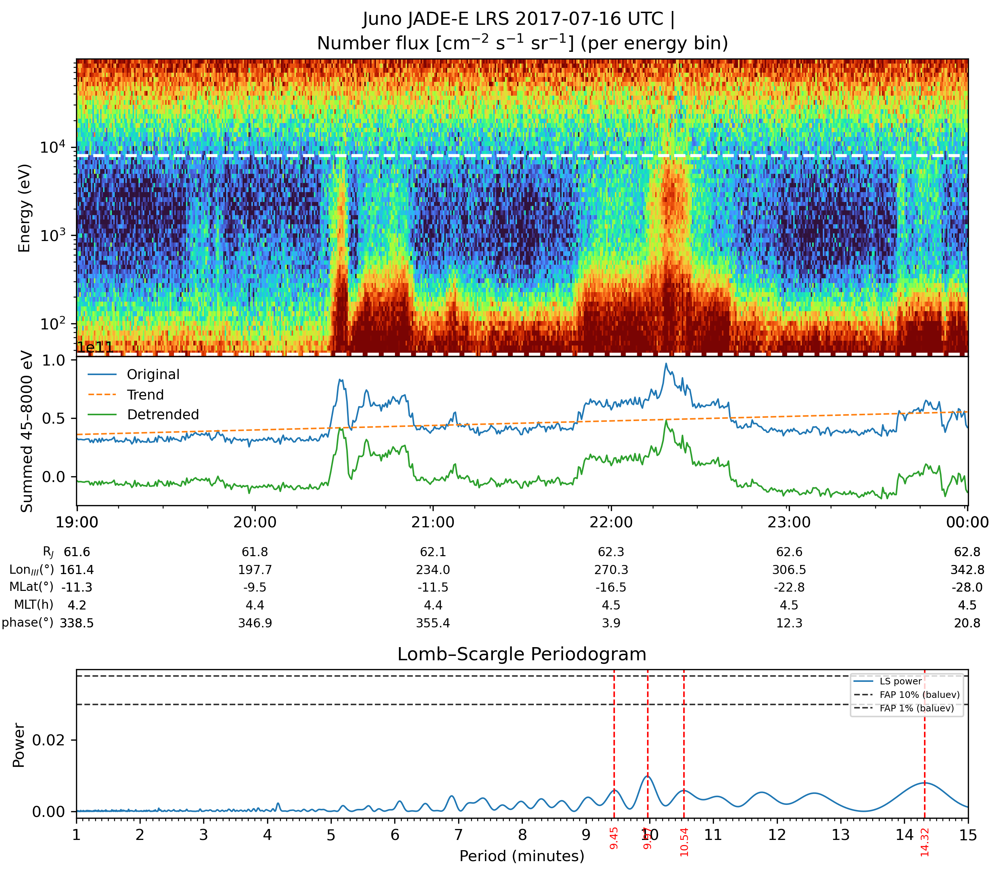

Saved f_pe series:
  JADE_FIGS/JAD_L50_LRS_ELC_ANY_DEF_2017197_V01__fpe_time_hz.npy
  JADE_FIGS/JAD_L50_LRS_ELC_ANY_DEF_2017197_V01__fpe_time_hz.csv
n_e stats [cm^-3]: median=552, min=308, max=1.15e+03
f_pe stats [Hz]: median=2.11e+05, min=1.57e+05, max=3.05e+05
    JADE segment used: 2017-07-16T19:00:00 → 2017-07-17T00:00:00
[LHRL sweep bin=200 Hz] best period=13.26 min @ 749 Hz (power=0.0354)
[LFRH sweep bin=200 Hz] best period=nan min @ nan Hz (power=nan)


/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_35764/2555754988.py:1089: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.02, 1, 0.96])


Saved WAVES fig: WAVES_FIGS/waves_segment.png


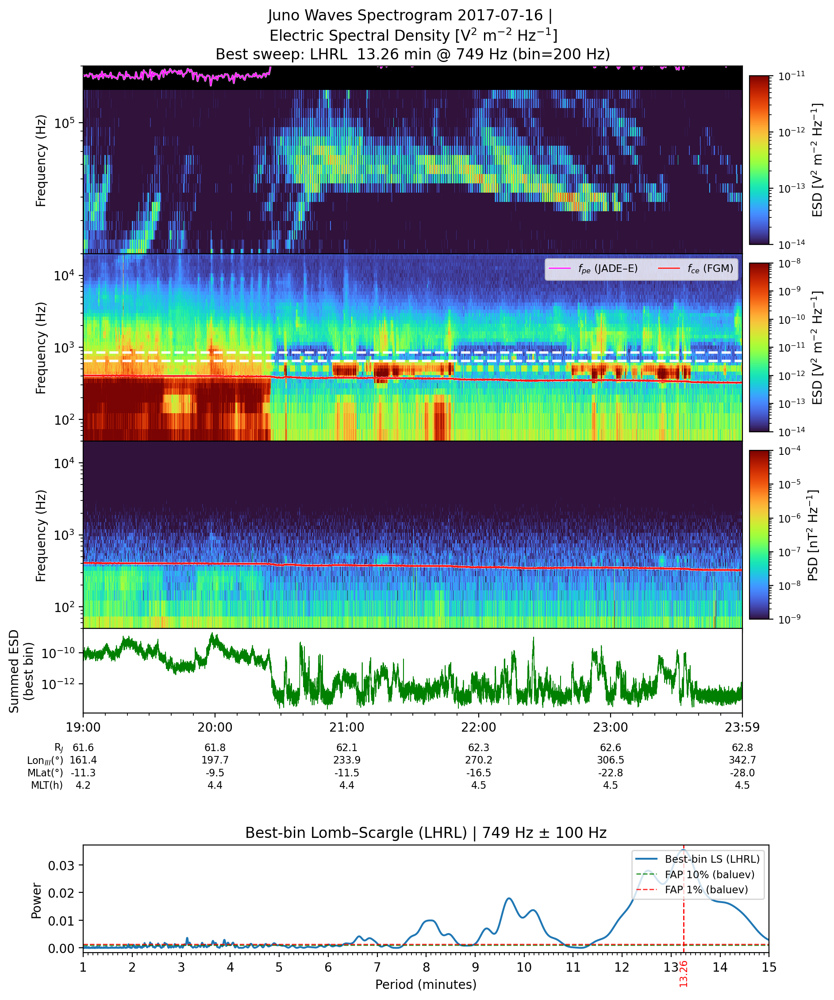


=== : using window 2019-04-02T18:00:00 → 2019-04-02T22:00:00 for JAD_L50_LRS_ELC_ANY_DEF_2019092_V01.LBL ===


/opt/anaconda3/envs/das2env/lib/python3.9/site-packages/pdr/bit_handling.py:174: UserWarning: Data type LSB_UNSIGNED_INTEGER incompatible for bit column. Changing to MSB_BIT_STRING.
  warnings.warn(
/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_35764/2555754988.py:345: RuntimeWarning: Mean of empty slice
  Z_mean = np.nanmean(cube, axis=2)    # (T, 64)
/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_35764/2555754988.py:605: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved JADE fig → JADE_FIGS/JAD_L50_LRS_ELC_ANY_DEF_2019092_V01__jade_segment_analysis.png


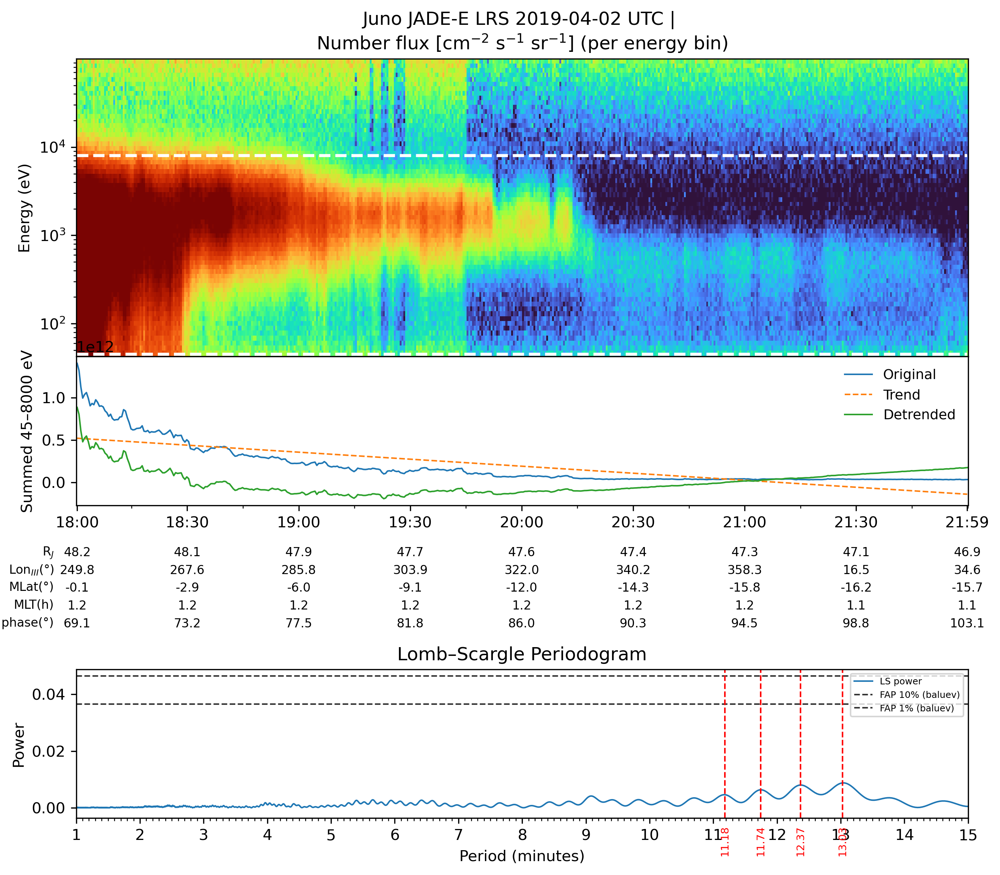

Saved f_pe series:
  JADE_FIGS/JAD_L50_LRS_ELC_ANY_DEF_2019092_V01__fpe_time_hz.npy
  JADE_FIGS/JAD_L50_LRS_ELC_ANY_DEF_2019092_V01__fpe_time_hz.csv
n_e stats [cm^-3]: median=586, min=337, max=1.62e+04
f_pe stats [Hz]: median=2.17e+05, min=1.65e+05, max=1.14e+06
    JADE segment used: 2019-04-02T18:00:22 → 2019-04-02T21:59:52
[LHRL sweep bin=200 Hz] best period=15.00 min @ 949 Hz (power=0.069)
[LFRH sweep bin=200 Hz] best period=nan min @ nan Hz (power=nan)


/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_35764/2555754988.py:1089: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.02, 1, 0.96])


Saved WAVES fig: WAVES_FIGS/waves_segment.png


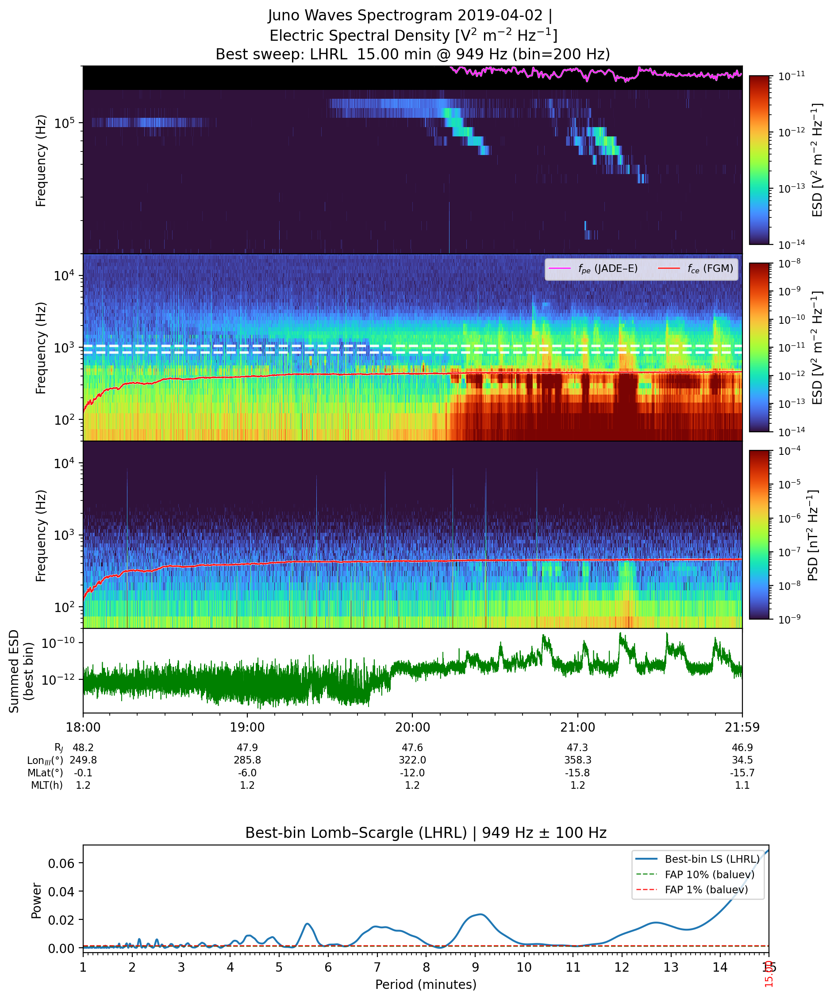


=== : using window 2021-06-03T04:00:00 → 2021-06-03T08:00:00 for JAD_L50_LRS_ELC_ANY_DEF_2021154_V01.LBL ===


/opt/anaconda3/envs/das2env/lib/python3.9/site-packages/pdr/bit_handling.py:174: UserWarning: Data type LSB_UNSIGNED_INTEGER incompatible for bit column. Changing to MSB_BIT_STRING.
  warnings.warn(
/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_35764/2555754988.py:605: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved JADE fig → JADE_FIGS/JAD_L50_LRS_ELC_ANY_DEF_2021154_V01__jade_segment_analysis.png


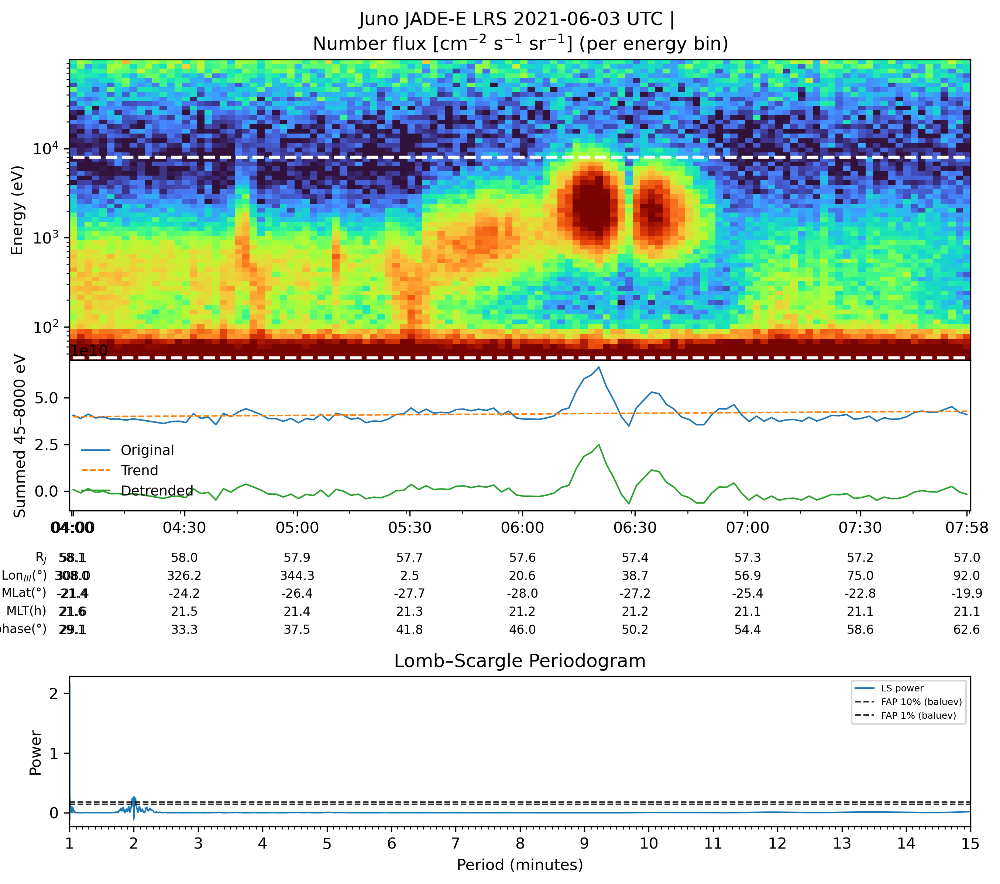

Saved f_pe series:
  JADE_FIGS/JAD_L50_LRS_ELC_ANY_DEF_2021154_V01__fpe_time_hz.npy
  JADE_FIGS/JAD_L50_LRS_ELC_ANY_DEF_2021154_V01__fpe_time_hz.csv
n_e stats [cm^-3]: median=434, min=353, max=573
f_pe stats [Hz]: median=1.87e+05, min=1.69e+05, max=2.15e+05
    JADE segment used: 2021-06-03T04:00:22 → 2021-06-03T07:58:22
[LHRL sweep bin=200 Hz] best period=10.38 min @ 1349 Hz (power=0.0294)
[LFRH sweep bin=200 Hz] best period=nan min @ nan Hz (power=nan)


/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_35764/2555754988.py:1089: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.02, 1, 0.96])


Saved WAVES fig: WAVES_FIGS/waves_segment.png


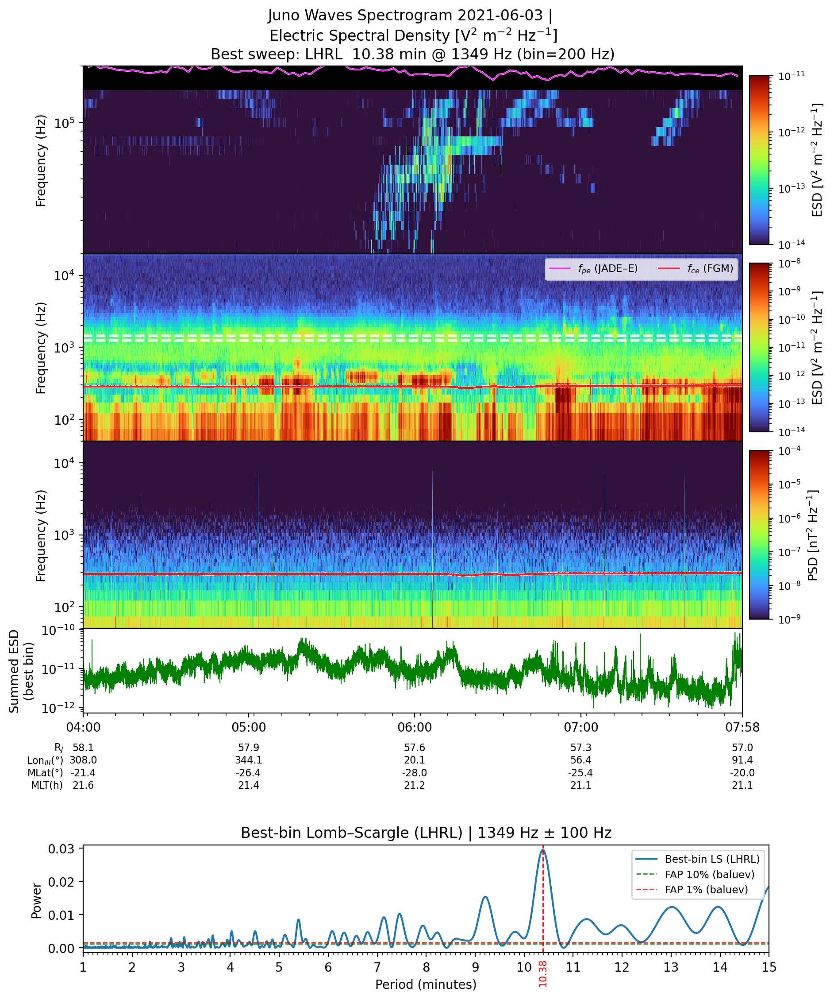


=== : using window 2021-06-08T23:00:00 → 2021-06-09T05:00:00 for JAD_L50_LRS_ELC_ANY_DEF_2021159_V01.LBL ===


/opt/anaconda3/envs/das2env/lib/python3.9/site-packages/pdr/bit_handling.py:174: UserWarning: Data type LSB_UNSIGNED_INTEGER incompatible for bit column. Changing to MSB_BIT_STRING.
  warnings.warn(
/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_35764/2555754988.py:605: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved JADE fig → JADE_FIGS/JAD_L50_LRS_ELC_ANY_DEF_2021159_V01__jade_segment_analysis.png


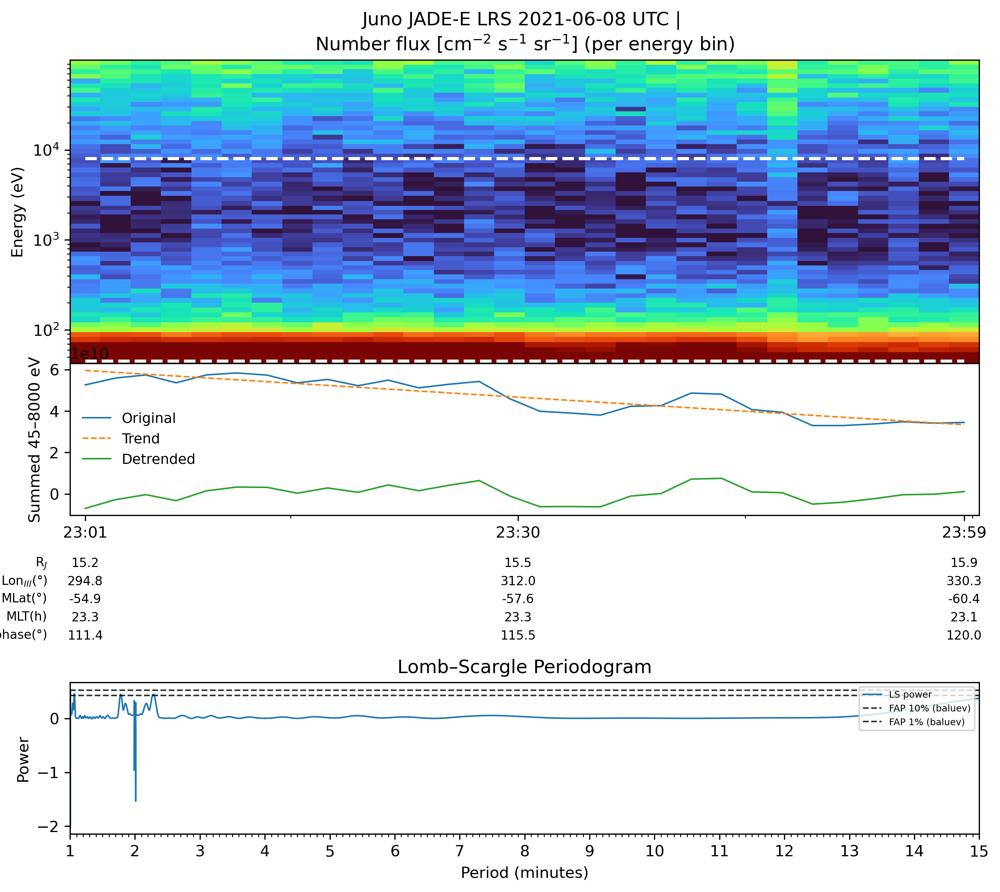

Saved f_pe series:
  JADE_FIGS/JAD_L50_LRS_ELC_ANY_DEF_2021159_V01__fpe_time_hz.npy
  JADE_FIGS/JAD_L50_LRS_ELC_ANY_DEF_2021159_V01__fpe_time_hz.csv
n_e stats [cm^-3]: median=681, min=439, max=805
f_pe stats [Hz]: median=2.34e+05, min=1.88e+05, max=2.55e+05
    JADE segment used: 2021-06-08T23:01:26 → 2021-06-08T23:59:26
[LHRL sweep bin=200 Hz] best period=7.95 min @ 1349 Hz (power=0.112)
[LFRH sweep bin=200 Hz] best period=nan min @ nan Hz (power=nan)


/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_35764/2555754988.py:1089: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.02, 1, 0.96])


Saved WAVES fig: WAVES_FIGS/waves_segment.png


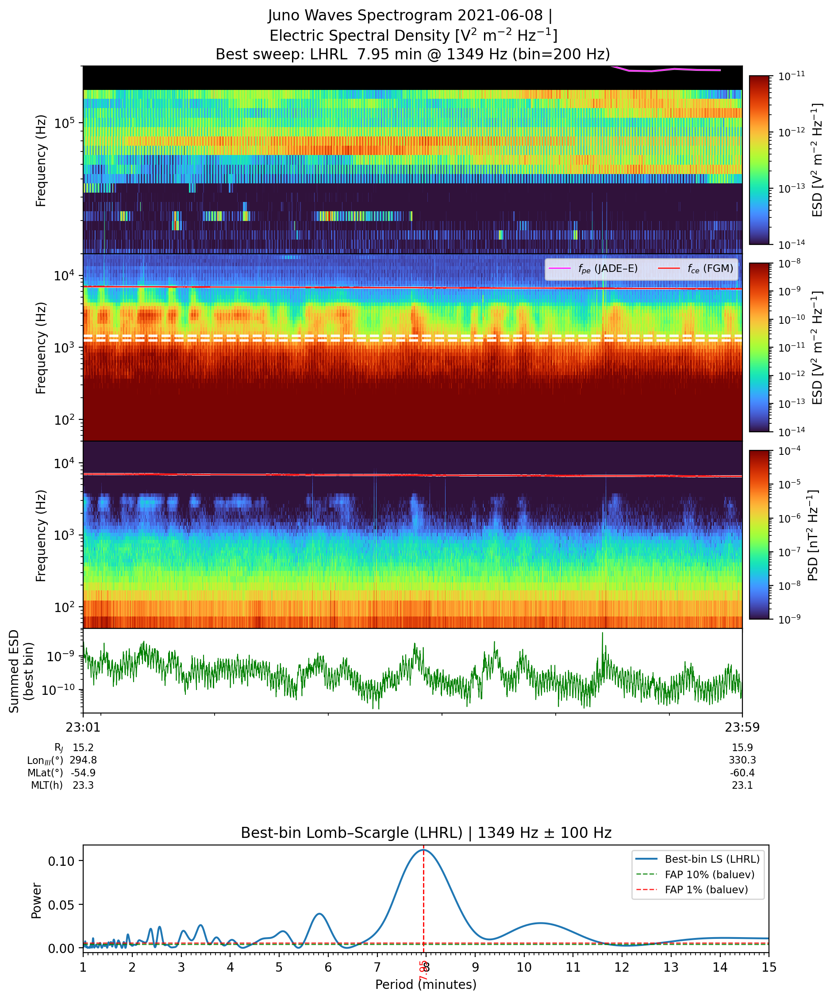

In [4]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
JADE + WAVES (+ MAG) batch driver — SWEPT WAVES VERSION

For each JADE LBL file:
  1) Run JADE analysis to produce:
       - JADE spectrogram + summed band time series + LS periodogram (saved)
       - f_pe(t) from JADE number flux (returned as Hz) + t_unix (s)
       - the exact segment start/end actually used (ISO strings)
  2) Use that same segment time window to fetch Juno WAVES via DAS2:
       - LFRH spectrogram
       - LHRL spectrogram
       - Magnetic spectrogram (b=True)
       - Sweep BOTH electric spectrograms using fixed-width frequency bins (SWEEP_BIN_HZ)
       - Find strongest periodicity (max LS power) per panel, pick global best
       - White dashed bin-edge lines ONLY on the winning electric panel
       - Time-series panel: summed ESD in BEST sweep bin
       - Bottom panel: Lomb–Scargle periodogram for BEST sweep bin
       - overlays of f_pe (JADE) + optional f_ce (FGM)

Dependencies:
  pip install pdr das2 astropy scipy pandas matplotlib numpy
"""

# ──────────────────────────────────────────────────────────────────────────────
# ENV / IMPORTS
# ──────────────────────────────────────────────────────────────────────────────
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FixedLocator
from matplotlib.gridspec import GridSpec
from scipy.signal import find_peaks

from astropy.timeseries import LombScargle
from das2 import get_source
import das2
import pdr

# Avoid CPU oversubscription (macOS / BLAS/FFT libs)
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("VECLIB_MAXIMUM_THREADS", "1")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")

# ──────────────────────────────────────────────────────────────────────────────
# GLOBAL CONFIG
# ──────────────────────────────────────────────────────────────────────────────
# Output folders
JADE_FIG_OUTDIR  = "JADE_FIGS"
WAVES_FIG_OUTDIR = "WAVES_FIGS"
os.makedirs(JADE_FIG_OUTDIR,  exist_ok=True)
os.makedirs(WAVES_FIG_OUTDIR, exist_ok=True)

# --- WAVES DAS2 server ---
SERVER_URL_WAVES = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"
SERVER_URL_EFC   = "tag:das2.org,2012:site:/uiowa/juno/fgm/electroncyclotron/das2"
SERVER_URL_EPH   = "tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2"

# --- JADE analysis defaults ---
ENERGY_MIN_EV    = 45.0
ENERGY_MAX_EV    = 8000.0

# Periodogram settings (minutes)
PERIOD_MIN       = 1.0
PERIOD_MAX       = 15.0
PEAK_DETECT_MIN  = 2.5
NUM_PEAKS        = 4
LS_NFREQ         = 5000

# WAVES plot defaults (Hz axes are Hz)
LFRH_YLIM   = (2e4, 2e5)
LHRL_YLIM   = (5e1, 2e4)
B_YLIM      = (5e1, 2e4)

LFRH_LOGNORM = (1e-14, 1e-11)
LHRL_LOGNORM = (1e-14, 1e-8)
B_LOGNORM    = (1e-9, 1e-4)

# Overlays
OVERLAY_LW    = 1.0
OVERLAY_ALPHA = 0.9
PLOT_FCE_FZ_FUHR = True

# --- Sweep-bin periodicity settings for WAVES (Hz) ---
SWEEP_BIN_HZ = 200.0
MIN_CHANNELS_PER_BIN = 2
MIN_FINITE_FRAC = 0.6

# ──────────────────────────────────────────────────────────────────────────────
# JADE CONSTANTS (your hard-coded 64 energy centers)
# ──────────────────────────────────────────────────────────────────────────────
ENERGY_BINS_EV = np.array([
    4.5731E+001, 5.3296E+001, 6.0349E+001, 6.8611E+001, 7.7419E+001,
    8.9858E+001, 1.0039E+002, 1.1494E+002, 1.2908E+002, 1.4807E+002,
    1.6538E+002, 1.8943E+002, 2.1210E+002, 2.4241E+002, 2.7057E+002,
    3.0856E+002, 3.4290E+002, 3.9006E+002, 4.3681E+002, 4.9299E+002,
    5.5223E+002, 6.2153E+002, 6.9798E+002, 7.8441E+002, 8.8190E+002,
    9.9458E+002, 1.1175E+003, 1.2632E+003, 1.4210E+003, 1.6066E+003,
    1.8068E+003, 2.0410E+003, 2.2617E+003, 2.5464E+003, 2.9011E+003,
    3.2921E+003, 3.7061E+003, 4.1751E+003, 4.7001E+003, 5.2996E+003,
    5.9765E+003, 6.7664E+003, 7.6124E+003, 8.5852E+003, 9.6487E+003,
    1.0927E+004, 1.2282E+004, 1.3872E+004, 1.5623E+004, 1.7610E+004,
    1.9783E+004, 2.2346E+004, 2.5209E+004, 2.8414E+004, 3.2039E+004,
    3.6123E+004, 4.0668E+004, 4.5886E+004, 5.1684E+004, 5.8298E+004,
    6.5677E+004, 7.4021E+004, 8.3346E+004, 9.3975E+004
], dtype=float)

N_E, N_LOOK = 64, 48
N_COLS = N_E * N_LOOK

# ──────────────────────────────────────────────────────────────────────────────
# SWEEP HELPERS (WAVES)
# ──────────────────────────────────────────────────────────────────────────────
def sweep_strongest_periodicity(
    times, freqs, spec_2d,
    bin_hz=200.0,
    period_min=1.0, period_max=15.0,
    ls_nfreq=5000,
    peak_detect_min=2.5,
    detrend=True,
    min_channels_per_bin=2,
    min_finite_frac=0.6,
):
    import numpy as np
    from astropy.timeseries import LombScargle

    times = np.asarray(times)
    freqs = np.asarray(freqs, float)
    spec  = np.asarray(spec_2d, float)

    if spec.ndim != 2:
        raise ValueError(f"spec_2d must be 2D (Nt,Nf); got {spec.shape}")
    if spec.shape[0] != times.size:
        raise ValueError("spec_2d first dimension must match times")
    if spec.shape[1] != freqs.size:
        raise ValueError("spec_2d second dimension must match freqs")

    t0 = times[0]
    t_sec = (times - t0) / np.timedelta64(1, "s")
    t_sec = np.asarray(t_sec, float)

    fmin = 1.0 / (period_max * 60.0)
    fmax = 1.0 / (period_min * 60.0)
    ls_freq = np.linspace(fmin, fmax, ls_nfreq)
    periods_ls_min = (1.0 / ls_freq) / 60.0

    f_lo, f_hi = float(np.nanmin(freqs)), float(np.nanmax(freqs))
    half = 0.5 * float(bin_hz)
    start = f_lo + half
    stop  = f_hi - half
    if stop <= start:
        raise ValueError("bin_hz too large for this spectrogram span")

    bin_centers = np.arange(start, stop + 1e-9, float(bin_hz))
    best_periods = np.full(bin_centers.shape, np.nan, float)
    best_powers  = np.full(bin_centers.shape, np.nan, float)

    best_bin_idx = None

    def _linear_detrend(y):
        x = t_sec
        msk = np.isfinite(y) & np.isfinite(x)
        if np.count_nonzero(msk) < 4:
            return y - np.nanmean(y)
        coeff = np.polyfit(x[msk], y[msk], 1)
        tr = np.polyval(coeff, x)
        r = y - tr
        r = r - np.nanmean(r)
        return r

    pmin_mask = periods_ls_min >= float(peak_detect_min)
    if not np.any(pmin_mask):
        raise ValueError("peak_detect_min too large for LS grid")

    for i, fc in enumerate(bin_centers):
        lo = fc - half
        hi = fc + half
        ch = (freqs >= lo) & (freqs <= hi)
        if int(np.count_nonzero(ch)) < min_channels_per_bin:
            continue

        y = np.nansum(spec[:, ch], axis=1)

        finite_frac = np.count_nonzero(np.isfinite(y)) / y.size
        if finite_frac < min_finite_frac:
            continue

        y_use = _linear_detrend(y) if detrend else (y - np.nanmean(y))

        msk = np.isfinite(y_use) & np.isfinite(t_sec)
        if np.count_nonzero(msk) < 6:
            continue

        ls = LombScargle(t_sec[msk], y_use[msk], normalization="standard", center_data=False)
        power = ls.power(ls_freq)

        power2 = power.copy()
        power2[~pmin_mask] = -np.inf

        j = int(np.nanargmax(power2))
        best_periods[i] = float(periods_ls_min[j])
        best_powers[i]  = float(power[j])

        if best_bin_idx is None or best_powers[i] > best_powers[best_bin_idx]:
            best_bin_idx = i

    if best_bin_idx is None:
        return {
            "best_period_min": np.nan,
            "best_bin_center_hz": np.nan,
            "best_power": np.nan,
            "bin_centers_hz": bin_centers,
            "best_periods_min": best_periods,
            "best_powers": best_powers,
            "best_bin_index": None,
        }

    return {
        "best_period_min": float(best_periods[best_bin_idx]),
        "best_bin_center_hz": float(bin_centers[best_bin_idx]),
        "best_power": float(best_powers[best_bin_idx]),
        "bin_centers_hz": bin_centers,
        "best_periods_min": best_periods,
        "best_powers": best_powers,
        "best_bin_index": int(best_bin_idx),
    }


def bestbin_timeseries_and_ls(
    times, freqs, spec_2d,
    bin_center_hz, bin_hz,
    period_min, period_max,
    ls_nfreq,
    detrend=True,
):
    import numpy as np
    from astropy.timeseries import LombScargle

    times = np.asarray(times)
    freqs = np.asarray(freqs, float)
    spec  = np.asarray(spec_2d, float)

    half = 0.5 * float(bin_hz)
    lo = float(bin_center_hz) - half
    hi = float(bin_center_hz) + half
    ch = (freqs >= lo) & (freqs <= hi)
    if np.count_nonzero(ch) < 2:
        raise RuntimeError("Best-bin has too few channels.")

    y = np.nansum(spec[:, ch], axis=1)

    t0 = times[0]
    t_sec = (times - t0) / np.timedelta64(1, "s")
    t_sec = np.asarray(t_sec, float)

    if detrend:
        m = np.isfinite(y) & np.isfinite(t_sec)
        if np.count_nonzero(m) >= 4:
            coeff = np.polyfit(t_sec[m], y[m], 1)
            tr = np.polyval(coeff, t_sec)
            y_use = y - tr
        else:
            y_use = y.copy()
        y_use = y_use - np.nanmean(y_use)
    else:
        y_use = y - np.nanmean(y)

    msk = np.isfinite(y_use) & np.isfinite(t_sec)
    if np.count_nonzero(msk) < 6:
        raise RuntimeError("Too few finite samples for LS.")

    fmin = 1.0 / (period_max * 60.0)
    fmax = 1.0 / (period_min * 60.0)
    ls_freq = np.linspace(fmin, fmax, ls_nfreq)
    periods_min = (1.0 / ls_freq) / 60.0

    ls = LombScargle(t_sec[msk], y_use[msk], normalization="standard", center_data=False)
    power = ls.power(ls_freq)

    order = np.argsort(periods_min)
    periods_min = periods_min[order]
    power = power[order]

    try:
        thr_10 = ls.false_alarm_level(0.10, method="baluev", minimum_frequency=fmin, maximum_frequency=fmax)
        thr_01 = ls.false_alarm_level(0.01, method="baluev", minimum_frequency=fmin, maximum_frequency=fmax)
        fap_method = "baluev"
    except Exception:
        thr_10 = ls.false_alarm_level(0.10, method="naive", minimum_frequency=fmin, maximum_frequency=fmax)
        thr_01 = ls.false_alarm_level(0.01, method="naive", minimum_frequency=fmin, maximum_frequency=fmax)
        fap_method = "naive"

    return {
        "bin_lo_hz": lo,
        "bin_hi_hz": hi,
        "sum_esd": y,
        "periods_min": periods_min,
        "power": power,
        "thr10": thr_10,
        "thr01": thr_01,
        "fap_method": fap_method,
    }

# ──────────────────────────────────────────────────────────────────────────────
# JADE HELPERS
# ──────────────────────────────────────────────────────────────────────────────
def energy_edges_from_centers(e):
    """Geometric midpoints; extrapolated outer edges."""
    e = np.asarray(e, float)
    mids = np.sqrt(e[:-1] * e[1:])
    return np.concatenate([[e[0]**2 / mids[0]], mids, [e[-1]**2 / mids[-1]]])


def load_jade_cube(lbl_path):
    ds = pdr.read(lbl_path)
    df = ds["TABLE"]

    t_lo = pd.to_datetime(df["DIM0_UTC_LOWER"].astype(str), format="%Y-%jT%H:%M:%S.%f", utc=False)
    t_hi = pd.to_datetime(df["DIM0_UTC_UPPER"].astype(str), format="%Y-%jT%H:%M:%S.%f", utc=False)

    pat = re.compile(r"^DATA_(\d+)$", re.IGNORECASE)
    pairs = []
    for c in df.columns:
        m = pat.match(str(c))
        if m:
            pairs.append((int(m.group(1)), c))
    pairs.sort(key=lambda x: x[0])
    data_cols = [c for _, c in pairs]
    if len(data_cols) != N_COLS:
        raise ValueError(f"Expected {N_COLS} DATA columns, got {len(data_cols)}")

    raw = df[data_cols].to_numpy(dtype=float)
    raw[raw <= -9.0e5] = np.nan

    nt = len(df)
    cube = raw.reshape(nt, N_E, N_LOOK)  # (T, 64, 48)
    Z_mean = np.nanmean(cube, axis=2)    # (T, 64)

    mask = t_lo.notna() & t_hi.notna()
    t_lo = t_lo[mask].reset_index(drop=True)
    t_hi = t_hi[mask].reset_index(drop=True)
    Z_mean = Z_mean[mask.values, :]

    ord_idx = np.argsort(t_lo.values)
    t_lo = t_lo.iloc[ord_idx].reset_index(drop=True)
    t_hi = t_hi.iloc[ord_idx].reset_index(drop=True)
    Z_mean = Z_mean[ord_idx, :]

    t_edges = pd.DatetimeIndex(np.concatenate([t_lo.values[:1], t_hi.values]))
    t_centers = t_lo + (t_hi - t_lo) / 2

    sorter = np.argsort(ENERGY_BINS_EV)
    e_sorted = ENERGY_BINS_EV[sorter]
    Zp = Z_mean[:, sorter]
    e_edges = energy_edges_from_centers(e_sorted)

    return t_edges, t_centers, e_sorted, e_edges, Zp


def summarize_between_lines(e_sorted, Zp, emin_ev, emax_ev):
    mask_e = (e_sorted >= emin_ev) & (e_sorted <= emax_ev)
    if not np.any(mask_e):
        raise ValueError("Energy mask is empty; check ENERGY_MIN_EV/ENERGY_MAX_EV.")
    summed = np.nansum(Zp[:, mask_e], axis=1)
    return summed, mask_e


def _interpolate_nans_time(times_ns, y):
    """Time-based interpolation for NaNs (keeps sampling)."""
    y = np.asarray(y, float)
    if np.all(np.isfinite(y)):
        return y
    s = pd.Series(y, index=pd.to_datetime(times_ns))
    s = s.interpolate(method="time").bfill().ffill()
    return s.to_numpy(dtype=float)

# ──────────────────────────────────────────────────────────────────────────────
# JADE MAIN: plot + compute f_pe(t) + return fpe_hz,t_unix, seg window
# ──────────────────────────────────────────────────────────────────────────────
def make_segment_analysis_from_pds3(
    lbl_path,
    start_time=None,
    end_time=None,
    emin_ev=ENERGY_MIN_EV,
    emax_ev=ENERGY_MAX_EV,
    period_min=PERIOD_MIN,
    period_max=PERIOD_MAX,
    peak_detect_min=PEAK_DETECT_MIN,
    num_peaks=NUM_PEAKS,
    ls_nfreq=LS_NFREQ,
    save_png=True,
    fig_outdir=JADE_FIG_OUTDIR,
    label="segment",
):
    # Load PDS3 + build arrays
    t_edges, t_centers, e_sorted, e_edges, Zp = load_jade_cube(lbl_path)

    # If no window passed, use full file coverage
    if start_time is None or end_time is None:
        t0 = pd.to_datetime(t_centers.iloc[0])
        t1 = pd.to_datetime(t_centers.iloc[-1])
    else:
        t0 = pd.to_datetime(start_time)
        t1 = pd.to_datetime(end_time)

    mask_t = (t_centers >= t0) & (t_centers <= t1)
    if not np.any(mask_t):
        raise ValueError("Time window selects no samples; check start_time/end_time.")

    times_win = t_centers[mask_t].to_numpy(dtype="datetime64[ns]")
    Z_win     = Zp[mask_t.values, :]

    # Actual segment used (ISO strings for WAVES)
    seg_start_iso = pd.to_datetime(times_win[0]).strftime("%Y-%m-%dT%H:%M:%S")
    seg_end_iso   = pd.to_datetime(times_win[-1]).strftime("%Y-%m-%dT%H:%M:%S")

    # Sum between lines
    avg_counts, mask_e = summarize_between_lines(e_sorted, Z_win, emin_ev, emax_ev)
    avg_counts = _interpolate_nans_time(times_win, avg_counts)

    # Detrend linear
    t0c = times_win[0]
    t_sec = (times_win - t0c) / np.timedelta64(1, "s")
    if len(t_sec) < 4:
        raise ValueError("Too few samples in window for periodogram.")
    dt_s = float(np.median(np.diff(t_sec)))
    if not np.isfinite(dt_s) or dt_s <= 0:
        raise ValueError("Non-positive or invalid cadence; check time ordering/data gaps.")

    coeff = np.polyfit(t_sec, avg_counts, 1)
    trend = np.polyval(coeff, t_sec)
    residual = avg_counts - trend
    residual = residual - np.mean(residual)

    # Lomb–Scargle
    fmin = 1.0 / (period_max * 60.0)
    fmax = 1.0 / (period_min * 60.0)
    freq = np.linspace(fmin, fmax, ls_nfreq)

    ls = LombScargle(t_sec, residual, normalization="standard", center_data=False)
    power = ls.power(freq)

    periods_mask = (1.0 / freq) / 60.0
    order = np.argsort(periods_mask)
    periods_ls = periods_mask[order]
    power_ls   = power[order]

    # Peak picking
    peaks, _ = find_peaks(power_ls)
    if peaks.size:
        sel = peaks[np.argsort(power_ls[peaks])][-num_peaks:]
        sel = np.sort(sel)
        peak_periods = periods_ls[sel]
        peak_powers  = power_ls[sel]

        keep = peak_periods >= peak_detect_min
        peak_periods = peak_periods[keep]
        peak_powers  = peak_powers[keep]

        o2 = np.argsort(peak_periods)
        peak_periods = peak_periods[o2]
        peak_powers  = peak_powers[o2]
    else:
        peak_periods = np.array([], dtype=float)
        peak_powers  = np.array([], dtype=float)

    # FAP thresholds
    try:
        thr_10 = ls.false_alarm_level(0.10, method="baluev",
                                     minimum_frequency=fmin, maximum_frequency=fmax)
        thr_01 = ls.false_alarm_level(0.01, method="baluev",
                                     minimum_frequency=fmin, maximum_frequency=fmax)
        fap_method = "baluev"
    except Exception:
        thr_10 = ls.false_alarm_level(0.10, method="naive",
                                     minimum_frequency=fmin, maximum_frequency=fmax)
        thr_01 = ls.false_alarm_level(0.01, method="naive",
                                     minimum_frequency=fmin, maximum_frequency=fmax)
        fap_method = "naive"

    # ───────────── Plot JADE figure ─────────────
    basename = os.path.splitext(os.path.basename(lbl_path))[0]
    fig = plt.figure(figsize=(10.5, 9), dpi=300)
    outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[3, 1], hspace=0.55)
    inner_gs = outer_gs[0].subgridspec(2, 1, height_ratios=[2, 1], hspace=0.0)

    ax_spec = fig.add_subplot(inner_gs[0])
    ax_avg  = fig.add_subplot(inner_gs[1], sharex=ax_spec)
    ax_fft  = fig.add_subplot(outer_gs[1])

    # Spectrogram edges for the window
    idx0 = np.where(t_centers.to_numpy() >= times_win[0])[0][0]
    idx1 = np.where(t_centers.to_numpy() <= times_win[-1])[0][-1]
    t_edges_win = t_edges[idx0: idx1 + 2]

    Zpos = Z_win[np.isfinite(Z_win) & (Z_win > 0)]
    if Zpos.size == 0:
        raise RuntimeError("No positive values to plot.")
    vmin, vmax = np.nanpercentile(Zpos, [5, 95])
    vmin = max(vmin, np.nextafter(0.0, 1.0))

    ax_spec.pcolormesh(
        t_edges_win, e_edges, Z_win.T, shading="auto",
        norm=LogNorm(vmin=vmin, vmax=vmax), cmap="turbo"
    )
    ax_spec.set_yscale("log")
    ax_spec.set_facecolor("black")
    ax_spec.plot([times_win[0], times_win[-1]], [emin_ev, emin_ev], "--w", lw=2)
    ax_spec.plot([times_win[0], times_win[-1]], [emax_ev, emax_ev], "--w", lw=2)
    ax_spec.set_ylabel("Energy (eV)")
    ax_spec.set_title(
        f"Juno JADE-E LRS {pd.to_datetime(times_win[0]).strftime('%Y-%m-%d')} UTC | {label}\n"
        + r"Number flux [$\mathrm{cm^{-2}\ s^{-1}\ sr^{-1}}$] (per energy bin)"
    )
    ax_spec.tick_params(labelbottom=False)

    ax_avg.plot(times_win, avg_counts, label="Original", color="C0", lw=1.0)
    ax_avg.plot(times_win, trend, linestyle="--", color="C1", label="Trend", lw=1.0)
    ax_avg.plot(times_win, residual, color="C2", label="Detrended", lw=1.0)
    ax_avg.set_ylabel(f"Summed {emin_ev:.0f}–{emax_ev:.0f} eV")
    ax_avg.legend(frameon=False, fontsize=9)

    # Ticks
    total_hours = (times_win[-1] - times_win[0]) / np.timedelta64(1, "h")
    tick_interval_h = 1 if total_hours <= 12 else 2
    eph_step = np.timedelta64(30, "m") if total_hours <= 4 else np.timedelta64(int(tick_interval_h), "h")

    t0h = times_win[0].astype("datetime64[h]")
    t1h = times_win[-1].astype("datetime64[h]") + np.timedelta64(1, "h")
    maj = np.arange(t0h, t1h, eph_step)
    all_ticks = np.unique(np.concatenate(([times_win[0]], maj, [times_win[-1]])))
    py_ticks  = [pd.to_datetime(t).to_pydatetime() for t in all_ticks]
    tick_nums = mdates.date2num(py_ticks)

    ax_avg.xaxis.set_major_locator(FixedLocator(tick_nums))
    ax_avg.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax_avg.xaxis.set_minor_locator(mdates.MinuteLocator(interval=10))
    plt.setp(ax_avg.get_xticklabels(which="major"), rotation=0)

    # Ephemeris rows (uses seg_start/seg_end)
    eph_src = get_source(SERVER_URL_EPH)
    ds_eph = eph_src.get({"time": (seg_start_iso, seg_end_iso, int(max(1, round(dt_s))))})[0]

    eph_t  = ds_eph["time"]["center"].array
    rad    = ds_eph["radius"]["center"].array
    lon3   = ds_eph["long"]["center"].array
    mlatE  = ds_eph["mlat"]["center"].array
    mltE   = ds_eph["mlt"]["center"].array
    ioE    = ds_eph["io_phase"]["center"].array
    if getattr(mltE, "dtype", None) is not None and mltE.dtype.kind == "m":
        mltE = (mltE / np.timedelta64(1, "h")).astype(float)

    row_lbls   = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)", "Io phase(°)"]
    row_arrays = [rad, lon3, mlatE, mltE, ioE]
    row_spacing = 0.12

    idxs = [int(np.argmin(np.abs(eph_t - np.datetime64(t)))) for t in all_ticks]
    for j, (lab, arr) in enumerate(zip(row_lbls, row_arrays)):
        off = -row_spacing * (j + 2)
        sax = ax_avg.secondary_xaxis(off, functions=(lambda x: x, lambda x: x))
        sax.xaxis.set_major_locator(FixedLocator(tick_nums))
        vals = arr[idxs]
        sax.set_xticklabels([f"{float(v):.1f}" for v in vals], rotation=0, va="top", fontsize=8)
        sax.spines["bottom"].set_visible(False)
        sax.tick_params(axis="x", length=0)
        sax.xaxis.set_ticks_position("bottom")
        sax.xaxis.set_label_position("bottom")
        txt = sax.set_xlabel(lab, fontsize=8, labelpad=-8.5, loc="left")
        txt.set_x(-0.025)
        txt.set_ha("right")

    # LS plot
    ax_fft.plot(periods_ls, power_ls, color="C0", linewidth=1, label="LS power")
    ax_fft.axhline(thr_10, ls="--", lw=1, color="k", alpha=0.8, label=f"FAP 10% ({fap_method})")
    ax_fft.axhline(thr_01, ls="--", lw=1, color="k", alpha=0.8, label=f"FAP 1% ({fap_method})")
    for p in peak_periods:
        ax_fft.axvline(p, ls="--", color="red", lw=1)
        ax_fft.text(
            p, -0.05, f"{p:.2f}",
            transform=ax_fft.get_xaxis_transform(),
            rotation=90, va="top", ha="center",
            color="red", fontsize=7
        )

    ax_fft.set_xlim(period_min, period_max)
    ax_fft.set_xlabel("Period (minutes)")
    ax_fft.set_ylabel("Power")
    ax_fft.set_title("Lomb–Scargle Periodogram")
    ax_fft.xaxis.set_major_locator(MultipleLocator(1))
    ax_fft.xaxis.set_minor_locator(AutoMinorLocator(10))
    ax_fft.legend(loc="upper right", frameon=True, fontsize=6, title_fontsize=7)

    ax_spec.xaxis.set_major_locator(FixedLocator(tick_nums))
    ax_spec.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax_spec.xaxis.set_minor_locator(mdates.MinuteLocator(interval=15))

    fig.tight_layout()

    if save_png:
        os.makedirs(fig_outdir, exist_ok=True)
        out = os.path.join(fig_outdir, f"{basename}_{label}_jade_segment_analysis.png")
        fig.savefig(out, dpi=300, bbox_inches="tight")
        print(f"Saved JADE fig → {out}")

    plt.show()

    # ───────────── f_pe(t) from JADE number flux ─────────────
    E_ev   = e_sorted.astype(float)
    dE_ev  = np.diff(e_edges).astype(float)  # (64,)

    if not (Z_win.shape[1] == dE_ev.size == e_sorted.size == 64):
        raise ValueError(f"Shape mismatch: Z_win {Z_win.shape}, dE {dE_ev.size}, e_sorted {e_sorted.size}")

    j_per_eV = Z_win / dE_ev[np.newaxis, :]

    me = 9.10938356e-31
    qe = 1.602176634e-19
    v_cms = np.sqrt(2.0 * (E_ev * qe) / me) * 100.0

    emask = (E_ev >= 50.0) & (E_ev <= 20000.0)
    integrand = j_per_eV[:, emask] / v_cms[np.newaxis, emask]
    ne_cm3 = 4.0 * np.pi * np.trapz(integrand, x=E_ev[emask], axis=1)

    fpe_hz  = 8980.0 * np.sqrt(np.clip(ne_cm3, 0, None))

    t_unix = (times_win.astype("datetime64[ns]").astype("int64") / 1e9).astype(float)
    fpe_2d = np.column_stack([t_unix, fpe_hz])

    base = os.path.splitext(os.path.basename(lbl_path))[0]
    os.makedirs(fig_outdir, exist_ok=True)
    out_npy = os.path.join(fig_outdir, f"{base}_{label}_fpe_time_hz.npy")
    out_csv = os.path.join(fig_outdir, f"{base}_{label}_fpe_time_hz.csv")
    np.save(out_npy, fpe_2d)
    np.savetxt(out_csv, fpe_2d, delimiter=",", header="unix_time_s,f_pe_Hz", comments="")

    print(f"Saved f_pe series:\n  {out_npy}\n  {out_csv}")
    print(f"n_e stats [cm^-3]: median={np.nanmedian(ne_cm3):.3g}, "
          f"min={np.nanmin(ne_cm3):.3g}, max={np.nanmax(ne_cm3):.3g}")
    print(f"f_pe stats [Hz]: median={np.nanmedian(fpe_hz):.3g}, "
          f"min={np.nanmin(fpe_hz):.3g}, max={np.nanmax(fpe_hz):.3g}")

    return fpe_hz, t_unix, seg_start_iso, seg_end_iso

# ──────────────────────────────────────────────────────────────────────────────
# WAVES FUNCTION (SWEPT VERSION)
# ──────────────────────────────────────────────────────────────────────────────
def make_waves_segment(
    start_time,
    end_time,
    fpe_hz,
    t_fpe_input,
    server_url=SERVER_URL_WAVES,
    period_min=PERIOD_MIN,
    period_max=PERIOD_MAX,
    peak_detect_min=PEAK_DETECT_MIN,
    ls_nfreq=LS_NFREQ,
    label="segment",
    outdir=WAVES_FIG_OUTDIR,
    save_fig=True,
    show_fig=True,
    sweep_bin_hz=SWEEP_BIN_HZ,
    overlay_lw=OVERLAY_LW,
    overlay_alpha=OVERLAY_ALPHA,
    plot_fce_fz_fuhr=PLOT_FCE_FZ_FUHR,
    lfrh_ylim=LFRH_YLIM,
    lhrl_ylim=LHRL_YLIM,
    lfrh_lognorm=LFRH_LOGNORM,
    lhrl_lognorm=LHRL_LOGNORM,
    plot_b_panel=True,
    b_ylim=B_YLIM,
    b_lognorm=B_LOGNORM,
):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    import matplotlib.patheffects as pe
    from matplotlib.colors import LogNorm
    from matplotlib.gridspec import GridSpec
    from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FixedLocator
    from das2 import get_source
    import das2

    # Fetch WAVES
    source = get_source(server_url)
    ds = source.get({'time': (start_time, end_time, 1.0)})
    if len(ds) < 2:
        raise RuntimeError("Expected at least two datasets from DAS2 (whistler + middle).")
    whis, middle = ds[0], ds[1]

    def extract_arrays(d):
        f_arr = d['frequency']['center'].array
        freqs = f_arr[0, :] if getattr(f_arr, "ndim", 1) > 1 else f_arr

        t_arr = d['Time']['center'].array
        times = t_arr[:, 0] if getattr(t_arr, "ndim", 1) > 1 else t_arr

        spec  = d['spec_dens']['center'].array.squeeze()
        if spec.ndim != 2:
            raise ValueError(f"spec_dens not 2D after squeeze; got shape {spec.shape}")
        if spec.shape[1] != freqs.size:
            spec = spec.T

        return (
            np.array(times, dtype='datetime64[ms]'),
            np.asarray(freqs, float),
            np.asarray(spec, float),
        )

    times_lhrl, freqs_lhrl, spec_lhrl = extract_arrays(whis)
    times_lfrh, freqs_lfrh, spec_lfrh = extract_arrays(middle)

    def sanitize_linear(a):
        a = np.asarray(a, float).copy()
        a[~np.isfinite(a)] = np.nan
        a[a <= 0] = np.nan
        return a

    spec_lhrl_plot = sanitize_linear(spec_lhrl)
    spec_lfrh_plot = sanitize_linear(spec_lfrh)

    # MAG (b=True)
    times_b = freqs_b = spec_b = None
    spec_b_plot = None
    if plot_b_panel:
        try:
            ds_b = source.get({'time': (start_time, end_time, 1.0), 'b': True})
            if len(ds_b) < 1:
                print("No magnetic dataset returned for b=True; skipping B panel.")
                plot_b_panel = False
            else:
                times_b, freqs_b, spec_b = extract_arrays(ds_b[0])
                spec_b_plot = sanitize_linear(spec_b)
        except Exception as e:
            print(f"Failed to retrieve magnetic dataset (b=True): {e}")
            plot_b_panel = False

    # Sweep LHRL + LFRH
    sweep_lhrl = sweep_strongest_periodicity(
        times=times_lhrl, freqs=freqs_lhrl, spec_2d=spec_lhrl_plot,
        bin_hz=sweep_bin_hz, period_min=period_min, period_max=period_max,
        ls_nfreq=ls_nfreq, peak_detect_min=peak_detect_min,
        detrend=True,
        min_channels_per_bin=MIN_CHANNELS_PER_BIN,
        min_finite_frac=MIN_FINITE_FRAC,
    )
    sweep_lfrh = sweep_strongest_periodicity(
        times=times_lfrh, freqs=freqs_lfrh, spec_2d=spec_lfrh_plot,
        bin_hz=sweep_bin_hz, period_min=period_min, period_max=period_max,
        ls_nfreq=ls_nfreq, peak_detect_min=peak_detect_min,
        detrend=True,
        min_channels_per_bin=MIN_CHANNELS_PER_BIN,
        min_finite_frac=MIN_FINITE_FRAC,
    )

    print(
        f"[LHRL sweep bin={sweep_bin_hz:g} Hz] best period={sweep_lhrl['best_period_min']:.2f} min "
        f"@ {sweep_lhrl['best_bin_center_hz']:.0f} Hz (power={sweep_lhrl['best_power']:.3g})"
    )
    print(
        f"[LFRH sweep bin={sweep_bin_hz:g} Hz] best period={sweep_lfrh['best_period_min']:.2f} min "
        f"@ {sweep_lfrh['best_bin_center_hz']:.0f} Hz (power={sweep_lfrh['best_power']:.3g})"
    )

    # Pick global best
    candidates = []
    if np.isfinite(sweep_lhrl["best_power"]):
        candidates.append(("LHRL", sweep_lhrl))
    if np.isfinite(sweep_lfrh["best_power"]):
        candidates.append(("LFRH", sweep_lfrh))

    if not candidates:
        best_panel = "NONE"
        best_sweep = None
        bestbin = None
    else:
        best_panel, best_sweep = max(candidates, key=lambda x: x[1]["best_power"])
        if best_panel == "LHRL":
            bestbin = bestbin_timeseries_and_ls(
                times_lhrl, freqs_lhrl, spec_lhrl_plot,
                best_sweep["best_bin_center_hz"], sweep_bin_hz,
                period_min, period_max, ls_nfreq,
                detrend=True,
            )
        else:
            bestbin = bestbin_timeseries_and_ls(
                times_lfrh, freqs_lfrh, spec_lfrh_plot,
                best_sweep["best_bin_center_hz"], sweep_bin_hz,
                period_min, period_max, ls_nfreq,
                detrend=True,
            )

    # Ephemeris cadence based on winning panel cadence (fallback ok)
    eph_times = times_lfrh if best_panel == "LFRH" else times_lhrl
    t0 = eph_times[0]
    t_sec = (eph_times - t0) / np.timedelta64(1, "s")
    dtcad = float(np.nanmedian(np.diff(t_sec)))
    if not np.isfinite(dtcad) or dtcad <= 0:
        dtcad = 1.0

    # ──────────────────────────────────────────────────────────
    # FIGURE LAYOUT
    # ──────────────────────────────────────────────────────────
    fig = plt.figure(figsize=(10, 13), dpi=200)
    outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[6, 1], hspace=0.35)

    inner_gs = outer_gs[0].subgridspec(
        4, 2,
        height_ratios=[1, 1, 1, 0.45],
        width_ratios=[1, 0.03],
        wspace=0.02, hspace=0.00
    )

    ax_lfrh = fig.add_subplot(inner_gs[0, 0])
    ax_lhrl = fig.add_subplot(inner_gs[1, 0], sharex=ax_lfrh)
    ax_bsp  = fig.add_subplot(inner_gs[2, 0], sharex=ax_lfrh)
    ax_ts   = fig.add_subplot(inner_gs[3, 0], sharex=ax_lfrh)
    ax_fft  = fig.add_subplot(outer_gs[1])

    cax_lfrh = fig.add_subplot(inner_gs[0, 1])
    cax_lhrl = fig.add_subplot(inner_gs[1, 1])
    cax_b    = fig.add_subplot(inner_gs[2, 1])
    cax_ts   = fig.add_subplot(inner_gs[3, 1]); cax_ts.axis("off")

    def shrink_cax(cax, frac=0.90):
        pos = cax.get_position()
        new_h = pos.height * frac
        new_y = pos.y0 + (pos.height - new_h) / 2
        cax.set_position([pos.x0, new_y, pos.width, new_h])

    # LFRH spectrogram
    vmin_mid, vmax_mid = lfrh_lognorm
    im_lfrh = ax_lfrh.pcolormesh(
        times_lfrh, freqs_lfrh, spec_lfrh_plot.T,
        norm=LogNorm(vmin=vmin_mid, vmax=vmax_mid),
        cmap="turbo", shading="nearest"
    )
    ax_lfrh.set_ylim(*lfrh_ylim)
    ax_lfrh.set_yscale("log")
    ax_lfrh.set_facecolor("black")
    ax_lfrh.set_ylabel("Frequency (Hz)")
    ax_lfrh.tick_params(labelbottom=False)

    cb = fig.colorbar(im_lfrh, cax=cax_lfrh)
    cb.set_label(r'ESD [V$^2$ m$^{-2}$ Hz$^{-1}$]')
    cb.ax.tick_params(labelsize=8)
    shrink_cax(cax_lfrh, 0.90)

    # LHRL spectrogram
    vmin_wh, vmax_wh = lhrl_lognorm
    im_lhrl = ax_lhrl.pcolormesh(
        times_lhrl, freqs_lhrl, spec_lhrl_plot.T,
        norm=LogNorm(vmin=vmin_wh, vmax=vmax_wh),
        cmap="turbo", shading="nearest"
    )
    ax_lhrl.set_ylim(*lhrl_ylim)
    ax_lhrl.set_yscale("log")
    ax_lhrl.set_facecolor("black")
    ax_lhrl.set_ylabel("Frequency (Hz)")
    ax_lhrl.tick_params(labelbottom=False)

    cb2 = fig.colorbar(im_lhrl, cax=cax_lhrl)
    cb2.set_label(r'ESD [V$^2$ m$^{-2}$ Hz$^{-1}$]')
    cb2.ax.tick_params(labelsize=8)
    shrink_cax(cax_lhrl, 0.90)

    # MAG
    if plot_b_panel and (spec_b_plot is not None):
        vmin_b, vmax_b = b_lognorm
        im_b = ax_bsp.pcolormesh(
            times_b, freqs_b, spec_b_plot.T,
            norm=LogNorm(vmin=vmin_b, vmax=vmax_b),
            cmap="turbo", shading="nearest"
        )
        ax_bsp.set_ylim(*b_ylim)
        ax_bsp.set_yscale("log")
        ax_bsp.set_facecolor("black")
        ax_bsp.set_ylabel("Frequency (Hz)")
        ax_bsp.tick_params(labelbottom=False)

        cb3 = fig.colorbar(im_b, cax=cax_b)
        cb3.set_label(r'PSD [nT$^2$ Hz$^{-1}$]')
        cb3.ax.tick_params(labelsize=8)
        shrink_cax(cax_b, 0.90)
    else:
        ax_bsp.axis("off")
        cax_b.axis("off")

    for ax in [ax_lfrh, ax_lhrl]:
        ax.tick_params(axis="x", which="both", bottom=False, top=False,
                       labelbottom=False, labeltop=False)

    # Title
    if best_sweep is None:
        best_txt = "Best sweep: none"
    else:
        best_txt = (f"Best sweep: {best_panel}  "
                    f"{best_sweep['best_period_min']:.2f} min @ {best_sweep['best_bin_center_hz']:.0f} Hz "
                    f"(bin={sweep_bin_hz:g} Hz)")
    ax_lfrh.set_title(
        f"Juno Waves Spectrogram {pd.to_datetime(start_time).strftime('%Y-%m-%d')} | {label}\n"
        r"Electric Spectral Density [V$^2$ m$^{-2}$ Hz$^{-1}$]"
        + f"\n{best_txt}"
    )

    # Best-bin white dashed lines ONLY on winning panel
    if bestbin is not None and best_sweep is not None:
        if best_panel == "LFRH":
            ax_target = ax_lfrh
            t_target = times_lfrh
        else:
            ax_target = ax_lhrl
            t_target = times_lhrl

        ax_target.plot(t_target, np.full(t_target.shape, bestbin["bin_lo_hz"]), "--w", lw=2, alpha=0.95)
        ax_target.plot(t_target, np.full(t_target.shape, bestbin["bin_hi_hz"]), "--w", lw=2, alpha=0.95)

    # ──────────────────────────────────────────────────────────
    # Overlays f_pe (+ optional f_ce)
    # ──────────────────────────────────────────────────────────
    axes_for_overlays = [ax_lfrh, ax_lhrl]
    if plot_b_panel and ax_bsp.axison:
        axes_for_overlays.append(ax_bsp)

    fpe_hz_series = np.asarray(fpe_hz, dtype=float)
    t_fpe_raw = np.asarray(t_fpe_input)

    if np.issubdtype(t_fpe_raw.dtype, np.datetime64):
        t_fpe = t_fpe_raw.astype("datetime64[ms]")
    else:
        t_fpe = t_fpe_raw.astype("float64").astype("datetime64[s]").astype("datetime64[ms]")

    mask_fpe = (
        np.isfinite(fpe_hz_series) &
        (fpe_hz_series > 0) &
        (t_fpe >= times_lhrl[0]) &
        (t_fpe <= times_lhrl[-1])
    )
    if np.any(mask_fpe):
        for ax_ov in axes_for_overlays:
            ax_ov.plot(
                t_fpe[mask_fpe], fpe_hz_series[mask_fpe],
                lw=overlay_lw, color="magenta", alpha=overlay_alpha,
                path_effects=[
                    pe.Stroke(linewidth=overlay_lw + 0.5, foreground="white", alpha=overlay_alpha),
                    pe.Normal()
                ],
                label=r"$f_{pe}$ (JADE–E)" if ax_ov is ax_lhrl else None
            )

    if plot_fce_fz_fuhr:
        efc_source = das2.get_source(SERVER_URL_EFC)
        ds_efc = efc_source.get({"time": (start_time, end_time)})[0]
        efc_freq = np.asarray(ds_efc["fce"]["center"].array, float)
        efc_time = np.array(ds_efc["time"]["center"].array, dtype="datetime64[ms]")

        mask_fce = np.isfinite(efc_freq) & (efc_freq > 0)
        for ax_ov in axes_for_overlays:
            ax_ov.plot(
                efc_time[mask_fce], efc_freq[mask_fce],
                color="red", linewidth=overlay_lw, alpha=overlay_alpha,
                path_effects=[
                    pe.Stroke(linewidth=overlay_lw + 0.5, foreground="white", alpha=overlay_alpha),
                    pe.Normal()
                ],
                label=r"$f_{ce}$ (FGM)" if ax_ov is ax_lhrl else None
            )

    ax_lhrl.legend(loc="upper right", frameon=True, ncols=2, fontsize="small")

    # ──────────────────────────────────────────────────────────
    # Time-series panel: summed ESD in BEST SWEEP BIN
    # ──────────────────────────────────────────────────────────
    if bestbin is None or best_sweep is None:
        ax_ts.text(0.5, 0.5, "No valid best-bin time series", ha="center", va="center", transform=ax_ts.transAxes)
        ax_ts.set_axis_off()
        ts_times = eph_times
    else:
        ts_times = times_lfrh if best_panel == "LFRH" else times_lhrl
        ax_ts.plot(ts_times, bestbin["sum_esd"], linewidth=0.6, color="green")
        ax_ts.set_ylabel("Summed ESD\n(best bin)")
        ax_ts.set_xlim(ts_times[0], ts_times[-1])
        ax_ts.set_yscale("log")

        total_hours = (ts_times[-1] - ts_times[0]) / np.timedelta64(1, "h")
        tick_interval_h = 1 if total_hours <= 12 else 2
        major = mdates.HourLocator(interval=tick_interval_h)
        minor = mdates.MinuteLocator(interval=10)
        fmt   = mdates.DateFormatter("%H:%M")
        ax_ts.xaxis.set_major_locator(major)
        ax_ts.xaxis.set_minor_locator(minor)
        ax_ts.xaxis.set_major_formatter(fmt)

    # ──────────────────────────────────────────────────────────
    # Ephemeris rows (align to TS tick positions)
    # ──────────────────────────────────────────────────────────
    if bestbin is not None and best_sweep is not None:
        total_hours = (ts_times[-1] - ts_times[0]) / np.timedelta64(1, "h")
        tick_interval_h = 1 if total_hours <= 12 else 2

        t0h = ts_times[0].astype("datetime64[h]")
        t1h = ts_times[-1].astype("datetime64[h]") + np.timedelta64(1, "h")
        maj = np.arange(t0h, t1h, np.timedelta64(tick_interval_h, "h"))
        all_ticks = np.unique(np.concatenate(([ts_times[0]], maj, [ts_times[-1]])))

        py_ticks      = [t.tolist() for t in all_ticks]
        all_tick_nums = mdates.date2num(py_ticks)

        fmt = mdates.DateFormatter("%H:%M")
        ax_ts.xaxis.set_major_locator(FixedLocator(all_tick_nums))
        ax_ts.xaxis.set_major_formatter(fmt)

        eph_src = get_source(SERVER_URL_EPH)
        ds_eph  = eph_src.get({"time": (start_time, end_time, int(max(1, round(dtcad))))})[0]

        rad   = ds_eph["radius"]["center"].array
        lon3  = ds_eph["long"]["center"].array
        mlatE = ds_eph["mlat"]["center"].array
        mltE  = ds_eph["mlt"]["center"].array
        if getattr(mltE, "dtype", None) is not None and mltE.dtype.kind == "m":
            mltE = (mltE / np.timedelta64(1, "h")).astype(float)

        idx_eph = [np.argmin(np.abs(ts_times - mt)) for mt in all_ticks]

        row_lbls    = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)"]
        row_arrays  = [rad, lon3, mlatE, mltE]
        row_spacing = 0.15

        for j, (lab, arr) in enumerate(zip(row_lbls, row_arrays)):
            off = -row_spacing * (j + 2)
            sax = ax_ts.secondary_xaxis(off, functions=(lambda x: x, lambda x: x))
            sax.xaxis.set_major_locator(FixedLocator(all_tick_nums))
            vals = arr[idx_eph]
            sax.set_xticklabels([f"{v:.1f}" for v in vals], rotation=0, va="top", fontsize=8)
            sax.spines["bottom"].set_visible(False)
            sax.tick_params(axis="x", length=0)
            sax.xaxis.set_ticks_position("bottom")
            sax.xaxis.set_label_position("bottom")
            txt = sax.set_xlabel(lab, fontsize=8, labelpad=-8.5, loc="left")
            txt.set_x(-0.03)
            txt.set_ha("right")

    # ──────────────────────────────────────────────────────────
    # Bottom panel: LS for BEST BIN
    # ──────────────────────────────────────────────────────────
    ax_fft.cla()
    if bestbin is None or best_sweep is None:
        ax_fft.text(0.5, 0.5, "No valid best-bin LS result", ha="center", va="center", transform=ax_fft.transAxes)
        ax_fft.set_axis_off()
    else:
        periods_best = bestbin["periods_min"]
        power_best   = bestbin["power"]
        thr10        = bestbin["thr10"]
        thr01        = bestbin["thr01"]
        fap_method   = bestbin["fap_method"]

        ax_fft.plot(periods_best, power_best, label=f"Best-bin LS ({best_panel})")
        ax_fft.axhline(thr10, ls="--", lw=1, color="g", alpha=0.8, label=f"FAP 10% ({fap_method})")
        ax_fft.axhline(thr01, ls="--", lw=1, color="r", alpha=0.8, label=f"FAP 1% ({fap_method})")

        bp = best_sweep["best_period_min"]
        ax_fft.axvline(bp, ls="--", color="red", lw=1)
        ax_fft.text(
            bp, -0.05, f"{bp:.2f}",
            transform=ax_fft.get_xaxis_transform(),
            rotation=90, va="top", ha="center",
            color="red", fontsize=8
        )

        ax_fft.set_xlim(period_min, period_max)
        ax_fft.set_xlabel("Period (minutes)")
        ax_fft.set_ylabel("Power")
        ax_fft.set_title(
            f"Best-bin Lomb–Scargle ({best_panel}) | "
            f"{best_sweep['best_bin_center_hz']:.0f} Hz ± {0.5*sweep_bin_hz:g} Hz"
        )
        ax_fft.legend(loc="upper right", frameon=True, fontsize="small")
        ax_fft.xaxis.set_major_locator(MultipleLocator(1))
        ax_fft.xaxis.set_minor_locator(AutoMinorLocator(10))

    fig.tight_layout(rect=[0, 0.02, 1, 0.96])

    if save_fig:
        os.makedirs(outdir, exist_ok=True)
        safe_label = label if label else "segment"
        fname = os.path.join(outdir, f"waves_{safe_label}.png")
        fig.savefig(fname, dpi=300)
        print(f"Saved WAVES fig: {fname}")

    if show_fig:
        plt.show()
    else:
        plt.close(fig)

    return {
        "times_lhrl": times_lhrl,
        "freqs_lhrl": freqs_lhrl,
        "spec_lhrl": spec_lhrl,
        "times_lfrh": times_lfrh,
        "freqs_lfrh": freqs_lfrh,
        "spec_lfrh": spec_lfrh,
        "times_b": times_b,
        "freqs_b": freqs_b,
        "spec_b": spec_b,
        "sweep_lhrl": sweep_lhrl,
        "sweep_lfrh": sweep_lfrh,
        "best_sweep_panel": best_panel,
        "best_sweep": best_sweep,
        "bestbin": bestbin,
    }

# ──────────────────────────────────────────────────────────────
# WRAPPER: batch runner
# ──────────────────────────────────────────────────────────────
def run_jade_waves_batch(
    dataset_cfgs,
    jade_base_dir="Data_Files/JADE Data",
    jade_energy_min=ENERGY_MIN_EV,
    jade_energy_max=ENERGY_MAX_EV,
    period_min=PERIOD_MIN,
    period_max=PERIOD_MAX,
    peak_detect_min=PEAK_DETECT_MIN,
    num_peaks=NUM_PEAKS,
    ls_nfreq=LS_NFREQ,
    server_url_waves=SERVER_URL_WAVES,
    show_fig=True,
    sweep_bin_hz=SWEEP_BIN_HZ,
):
    """
    dataset_cfgs : list of dicts, each with keys:
        'jade_file'   : str
        'time_window' : None OR (start_iso, end_iso)
        'label'       : str

    If time_window is None, the full JADE time coverage is used.
    """

    for ds in dataset_cfgs:
        jade_file   = ds["jade_file"]
        time_window = ds.get("time_window", None)
        label       = ds.get("label", os.path.splitext(jade_file)[0])

        lbl_path = os.path.join(jade_base_dir, jade_file)
        if not os.path.isfile(lbl_path):
            print(f"WARNING: JADE file not found: {lbl_path}")
            continue

        if time_window is None:
            start_iso = None
            end_iso   = None
            print(f"\n=== {label}: using full JADE coverage from {jade_file} ===")
        else:
            start_iso, end_iso = time_window
            print(f"\n=== {label}: using window {start_iso} → {end_iso} for {jade_file} ===")

        # 1) JADE analysis
        fpe_hz, t_fpe_input, seg_start_iso, seg_end_iso = make_segment_analysis_from_pds3(
            lbl_path=lbl_path,
            start_time=start_iso,
            end_time=end_iso,
            emin_ev=jade_energy_min,
            emax_ev=jade_energy_max,
            period_min=period_min,
            period_max=period_max,
            peak_detect_min=peak_detect_min,
            num_peaks=num_peaks,
            ls_nfreq=ls_nfreq,
            save_png=True,
            fig_outdir=JADE_FIG_OUTDIR,
            label=label,
        )

        print(f"    JADE segment used: {seg_start_iso} → {seg_end_iso}")

        # 2) WAVES swept analysis over the same segment
        make_waves_segment(
            start_time=seg_start_iso,
            end_time=seg_end_iso,
            fpe_hz=fpe_hz,
            t_fpe_input=t_fpe_input,
            server_url=server_url_waves,
            period_min=period_min,
            period_max=period_max,
            peak_detect_min=peak_detect_min,
            ls_nfreq=ls_nfreq,
            label=label,
            outdir=WAVES_FIG_OUTDIR,
            save_fig=True,
            show_fig=show_fig,
            sweep_bin_hz=sweep_bin_hz,
        )

# ──────────────────────────────────────────────────────────────
# EXAMPLE DATASET LIST
# ──────────────────────────────────────────────────────────────
if __name__ == "__main__":
    jade_base_dir = "Data_Files/JADE Data"

    datasets = [
        {
            "jade_file": "JAD_L50_LRS_ELC_ANY_DEF_2017192_V01.LBL",
            "time_window": ("2017-07-11T10:00:00", "2017-07-11T17:00:00"),
            "label": "",
        },
        {
            "jade_file": "JAD_L50_LRS_ELC_ANY_DEF_2017197_V01.LBL",
            "time_window": ("2017-07-16T19:00:00", "2017-07-17T02:00:00"),
            "label": "",
        },
        {
            "jade_file": "JAD_L50_LRS_ELC_ANY_DEF_2019092_V01.LBL",
            "time_window": ("2019-04-02T18:00:00", "2019-04-02T22:00:00"),
            "label": "",
        },
        {
            "jade_file": "JAD_L50_LRS_ELC_ANY_DEF_2021154_V01.LBL",
            "time_window": ("2021-06-03T04:00:00", "2021-06-03T08:00:00"),
            "label": "",
        },
        {
            "jade_file": "JAD_L50_LRS_ELC_ANY_DEF_2021159_V01.LBL",
            "time_window": ("2021-06-08T23:00:00", "2021-06-09T05:00:00"),
            "label": "",
        },
    ]

    run_jade_waves_batch(
        datasets,
        jade_base_dir=jade_base_dir,
        show_fig=True,
        sweep_bin_hz=SWEEP_BIN_HZ,
    )


In [3]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
WAVES-only segment analysis (LFRH + LHRL + optional MAG) with:
  - LFRH spectrogram
  - LHRL spectrogram
  - optional magnetic spectrogram (b=True)
  - overlays: f_pe (input), optional f_ce (FGM via EFC)
  - ephemeris rows

Dependencies:
  pip install das2 pandas matplotlib numpy
"""

import os
import numpy as np
from das2 import get_source
import das2
import matplotlib.pyplot as plt


# ──────────────────────────────────────────────────────────────────────────────
# GLOBAL CONFIG
# ──────────────────────────────────────────────────────────────────────────────
WAVES_FIG_OUTDIR = "WAVES_FIGS"
os.makedirs(WAVES_FIG_OUTDIR, exist_ok=True)

SERVER_URL_WAVES = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"
SERVER_URL_EFC   = "tag:das2.org,2012:site:/uiowa/juno/fgm/electroncyclotron/das2"
SERVER_URL_EPH   = "tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2"

LFRH_YLIM   = (2e4, 2e5)
LHRL_YLIM   = (5e1, 2e4)
B_YLIM      = (5e1, 2e4)

LFRH_LOGNORM = (1e-14, 1e-11)
LHRL_LOGNORM = (1e-14, 1e-8)
B_LOGNORM    = (1e-9, 1e-4)

OVERLAY_LW    = 1.0
OVERLAY_ALPHA = 0.9
PLOT_FCE_FZ_FUHR = True


# ──────────────────────────────────────────────────────────────────────────────
# WAVES MAIN
# ──────────────────────────────────────────────────────────────────────────────
def make_waves_segment(
    start_time,
    end_time,
    fpe_hz,
    t_fpe_input,
    server_url=SERVER_URL_WAVES,
    label="segment",
    outdir=WAVES_FIG_OUTDIR,
    save_fig=True,
    show_fig=True,
    overlay_lw=OVERLAY_LW,
    overlay_alpha=OVERLAY_ALPHA,
    plot_fce_fz_fuhr=PLOT_FCE_FZ_FUHR,
    lfrh_ylim=LFRH_YLIM,
    lhrl_ylim=LHRL_YLIM,
    lfrh_lognorm=LFRH_LOGNORM,
    lhrl_lognorm=LHRL_LOGNORM,
    plot_b_panel=True,
    b_ylim=B_YLIM,
    b_lognorm=B_LOGNORM,
):
    import numpy as np
    import pandas as pd
    import matplotlib.dates as mdates
    import matplotlib.patheffects as pe
    from matplotlib.colors import LogNorm
    from matplotlib.gridspec import GridSpec
    from matplotlib.ticker import FixedLocator

    # Fetch WAVES
    source = get_source(server_url)
    ds = source.get({'time': (start_time, end_time, 1.0)})
    if len(ds) < 2:
        raise RuntimeError("Expected at least two datasets from DAS2 (whistler + middle).")
    whis, middle = ds[0], ds[1]

    def extract_arrays(d):
        f_arr = d['frequency']['center'].array
        freqs = f_arr[0, :] if getattr(f_arr, "ndim", 1) > 1 else f_arr

        t_arr = d['Time']['center'].array
        times = t_arr[:, 0] if getattr(t_arr, "ndim", 1) > 1 else t_arr

        spec = d['spec_dens']['center'].array.squeeze()
        if spec.ndim != 2:
            raise ValueError(f"spec_dens not 2D after squeeze; got shape {spec.shape}")
        if spec.shape[1] != freqs.size:
            spec = spec.T

        return (
            np.array(times, dtype='datetime64[ms]'),
            np.asarray(freqs, float),
            np.asarray(spec, float),
        )

    times_lhrl, freqs_lhrl, spec_lhrl = extract_arrays(whis)
    times_lfrh, freqs_lfrh, spec_lfrh = extract_arrays(middle)

    def sanitize_linear(a):
        a = np.asarray(a, float).copy()
        a[~np.isfinite(a)] = np.nan
        a[a <= 0] = np.nan
        return a

    spec_lhrl_plot = sanitize_linear(spec_lhrl)
    spec_lfrh_plot = sanitize_linear(spec_lfrh)

    # MAG (b=True)
    times_b = freqs_b = spec_b = None
    spec_b_plot = None
    if plot_b_panel:
        try:
            ds_b = source.get({'time': (start_time, end_time), 'b': True})
            if len(ds_b) < 1:
                print("No magnetic dataset returned for b=True; skipping B panel.")
                plot_b_panel = False
            else:
                times_b, freqs_b, spec_b = extract_arrays(ds_b[0])
                spec_b_plot = sanitize_linear(spec_b)
        except Exception as e:
            print(f"Failed to retrieve magnetic dataset (b=True): {e}")
            plot_b_panel = False

    # Use LHRL cadence/time for ephemeris sampling
    eph_times = times_lhrl
    t0 = eph_times[0]
    t_sec = (eph_times - t0) / np.timedelta64(1, "s")
    dtcad = float(np.nanmedian(np.diff(t_sec)))
    if not np.isfinite(dtcad) or dtcad <= 0:
        dtcad = 1.0

    # ──────────────────────────────────────────────────────────
    # FIGURE LAYOUT
    # ──────────────────────────────────────────────────────────
    nrows = 3 if plot_b_panel else 2
    fig_h = 9 if plot_b_panel else 7

    fig = plt.figure(figsize=(10, fig_h), dpi=200)
    gs = GridSpec(
        nrows, 2, figure=fig,
        width_ratios=[1, 0.03],
        height_ratios=[1] * nrows,
        wspace=0.02, hspace=0.00
    )

    ax_lfrh = fig.add_subplot(gs[0, 0])
    ax_lhrl = fig.add_subplot(gs[1, 0], sharex=ax_lfrh)
    cax_lfrh = fig.add_subplot(gs[0, 1])
    cax_lhrl = fig.add_subplot(gs[1, 1])

    if plot_b_panel:
        ax_bsp = fig.add_subplot(gs[2, 0], sharex=ax_lfrh)
        cax_b  = fig.add_subplot(gs[2, 1])
        bottom_ax = ax_bsp
    else:
        ax_bsp = None
        cax_b = None
        bottom_ax = ax_lhrl

    def shrink_cax(cax, frac=0.90):
        pos = cax.get_position()
        new_h = pos.height * frac
        new_y = pos.y0 + (pos.height - new_h) / 2
        cax.set_position([pos.x0, new_y, pos.width, new_h])

    # LFRH spectrogram
    vmin_mid, vmax_mid = lfrh_lognorm
    im_lfrh = ax_lfrh.pcolormesh(
        times_lfrh, freqs_lfrh, spec_lfrh_plot.T,
        norm=LogNorm(vmin=vmin_mid, vmax=vmax_mid),
        cmap="turbo", shading="nearest"
    )
    ax_lfrh.set_ylim(*lfrh_ylim)
    ax_lfrh.set_yscale("log")
    ax_lfrh.set_facecolor("black")
    ax_lfrh.set_ylabel("Frequency (Hz)")
    ax_lfrh.tick_params(labelbottom=False)

    cb = fig.colorbar(im_lfrh, cax=cax_lfrh)
    cb.set_label(r'ESD [V$^2$ m$^{-2}$ Hz$^{-1}$]')
    cb.ax.tick_params(labelsize=8)
    shrink_cax(cax_lfrh, 0.90)

    # LHRL spectrogram
    vmin_wh, vmax_wh = lhrl_lognorm
    im_lhrl = ax_lhrl.pcolormesh(
        times_lhrl, freqs_lhrl, spec_lhrl_plot.T,
        norm=LogNorm(vmin=vmin_wh, vmax=vmax_wh),
        cmap="turbo", shading="nearest"
    )
    ax_lhrl.set_ylim(*lhrl_ylim)
    ax_lhrl.set_yscale("log")
    ax_lhrl.set_facecolor("black")
    ax_lhrl.set_ylabel("Frequency (Hz)")
    ax_lhrl.tick_params(labelbottom=False)

    cb2 = fig.colorbar(im_lhrl, cax=cax_lhrl)
    cb2.set_label(r'ESD [V$^2$ m$^{-2}$ Hz$^{-1}$]')
    cb2.ax.tick_params(labelsize=8)
    shrink_cax(cax_lhrl, 0.90)

    # MAG panel
    if plot_b_panel and (spec_b_plot is not None):
        vmin_b, vmax_b = b_lognorm
        im_b = ax_bsp.pcolormesh(
            times_b, freqs_b, spec_b_plot.T,
            norm=LogNorm(vmin=vmin_b, vmax=vmax_b),
            cmap="turbo", shading="nearest"
        )
        ax_bsp.set_ylim(*b_ylim)
        ax_bsp.set_yscale("log")
        ax_bsp.set_facecolor("black")
        ax_bsp.set_ylabel("Frequency (Hz)")

        cb3 = fig.colorbar(im_b, cax=cax_b)
        cb3.set_label(r'PSD [nT$^2$ Hz$^{-1}$]')
        cb3.ax.tick_params(labelsize=8)
        shrink_cax(cax_b, 0.90)
    elif plot_b_panel:
        ax_bsp.axis("off")
        cax_b.axis("off")

    for ax in [ax_lfrh, ax_lhrl]:
        ax.tick_params(axis="x", which="both", bottom=False, top=False,
                       labelbottom=False, labeltop=False)

    # Title
    ax_lfrh.set_title(
        f"Juno Waves Spectrogram {pd.to_datetime(start_time).strftime('%Y-%m-%d')} | {label}\n"
        r"Electric Spectral Density [V$^2$ m$^{-2}$ Hz$^{-1}$]"
    )

    # ──────────────────────────────────────────────────────────
    # Overlays f_pe (+ optional f_ce)
    # ──────────────────────────────────────────────────────────
    axes_for_overlays = [ax_lfrh, ax_lhrl]
    if plot_b_panel and ax_bsp is not None and ax_bsp.axison:
        axes_for_overlays.append(ax_bsp)

    fpe_hz_series = np.asarray(fpe_hz, dtype=float)
    t_fpe_raw = np.asarray(t_fpe_input)

    if np.issubdtype(t_fpe_raw.dtype, np.datetime64):
        t_fpe = t_fpe_raw.astype("datetime64[ms]")
    else:
        t_fpe = t_fpe_raw.astype("float64").astype("datetime64[s]").astype("datetime64[ms]")

    mask_fpe = (
        np.isfinite(fpe_hz_series) &
        (fpe_hz_series > 0) &
        (t_fpe >= times_lhrl[0]) &
        (t_fpe <= times_lhrl[-1])
    )
    if np.any(mask_fpe):
        for ax_ov in axes_for_overlays:
            ax_ov.plot(
                t_fpe[mask_fpe], fpe_hz_series[mask_fpe],
                lw=overlay_lw, color="magenta", alpha=overlay_alpha,
                path_effects=[
                    pe.Stroke(linewidth=overlay_lw + 0.5, foreground="white", alpha=overlay_alpha),
                    pe.Normal()
                ],
                label=r"$f_{pe}$ (input)" if ax_ov is ax_lhrl else None
            )

    if plot_fce_fz_fuhr:
        efc_source = das2.get_source(SERVER_URL_EFC)
        ds_efc = efc_source.get({"time": (start_time, end_time)})[0]
        efc_freq = np.asarray(ds_efc["fce"]["center"].array, float)
        efc_time = np.array(ds_efc["time"]["center"].array, dtype="datetime64[ms]")

        mask_fce = np.isfinite(efc_freq) & (efc_freq > 0)
        for ax_ov in axes_for_overlays:
            ax_ov.plot(
                efc_time[mask_fce], efc_freq[mask_fce],
                color="red", linewidth=overlay_lw, alpha=overlay_alpha,
                path_effects=[
                    pe.Stroke(linewidth=overlay_lw + 0.5, foreground="white", alpha=overlay_alpha),
                    pe.Normal()
                ],
                label=r"$f_{ce}$ (FGM)" if ax_ov is ax_lhrl else None
            )

    ax_lhrl.legend(loc="upper right", frameon=True, ncols=2, fontsize="small")

    # ──────────────────────────────────────────────────────────
    # Bottom x-axis formatting
    # ──────────────────────────────────────────────────────────
    total_hours = (eph_times[-1] - eph_times[0]) / np.timedelta64(1, "h")
    tick_interval_h = 1 if total_hours <= 12 else 2

    major = mdates.HourLocator(interval=tick_interval_h)
    minor = mdates.MinuteLocator(interval=10)
    fmt   = mdates.DateFormatter("%H:%M")

    bottom_ax.xaxis.set_major_locator(major)
    bottom_ax.xaxis.set_minor_locator(minor)
    bottom_ax.xaxis.set_major_formatter(fmt)
    bottom_ax.set_xlabel("UTC")

    # ──────────────────────────────────────────────────────────
    # Ephemeris rows
    # ──────────────────────────────────────────────────────────
    t0h = eph_times[0].astype("datetime64[h]")
    t1h = eph_times[-1].astype("datetime64[h]") + np.timedelta64(1, "h")
    maj = np.arange(t0h, t1h, np.timedelta64(tick_interval_h, "h"))
    all_ticks = np.unique(np.concatenate(([eph_times[0]], maj, [eph_times[-1]])))

    py_ticks = [t.tolist() for t in all_ticks]
    all_tick_nums = mdates.date2num(py_ticks)

    bottom_ax.xaxis.set_major_locator(FixedLocator(all_tick_nums))
    bottom_ax.xaxis.set_major_formatter(fmt)

    eph_src = get_source(SERVER_URL_EPH)
    ds_eph  = eph_src.get({"time": (start_time, end_time, int(max(1, round(dtcad))))})[0]

    rad   = ds_eph["radius"]["center"].array
    lon3  = ds_eph["long"]["center"].array
    mlatE = ds_eph["mlat"]["center"].array
    mltE  = ds_eph["mlt"]["center"].array
    if getattr(mltE, "dtype", None) is not None and mltE.dtype.kind == "m":
        mltE = (mltE / np.timedelta64(1, "h")).astype(float)

    eph_time_arr = ds_eph["time"]["center"].array
    eph_time_arr = np.array(eph_time_arr, dtype="datetime64[ms]")
    if getattr(eph_time_arr, "ndim", 1) > 1:
        eph_time_arr = eph_time_arr[:, 0]

    idx_eph = [np.argmin(np.abs(eph_time_arr - mt)) for mt in all_ticks]

    row_lbls    = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)"]
    row_arrays  = [rad, lon3, mlatE, mltE]
    row_spacing = 0.15

    for j, (lab, arr) in enumerate(zip(row_lbls, row_arrays)):
        off = -row_spacing * (j + 1)
        sax = bottom_ax.secondary_xaxis(off, functions=(lambda x: x, lambda x: x))
        sax.xaxis.set_major_locator(FixedLocator(all_tick_nums))
        vals = np.asarray(arr)[idx_eph]
        sax.set_xticklabels([f"{v:.1f}" for v in vals], rotation=0, va="top", fontsize=8)
        sax.spines["bottom"].set_visible(False)
        sax.tick_params(axis="x", length=0)
        sax.xaxis.set_ticks_position("bottom")
        sax.xaxis.set_label_position("bottom")
        txt = sax.set_xlabel(lab, fontsize=8, labelpad=-8.5, loc="left")
        txt.set_x(-0.03)
        txt.set_ha("right")

    fig.tight_layout(rect=[0, 0.06, 1, 0.96])

    if save_fig:
        os.makedirs(outdir, exist_ok=True)
        safe_label = label if label else "segment"
        fname = os.path.join(outdir, f"waves_{safe_label}.png")
        fig.savefig(fname, dpi=300)
        print(f"Saved WAVES fig: {fname}")

    if show_fig:
        plt.show()
    else:
        plt.close(fig)

    return {
        "times_lhrl": times_lhrl,
        "freqs_lhrl": freqs_lhrl,
        "spec_lhrl": spec_lhrl,
        "times_lfrh": times_lfrh,
        "freqs_lfrh": freqs_lfrh,
        "spec_lfrh": spec_lfrh,
        "times_b": times_b,
        "freqs_b": freqs_b,
        "spec_b": spec_b,
    }


# ──────────────────────────────────────────────────────────────
# MINIMAL TEST HARNESS
# ──────────────────────────────────────────────────────────────
if __name__ == "__main__":
    start_iso = "2019-04-02T00:00:00"
    end_iso   = "2019-04-03T00:00:00"

    # Dummy f_pe if testing without JADE
    t = np.arange(
        np.datetime64(start_iso),
        np.datetime64(end_iso),
        np.timedelta64(60, "s"),
        dtype="datetime64[s]"
    )
    fpe_dummy = np.full(t.shape, 2.0e4)

    make_waves_segment(
        start_time=start_iso,
        end_time=end_iso,
        fpe_hz=fpe_dummy,
        t_fpe_input=t,
        label="waves_only",
        save_fig=True,
        show_fig=True,
    )

TypeError: 